In [1]:
import pandas as pd

df = pd.read_csv('train_test_network.csv')

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 211043 entries, 0 to 211042
Data columns (total 44 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   src_ip                  211043 non-null  str    
 1   src_port                211043 non-null  int64  
 2   dst_ip                  211043 non-null  str    
 3   dst_port                211043 non-null  int64  
 4   proto                   211043 non-null  str    
 5   service                 211043 non-null  str    
 6   duration                211043 non-null  float64
 7   src_bytes               211043 non-null  int64  
 8   dst_bytes               211043 non-null  int64  
 9   conn_state              211043 non-null  str    
 10  missed_bytes            211043 non-null  int64  
 11  src_pkts                211043 non-null  int64  
 12  src_ip_bytes            211043 non-null  int64  
 13  dst_pkts                211043 non-null  int64  
 14  dst_ip_bytes            211043 

In [3]:
df.shape

(211043, 44)

In [4]:
df.duplicated().sum()

np.int64(20569)

In [5]:
df.drop_duplicates(inplace = True)

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.shape

(190474, 44)

In [8]:
df.head()

,src_ip,src_port,dst_ip,dst_port,proto,service,duration,src_bytes,dst_bytes,conn_state,...,http_response_body_len,http_status_code,http_user_agent,http_orig_mime_types,http_resp_mime_types,weird_name,weird_addl,weird_notice,label,type
0,192.168.1.37,4444,192.168.1.193,49178,tcp,-,290.371539,101568,2592,OTH,...,0,0,-,-,-,-,-,-,1,backdoor
1,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000102,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
2,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000148,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
3,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000113,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor
4,192.168.1.193,49180,192.168.1.37,8080,tcp,-,0.000130,0,0,REJ,...,0,0,-,-,-,-,-,-,1,backdoor


In [9]:
df['service'].value_counts()

service
-             112640
dns            38269
http           37029
ftp             1065
ssl             1025
gssapi           184
dce_rpc          136
smb              108
smb;gssapi        18
Name: count, dtype: int64

In [10]:
for col in df.columns:
    if df[col].nunique() == 3:
        print(col)

proto
dns_qclass
dns_AA
dns_RD
dns_RA
dns_rejected
ssl_resumed
ssl_established
http_orig_mime_types
weird_addl


In [11]:
for col in df.columns:
    print(df[col].value_counts(), "\n")

src_ip
192.168.1.30                               60551
192.168.1.31                               30245
192.168.1.32                               22402
192.168.1.193                              21708
192.168.1.152                              15110
192.168.1.33                                7284
192.168.1.37                                6374
192.168.1.195                               4180
192.168.1.180                               3681
192.168.1.190                               3134
192.168.1.194                               1664
192.168.1.184                               1643
172.17.0.5                                  1559
2405:6e00:10ce:2c00:20c:29ff:feee:e07a      1442
192.168.1.79                                1358
172.17.0.7                                  1259
192.168.1.133                                701
192.168.1.39                                 692
172.17.0.8                                   647
192.168.1.250                                646
192.168.1.36 

In [12]:
df.drop(columns = ['src_ip',
                   'dst_ip',
                   'http_version',
                   'ssl_resumed',
                   'ssl_established',
                   'ssl_subject',
                   'ssl_version',
                   'ssl_cipher',
                   'ssl_issuer',
                   'http_trans_depth',
                   'http_method',
                   'http_uri',
                   'http_user_agent',
                   'http_orig_mime_types',
                   'http_resp_mime_types',
                   'weird_addl'], inplace = True)

In [13]:
df.shape

(190474, 28)

In [14]:
df.info()

<class 'pandas.DataFrame'>
Index: 190474 entries, 0 to 211042
Data columns (total 28 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   src_port                190474 non-null  int64  
 1   dst_port                190474 non-null  int64  
 2   proto                   190474 non-null  str    
 3   service                 190474 non-null  str    
 4   duration                190474 non-null  float64
 5   src_bytes               190474 non-null  int64  
 6   dst_bytes               190474 non-null  int64  
 7   conn_state              190474 non-null  str    
 8   missed_bytes            190474 non-null  int64  
 9   src_pkts                190474 non-null  int64  
 10  src_ip_bytes            190474 non-null  int64  
 11  dst_pkts                190474 non-null  int64  
 12  dst_ip_bytes            190474 non-null  int64  
 13  dns_query               190474 non-null  str    
 14  dns_qclass              190474 non-n

In [15]:
for col in df.select_dtypes(include = 'object').columns:
    print(col, df[col].nunique())

proto 3
service 9
conn_state 13
dns_query 726
dns_AA 3
dns_RD 3
dns_RA 3
dns_rejected 3
weird_name 11
weird_notice 2
type 10


/tmp/ipykernel_1140/3568525612.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include = 'object').columns:


In [16]:
df['label'].value_counts()

label
1    148434
0     42040
Name: count, dtype: int64

In [17]:
df['type'].value_counts()

type
normal        42040
scanning      20000
ddos          19993
injection     19964
password      19861
dos           18992
backdoor      18711
xss           15137
ransomware    14735
mitm           1041
Name: count, dtype: int64

In [18]:
df['dns_query_length'] = df['dns_query'].apply(lambda x: 0 if x == '-' else len(x))

In [19]:
df['dns_num_dots'] = df['dns_query'].apply(lambda x: 0 if x == '-' else x.count('.'))

In [20]:
df['dns_num_digits'] = df['dns_query'].apply(lambda x: 0 if x == '-' else sum(c.isdigit() for c in x))

In [ ]:
from collections import Counter
import math

def entropy(s):
  if s == '-':
    return 0
  counts = Counter(s)
  length = len(s)
  return -sum((count / length) * math.log2(count / length) for count in counts.values())

In [22]:
df['dns_entropy'] = df['dns_query'].apply(entropy)

In [23]:
def get_TopLevelDomain(s):
  if s == '-':
    return 'none'
  return s.split('.')[-1]

In [24]:
df['dns_tld'] = df['dns_query'].apply(get_TopLevelDomain)

In [25]:
import re

def hasIP(s):
  if s == '-':
    return 0
  pattern = r'^\d{1,3}(\.\d{1,3}){3}'
  return int(bool(re.match(pattern, s)))

In [26]:
df['dns_has_ip'] = df['dns_query'].apply(hasIP)

In [27]:
def get_SecondLevelDomain(s):
  if s == '-':
    return 'none'
  parts = s.split('.')
  if len(parts) >= 2:
    return parts[-2]
  return s

In [28]:
df['dns_sld'] = df['dns_query'].apply(get_SecondLevelDomain)

In [29]:
df['dns_num_hyphens'] = df['dns_query'].apply(lambda x: 0 if x == '-' else x.count('-'))

In [30]:
df.drop(columns = ['dns_query'], inplace = True)

In [31]:
df.head()

,src_port,dst_port,proto,service,duration,src_bytes,dst_bytes,conn_state,missed_bytes,src_pkts,...,label,type,dns_query_length,dns_num_dots,dns_num_digits,dns_entropy,dns_tld,dns_has_ip,dns_sld,dns_num_hyphens
0,4444,49178,tcp,-,290.371539,101568,2592,OTH,0,108,...,1,backdoor,0,0,0,0.0,none,0,none,0
1,49180,8080,tcp,-,0.000102,0,0,REJ,0,1,...,1,backdoor,0,0,0,0.0,none,0,none,0
2,49180,8080,tcp,-,0.000148,0,0,REJ,0,1,...,1,backdoor,0,0,0,0.0,none,0,none,0
3,49180,8080,tcp,-,0.000113,0,0,REJ,0,1,...,1,backdoor,0,0,0,0.0,none,0,none,0
4,49180,8080,tcp,-,0.000130,0,0,REJ,0,1,...,1,backdoor,0,0,0,0.0,none,0,none,0


In [32]:
df.info()

<class 'pandas.DataFrame'>
Index: 190474 entries, 0 to 211042
Data columns (total 35 columns):
 #   Column                  Non-Null Count   Dtype  
---  ------                  --------------   -----  
 0   src_port                190474 non-null  int64  
 1   dst_port                190474 non-null  int64  
 2   proto                   190474 non-null  str    
 3   service                 190474 non-null  str    
 4   duration                190474 non-null  float64
 5   src_bytes               190474 non-null  int64  
 6   dst_bytes               190474 non-null  int64  
 7   conn_state              190474 non-null  str    
 8   missed_bytes            190474 non-null  int64  
 9   src_pkts                190474 non-null  int64  
 10  src_ip_bytes            190474 non-null  int64  
 11  dst_pkts                190474 non-null  int64  
 12  dst_ip_bytes            190474 non-null  int64  
 13  dns_qclass              190474 non-null  int64  
 14  dns_qtype               190474 non-n

/tmp/ipykernel_1140/1996507101.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data = df, x = 'type', order = df['type'].value_counts().index, palette = 'rainbow')


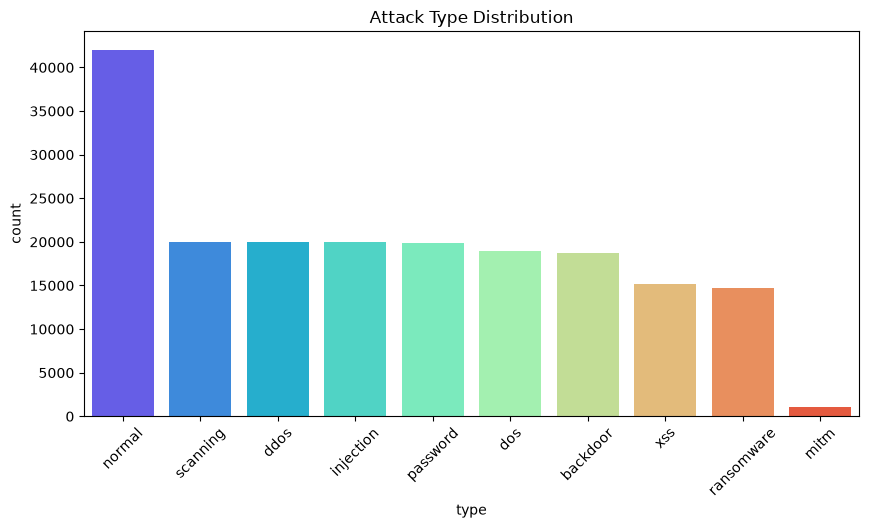

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,5))
sns.countplot(data = df, x = 'type', order = df['type'].value_counts().index, palette = 'rainbow')
plt.xticks(rotation = 45)
plt.title("Attack Type Distribution")
plt.show()

/tmp/ipykernel_1140/932559832.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data = df, x = 'proto', palette = "rainbow")


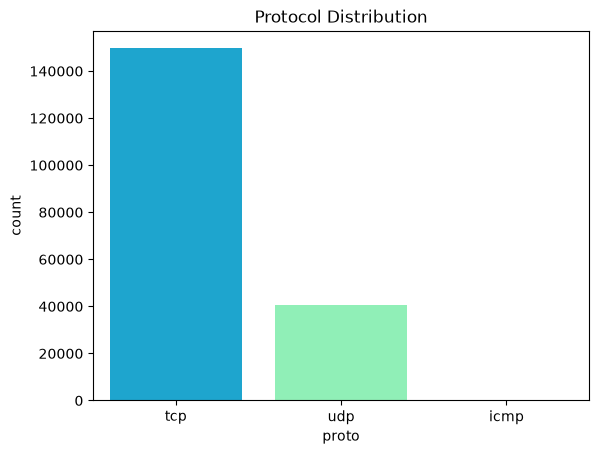

In [34]:
sns.countplot(data = df, x = 'proto', palette = "rainbow")
plt.title("Protocol Distribution")
plt.show()

/tmp/ipykernel_1140/3590121873.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data = df, x = 'service', palette = "rainbow")


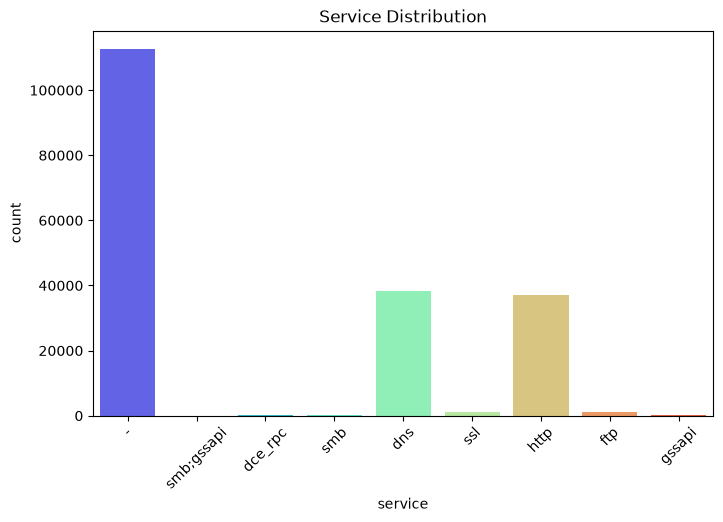

In [35]:
plt.figure(figsize = (8, 5))
sns.countplot(data = df, x = 'service', palette = "rainbow")
plt.title("Service Distribution")
plt.xticks(rotation = 45)
plt.show()

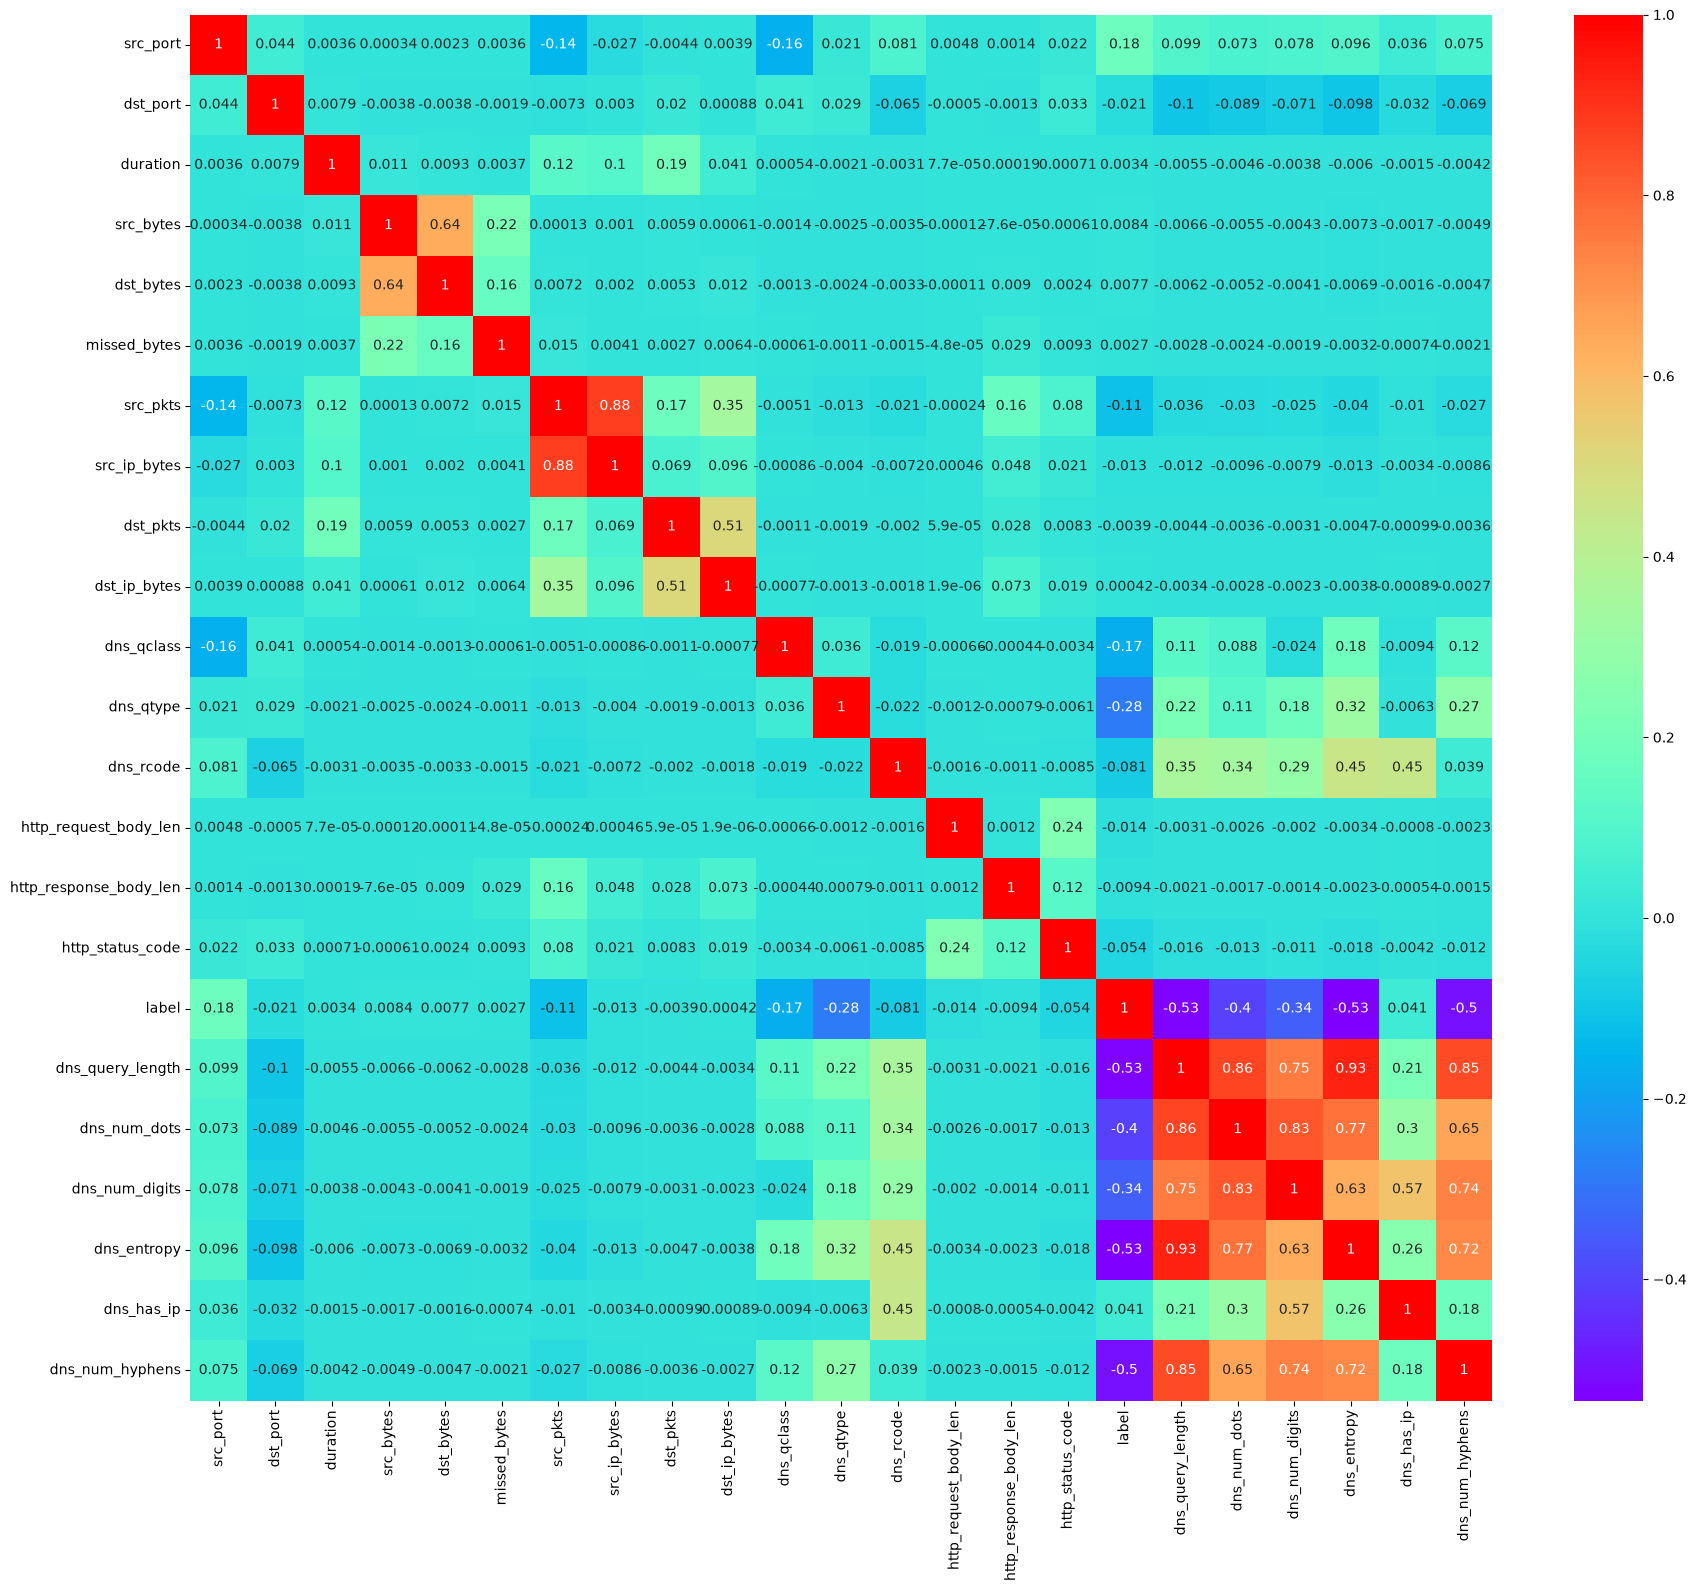

In [36]:
plt.figure(figsize = (21, 18))
sns.heatmap(df.select_dtypes(include = ['int64', 'float64']).corr(), annot = True, cmap = 'rainbow')
plt.show()

In [37]:
def make_Histogram(columnsName):
  plt.figure(figsize = (6, 4))
  sns.histplot(df[columnsName], bins = 30, kde = True)
  plt.title(columnsName)
  plt.show()

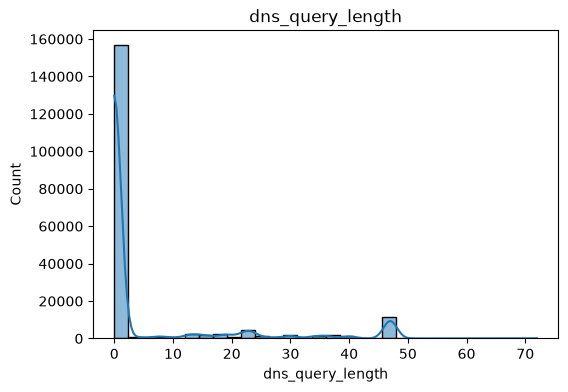

In [38]:
make_Histogram('dns_query_length')

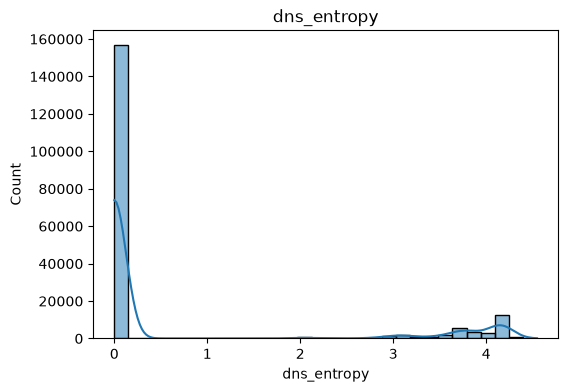

In [39]:
make_Histogram('dns_entropy')

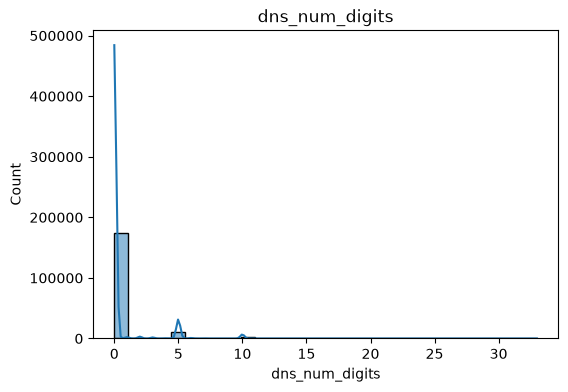

In [40]:
make_Histogram('dns_num_digits')

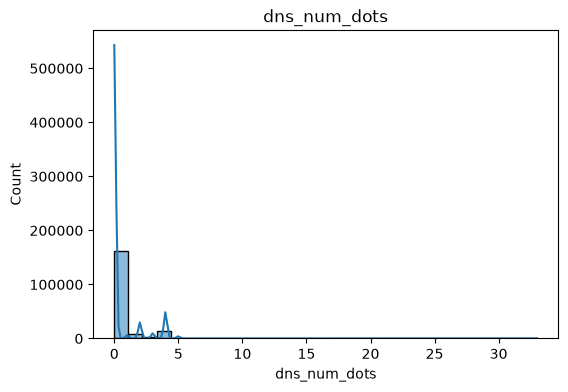

In [41]:
make_Histogram('dns_num_dots')

In [42]:
def make_Boxplot(xcol, ycol):
  plt.figure(figsize = (12, 5))
  sns.boxplot(data = df, x = xcol, y = ycol)
  plt.xticks(rotation = 45)
  plt.show()

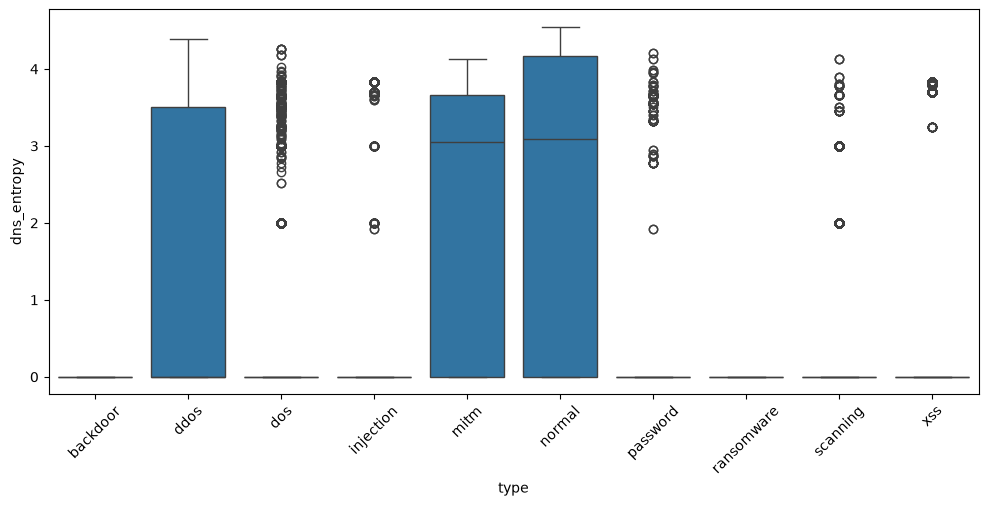

In [43]:
make_Boxplot('type', 'dns_entropy')

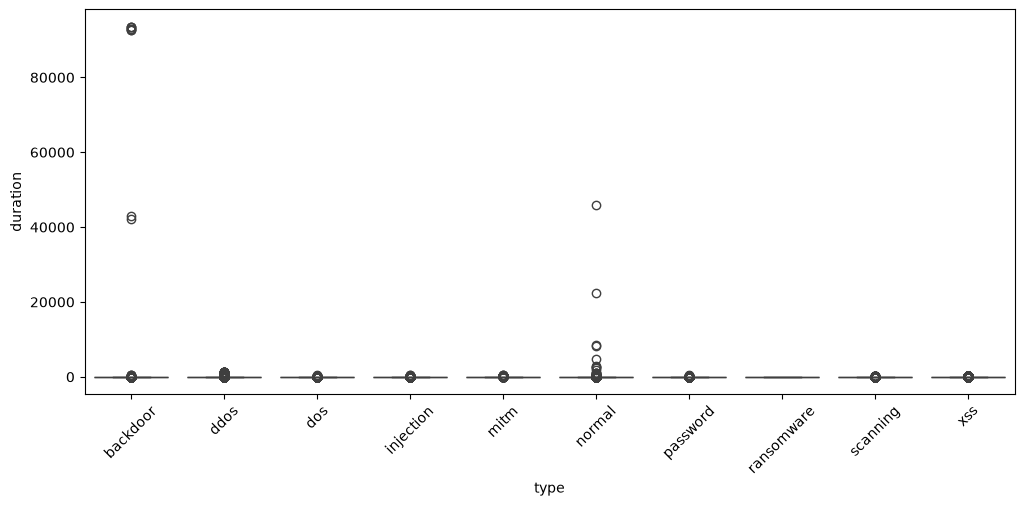

In [44]:
make_Boxplot('type', 'duration')

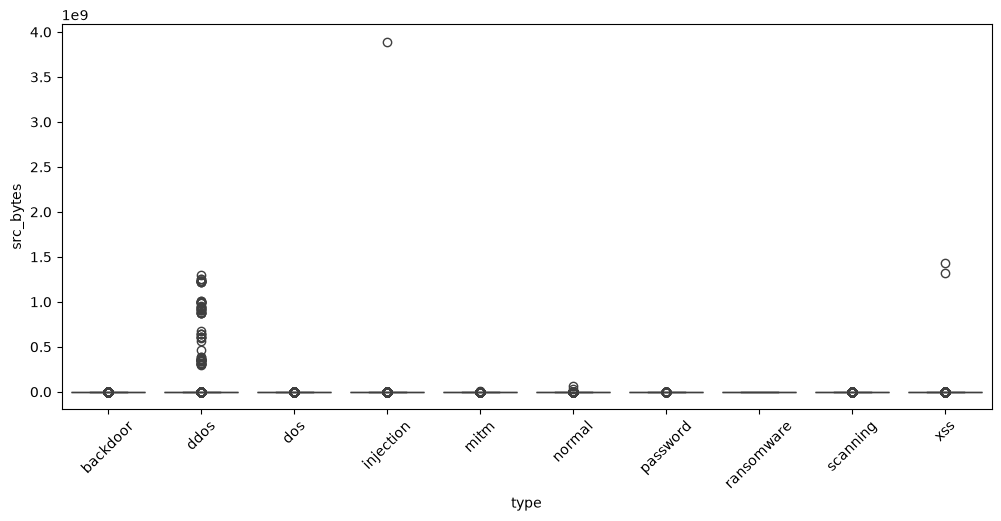

In [45]:
make_Boxplot('type', 'src_bytes')

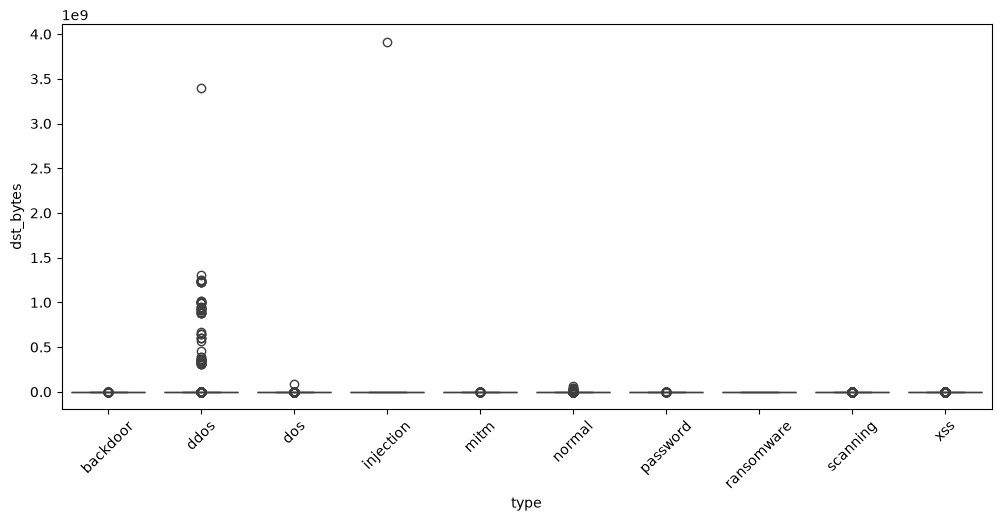

In [46]:
make_Boxplot('type', 'dst_bytes')

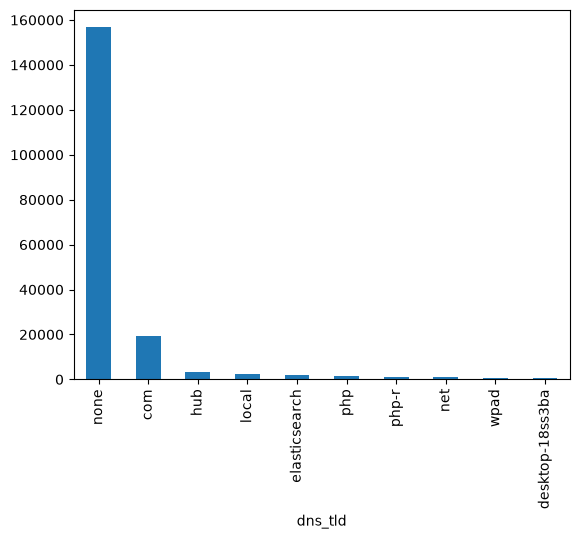

In [47]:
df['dns_tld'].value_counts().head(10).plot(kind = 'bar')
plt.show()

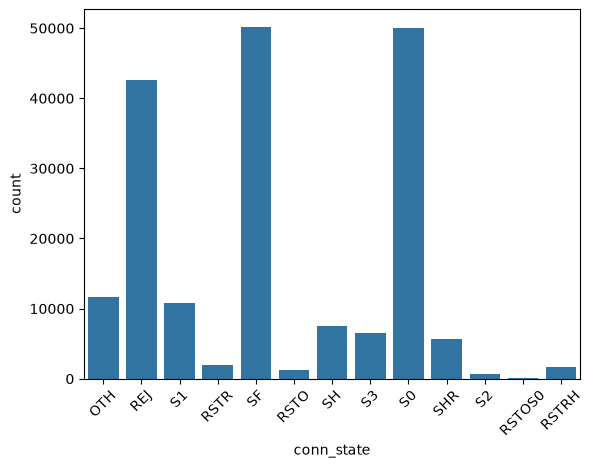

In [48]:
sns.countplot(data = df, x = 'conn_state')
plt.xticks(rotation = 45)
plt.show()

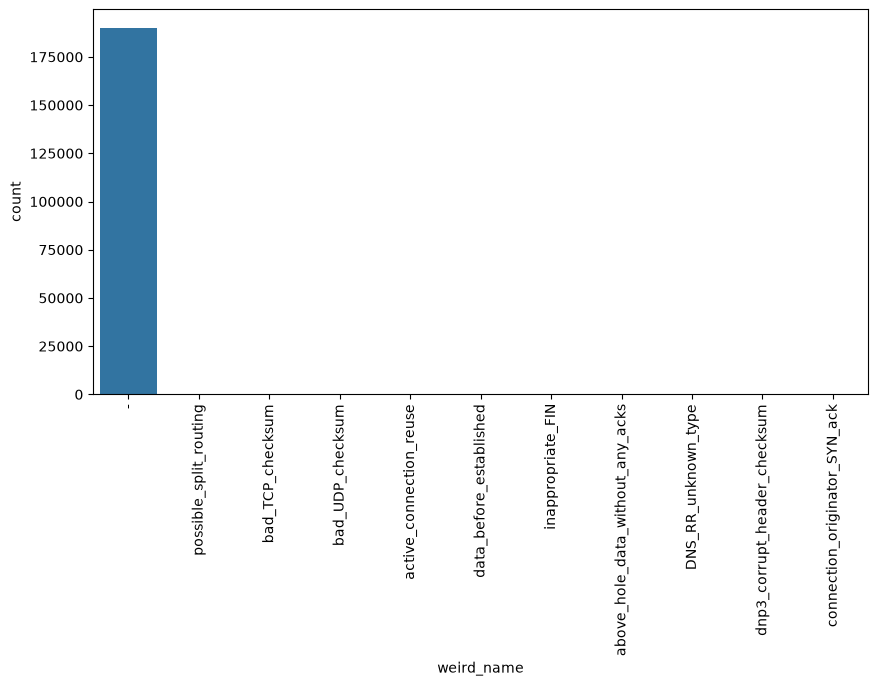

In [49]:
plt.figure(figsize = (10 ,5))
sns.countplot(data = df, x = 'weird_name')
plt.xticks(rotation = 90)
plt.show()

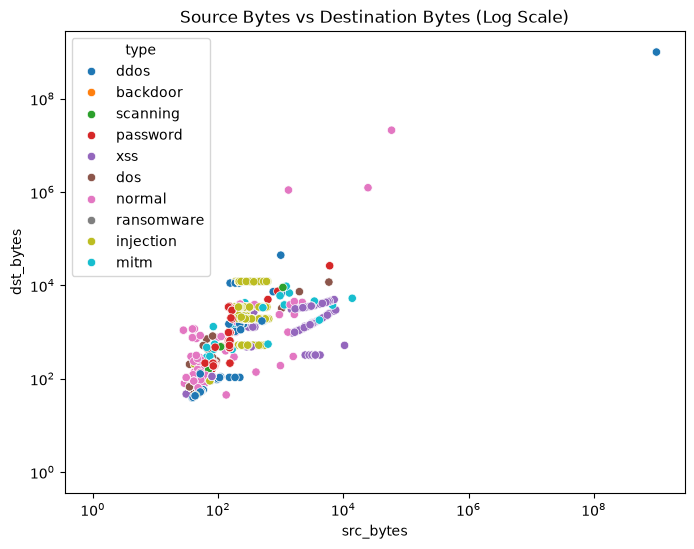

In [50]:
plt.figure(figsize = (8,6))
sns.scatterplot(
    data = df.sample(5000, random_state = 42),
    x = 'src_bytes',
    y = 'dst_bytes',
    hue = 'type'
)
plt.xscale('log')
plt.yscale('log')
plt.title("Source Bytes vs Destination Bytes (Log Scale)")
plt.show()

In [51]:
from sklearn.preprocessing import LabelEncoder

cols = ['proto', 'service', 'conn_state', 'dns_AA', 'dns_RD', 'dns_RA', 'dns_rejected', 'weird_name', 'weird_notice', 'dns_tld', 'dns_sld']
encoders = {}

for col in cols:
  encoder = LabelEncoder()
  df[col] = encoder.fit_transform(df[col])
  encoders[col] = encoder

target_encoder = LabelEncoder()
df['type'] = target_encoder.fit_transform(df['type'])

In [52]:
X = df.drop(['type', 'label'], axis = 1)
Y = df['type']

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size = 0.2,
    random_state = 42,
    stratify = Y
)

In [54]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from cuml.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from cuml.svm import SVC
from cuml.linear_model import LogisticRegression

dt = DecisionTreeClassifier(random_state = 42)
rf = RandomForestClassifier(random_state = 42)
xgb = XGBClassifier(random_state = 42, tree_method = 'hist', device = 'cuda', n_jobs = -1)
svm = SVC(random_state = 42, max_iter = 1000000, C = 200, kernel = 'rbf', gamma = 0.1)
lr = LogisticRegression(max_iter = 20000, C = 0.1, class_weight = None)

dt.fit(X_train, Y_train)
rf.fit(X_train, Y_train)
xgb.fit(X_train, Y_train)
svm.fit(X_train_scaled, Y_train)
lr.fit(X_train_scaled, Y_train)

LogisticRegression(C=0.1, max_iter=20000)

In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

models = {
    'Decision Tree' : dt,
    'Random Forest' : rf,
    'XGBoost' : xgb,
}

training_models = {
  'Support Vector Machine' : svm,
  'Logistic Regression' : lr
}

result = {}

for name, model in models.items():
  prediction = model.predict(X_test)
  accuracy = accuracy_score(Y_test, prediction)
  result[name] = accuracy

  print(name)
  print("Accuracy:", accuracy)
  print(classification_report(Y_test, prediction, zero_division = 0))

for name, model in training_models.items():
  prediction = model.predict(X_test_scaled)
  accuracy = accuracy_score(Y_test, prediction)
  result[name] = accuracy

  print(name)
  print("Accuracy:", accuracy)
  print(classification_report(Y_test, prediction, zero_division = 0))

Decision Tree
Accuracy: 0.9863236645229033
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      3742
           1       0.98      0.98      0.98      3999
           2       0.98      0.99      0.98      3799
           3       0.97      0.97      0.97      3993
           4       0.74      0.75      0.74       208
           5       1.00      1.00      1.00      8408
           6       0.99      0.99      0.99      3972
           7       1.00      1.00      1.00      2947
           8       0.99      0.99      0.99      4000
           9       0.96      0.96      0.96      3027

    accuracy                           0.99     38095
   macro avg       0.96      0.96      0.96     38095
weighted avg       0.99      0.99      0.99     38095

Random Forest
Accuracy: 0.9880824255151595
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      3742
           1       0.99      0.98      0.99   

/home/asim_azhar/miniforge3/envs/rapids/lib/python3.13/site-packages/xgboost/core.py:569: UserWarning: [19:15:33] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


Support Vector Machine
Accuracy: 0.9606510040687755
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      3742
           1       0.97      0.95      0.96      3999
           2       0.99      0.97      0.98      3799
           3       0.93      0.90      0.91      3993
           4       0.62      0.68      0.65       208
           5       0.99      0.99      0.99      8408
           6       0.95      0.98      0.96      3972
           7       0.97      0.98      0.97      2947
           8       0.94      0.95      0.94      4000
           9       0.89      0.91      0.90      3027

    accuracy                           0.96     38095
   macro avg       0.92      0.93      0.93     38095
weighted avg       0.96      0.96      0.96     38095

Logistic Regression
Accuracy: 0.7611235070219189
              precision    recall  f1-score   support

           0       0.66      0.99      0.80      3742
           1       0.72      0.

In [57]:
print(dict(enumerate(target_encoder.classes_)))

{0: 'backdoor', 1: 'ddos', 2: 'dos', 3: 'injection', 4: 'mitm', 5: 'normal', 6: 'password', 7: 'ransomware', 8: 'scanning', 9: 'xss'}


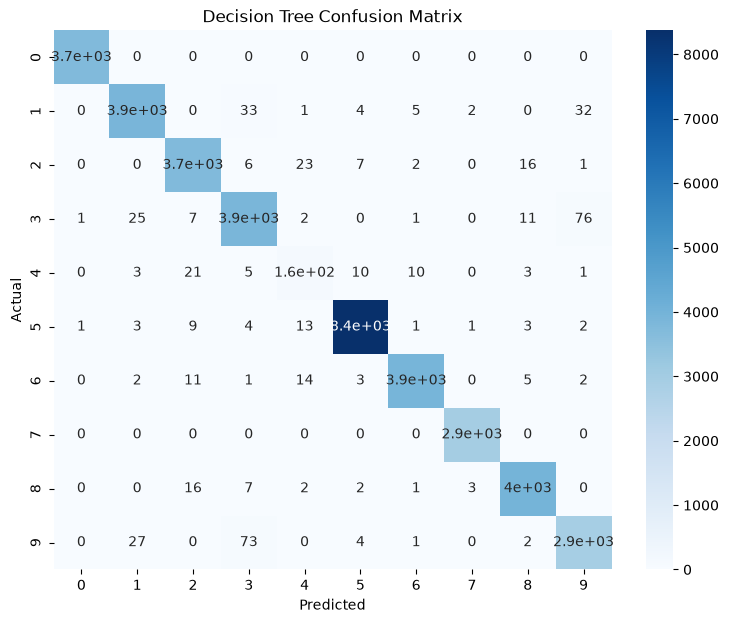

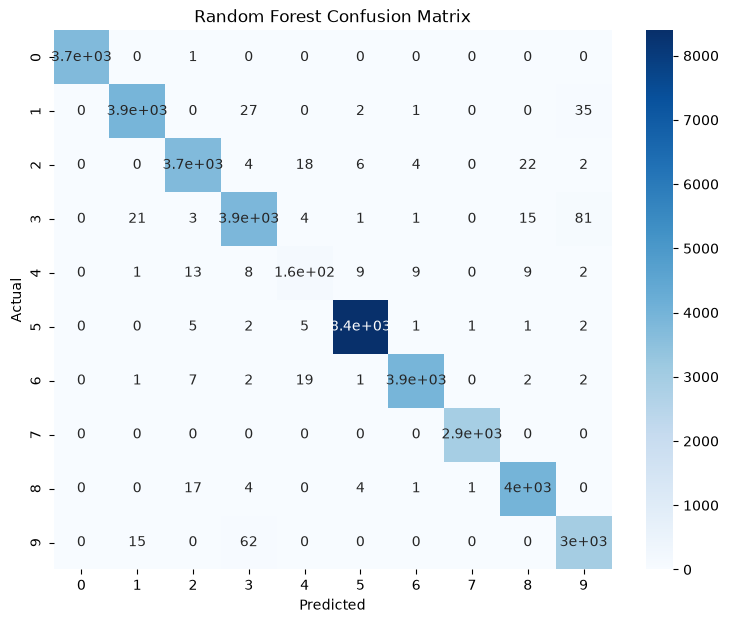

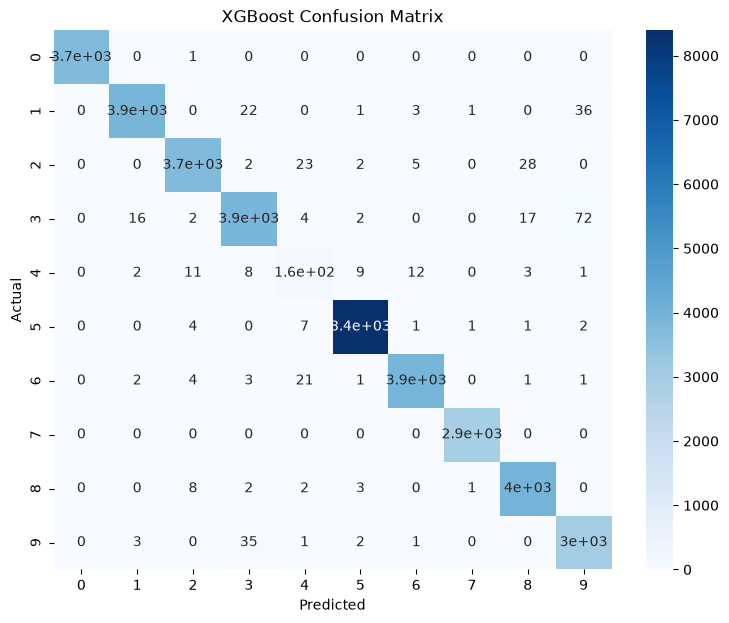

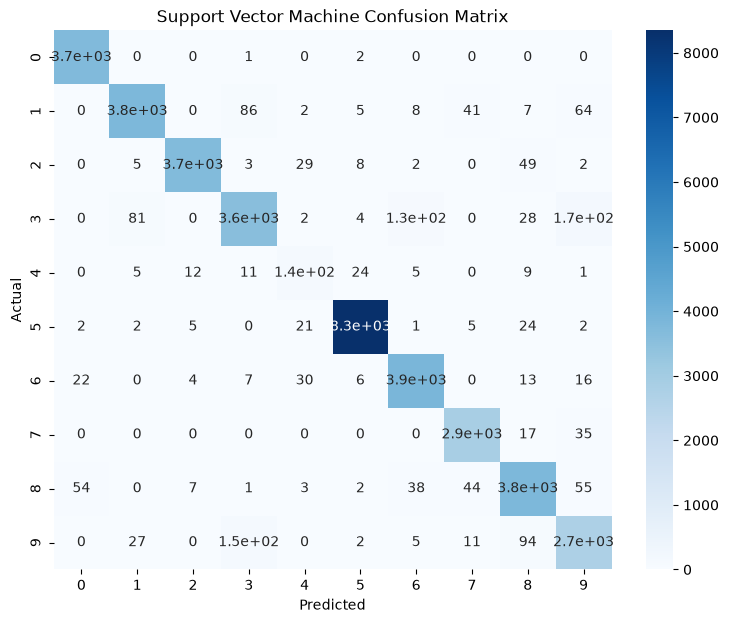

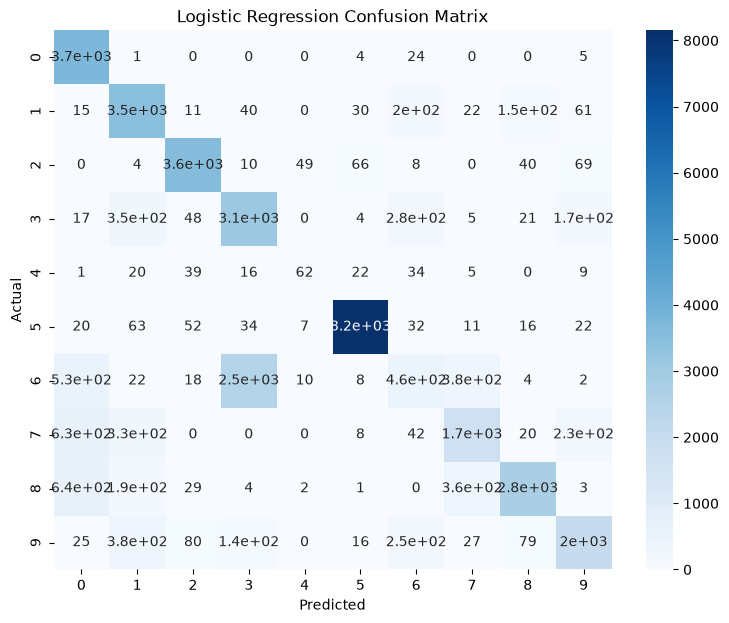

In [ ]:
for name, model in models.items():
  prediction = model.predict(X_test)
  cm = confusion_matrix(Y_test, prediction)
  plt.figure(figsize = (9, 7))
  sns.heatmap(cm, annot = True, cmap = 'Blues')
  plt.xlabel('Predicted')
  plt.ylabel('Actual')
  plt.title(f'{name} Confusion Matrix')
  plt.show()
  
for name, model in training_models.items():
  prediction = model.predict(X_test_scaled)
  cm = confusion_matrix(Y_test, prediction)
  plt.figure(figsize = (9, 7))
  sns.heatmap(cm, annot = True, cmap = 'Blues')
  plt.xlabel('Predicted')
  plt.ylabel('Actual')
  plt.title(f'{name} Confusion Matrix')
  plt.show()

In [59]:
def featureImportance(model):
    model_importance = model.feature_importances_

    importance = pd.Series(model_importance, index = X_train.columns).sort_values(ascending = False)
    return importance

def featureImportanceSvmLr(model):
    model_importance = model.feature_importances_

    importance = pd.Series(model_importance, index = X_train_scaled.columns).sort_values(ascending = False)
    return importance

In [60]:
print(featureImportance(xgb).head())

dns_rejected    0.265325
proto           0.203321
dns_RA          0.087111
conn_state      0.061451
service         0.061228
dtype: float32


In [ ]:
top_features = featureImportance(xgb).head(10).index.tolist()

X_train_top = X_train[top_features]
X_test_top = X_test[top_features]

xgb_top = XGBClassifier(random_state = 42, tree_method = 'hist', device = 'cuda', n_jobs = -1)

xgb_top.fit(X_train_top, Y_train)

prediction = xgb_top.predict(X_test_top)

print('Accuracy:', accuracy_score(Y_test, prediction))
print(classification_report(Y_test, prediction))

Accuracy: 0.9842236513978212
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      3742
           1       0.99      0.97      0.98      3999
           2       0.99      0.97      0.98      3799
           3       0.99      0.95      0.97      3993
           4       0.66      0.75      0.70       208
           5       0.99      0.99      0.99      8408
           6       1.00      0.99      0.99      3972
           7       1.00      1.00      1.00      2947
           8       0.98      1.00      0.99      4000
           9       0.93      0.99      0.96      3027

    accuracy                           0.98     38095
   macro avg       0.95      0.96      0.96     38095
weighted avg       0.98      0.98      0.98     38095



In [ ]:
feature_counts = [5, 10, 15, 20, len(featureImportance(xgb))]

results = []

for i in feature_counts:
    selected_features = featureImportance(xgb).head(i).index.tolist()

    X_train_selected = X_train[selected_features]
    X_test_selected = X_test[selected_features]

    model = XGBClassifier(random_state = 42)

    model.fit(X_train_selected, Y_train)

    prediction = model.predict(X_test_selected)

    accuracy = accuracy_score(Y_test, prediction)

    report = classification_report(Y_test, prediction, output_dict = True)

    macro_f1 = report['macro avg']['f1-score']
    mimt_f1 = report['4']['f1-score']

    results.append({
        'Features' : i,
        'Accuracy' : accuracy,
        'Macro F1' : macro_f1,
        'MITM F1' : mimt_f1
    })

results_df = pd.DataFrame(results)

print(results_df)

   Features  Accuracy  Macro F1   MITM F1
0         5  0.660874  0.579569  0.303951
1        10  0.984224  0.956776  0.704289
2        15  0.986507  0.962511  0.746479
3        20  0.989999  0.966727  0.753555
4        33  0.989920  0.967359  0.761021


In [ ]:
xgb = XGBClassifier(n_estimators = 310, tree_method = 'hist', device = 'cuda', n_jobs = -1, max_depth = 6, learning_rate = 0.1, random_state = 42)

xgb.fit(X_train, Y_train)

prediction = xgb.predict(X_test)

print('Accuracy:', accuracy_score(Y_test, prediction))
print(classification_report(Y_test, prediction))

Accuracy: 0.9902874392964957
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      3742
           1       0.99      0.98      0.99      3999
           2       0.99      0.98      0.99      3799
           3       0.98      0.97      0.98      3993
           4       0.75      0.82      0.78       208
           5       1.00      1.00      1.00      8408
           6       1.00      0.99      0.99      3972
           7       1.00      1.00      1.00      2947
           8       0.99      1.00      0.99      4000
           9       0.96      0.99      0.98      3027

    accuracy                           0.99     38095
   macro avg       0.97      0.97      0.97     38095
weighted avg       0.99      0.99      0.99     38095



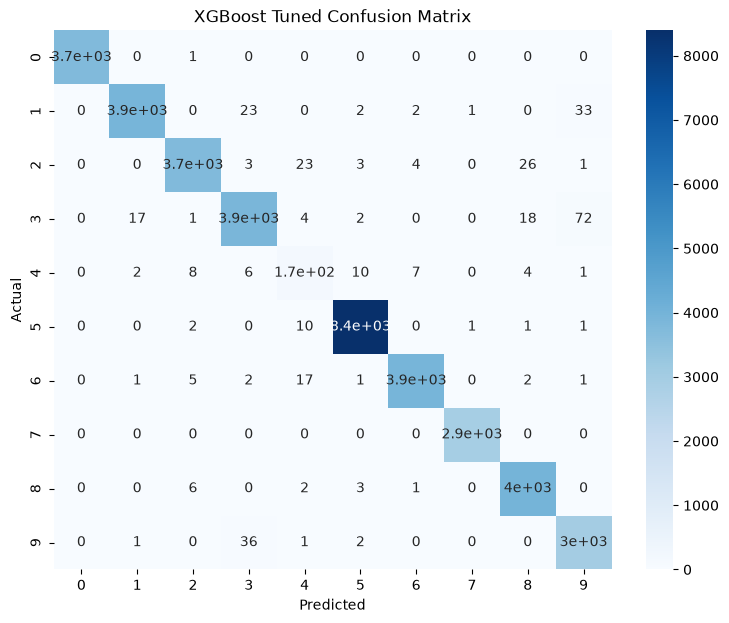

In [ ]:
cm = confusion_matrix(Y_test, prediction)
plt.figure(figsize = (9, 7))
sns.heatmap(cm, annot = True, cmap = 'Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('XGBoost Tuned Confusion Matrix')
plt.show()

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score
accuracy = accuracy_score(Y_test, prediction)
precision = precision_score(Y_test, prediction, average = 'macro')
recall = recall_score(Y_test, prediction, average = 'macro')
f1 = f1_score(Y_test, prediction, average = 'macro')

print('Accuracy:', accuracy)
print('Macro Prediction:', precision)
print('Macro Recall:', recall)
print('Macro F1:', f1)

Accuracy: 0.9902874392964957
Macro Prediction: 0.9664971806981836
Macro Recall: 0.9732143523067774
Macro F1: 0.9696833817372179


In [ ]:
actual_binary = (Y_test != 5).astype(int)
pred_binary = (prediction != 5).astype(int)

binary_cm = confusion_matrix(actual_binary, pred_binary)

TN, FP, FN, TP = binary_cm.ravel()

FPR = FP / (FP + TN)
FNR = FN / (FN + TP)

print('Binary Confusion Matrix:')
print(binary_cm)

print('FPR:', FPR)
print('FNR:', FNR)

print('FPR %:', FPR * 100)
print('FNR %:', FNR * 100)

Binary Confusion Matrix:
[[ 8393    15]
 [   23 29664]]
FPR: 0.0017840152235965748
FNR: 0.000774749890524472
FPR %: 0.17840152235965748
FNR %: 0.07747498905244721


In [67]:
import shap
explainer = shap.TreeExplainer(xgb)
shap_values = explainer.shap_values(X_test)

print(type(shap_values))
print(shap_values.shape)

<class 'numpy.ndarray'>
(38095, 33, 10)


In [68]:
import numpy as np

mean_shap = np.mean(np.abs(shap_values), axis = (0, 2))

shap_importance = pd.DataFrame({
    'Features' : X_test.columns,
    'Mean SHAP Value' : mean_shap
})

shap_importance = shap_importance.sort_values(by = 'Mean SHAP Value', ascending = False)

print(shap_importance)

                  Features  Mean SHAP Value
1                 dst_port         1.031247
0                 src_port         0.830036
4                 duration         0.792981
10            src_ip_bytes         0.788233
7               conn_state         0.680099
5                src_bytes         0.479265
12            dst_ip_bytes         0.332236
2                    proto         0.242813
9                 src_pkts         0.237054
3                  service         0.217843
6                dst_bytes         0.202977
11                dst_pkts         0.178045
31                 dns_sld         0.131797
28             dns_entropy         0.110803
18                  dns_RA         0.090202
25        dns_query_length         0.082766
17                  dns_RD         0.064827
29                 dns_tld         0.063307
32         dns_num_hyphens         0.049729
27          dns_num_digits         0.046689
19            dns_rejected         0.026905
15               dns_rcode      

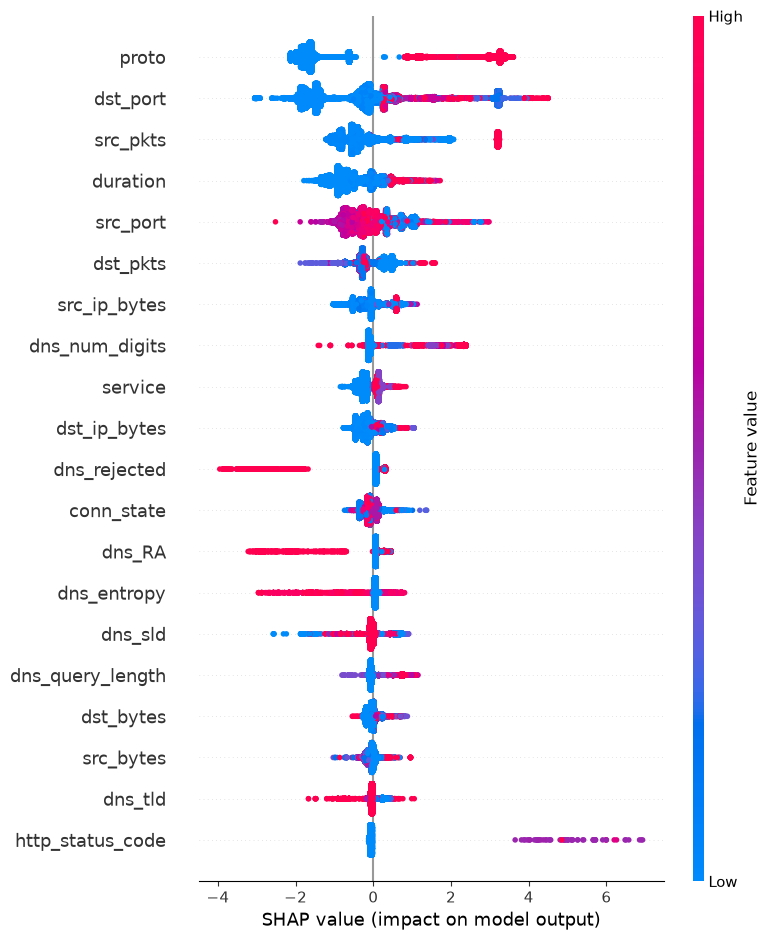

In [69]:
shap.summary_plot(shap_values[:, :, 5], X_test, max_display = 20)

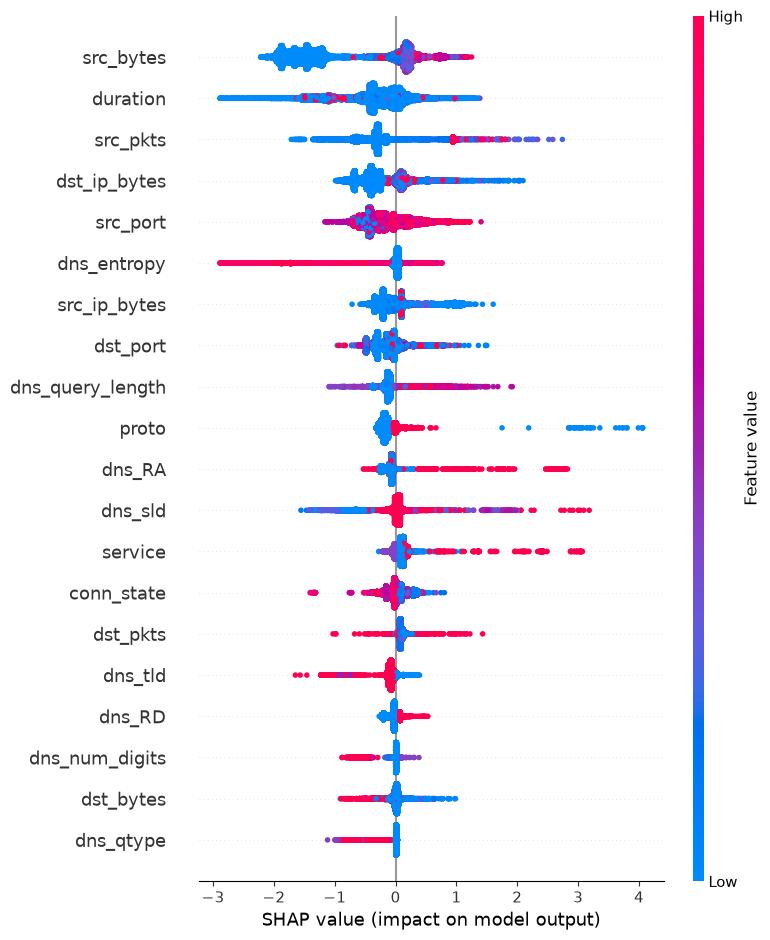

In [70]:
shap.summary_plot(shap_values[:, :, 4], X_test, max_display = 20)

In [ ]:
actual_mitm = (Y_test == 4)
predicted_mitm = (prediction == 4)

correct_mitm_indices = np.where(actual_mitm & predicted_mitm)[0]

print('Number of correctly classified MITM samples:', len(correct_mitm_indices))

correct_idx = correct_mitm_indices[0]

print('Test sample index:', correct_idx)
print('Actual class:', Y_test.iloc[correct_idx])
print('Predicted class:', prediction[correct_idx])

Number of correctly classified MITM samples: 170
Test sample index: 18
Actual class: 4
Predicted class: 4


In [72]:
shap.initjs()
shap.force_plot(explainer.expected_value[4], shap_values[correct_idx, :, 4], X_test.iloc[correct_idx], matplotlib = False)

In [ ]:
misclassified_mitm_indices = np.where((Y_test == 4) & (prediction != 4))[0]

print('Number of misclassified MITM samples:', len(misclassified_mitm_indices))

wrong_idx = misclassified_mitm_indices[0]

print('Test smaple index:', wrong_idx)
print('Actual class:', Y_test.iloc[wrong_idx])
print('Predicted class', prediction[wrong_idx])

Number of misclassified MITM samples: 38
Test smaple index: 6416
Actual class: 4
Predicted class 1


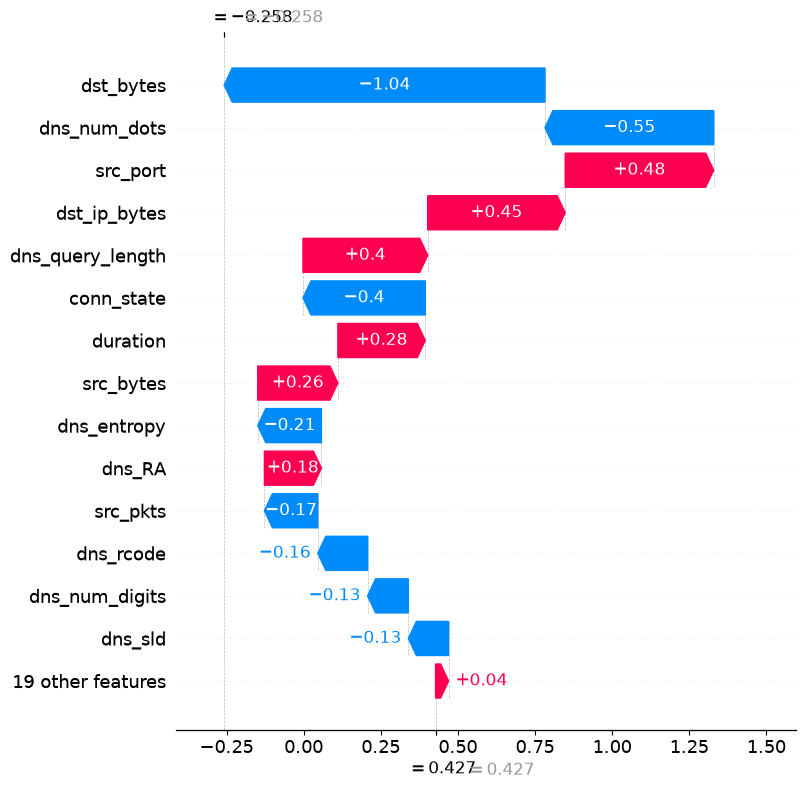

In [74]:
shap.plots._waterfall.waterfall_legacy(
    explainer.expected_value[1], 
    shap_values[wrong_idx, :, 1], 
    feature_names = X_test.columns, 
    max_display = 15
)

In [75]:
import os
import joblib

os.makedirs('TON_IoT_Models', exist_ok = True)

joblib.dump(xgb, 'TON_IoT_Models/xgboost_ton_iot.pkl')
joblib.dump(encoders, 'TON_IoT_Models/label_encoders.pkl')

feature_names = X_train.columns.tolist()

joblib.dump(feature_names, 'TON_IoT_Models/feature_names.pkl')
joblib.dump(target_encoder, 'TON_IoT_Models/class_mapping.pkl')

print('Model and preprocessing files saved successfully.')

Model and preprocessing files saved successfully.


TON_IoT Dataset Work done

CIC-IDS2017 Dataset

In [76]:
%reset -f

import gc
gc.collect()

0

In [77]:
import os
os.listdir('MachineLearningCVE')

['Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv',
 'Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv',
 'Friday-WorkingHours-Morning.pcap_ISCX.csv',
 'Monday-WorkingHours.pcap_ISCX.csv',
 'Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv',
 'Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv',
 'Tuesday-WorkingHours.pcap_ISCX.csv',
 'Wednesday-workingHours.pcap_ISCX.csv']

In [78]:
import pandas as pd

files = os.listdir('MachineLearningCVE')
csv_files = [file for file in files if file.endswith('.csv')]

for file in csv_files:
    file = 'MachineLearningCVE/' + file
    df_temp = pd.read_csv(file, usecols = [' Label'])
    
    print("\n" + "=" * 70)
    print(file)
    print(df_temp[' Label'].value_counts())


MachineLearningCVE/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
 Label
DDoS      128027
BENIGN     97718
Name: count, dtype: int64

MachineLearningCVE/Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
 Label
PortScan    158930
BENIGN      127537
Name: count, dtype: int64

MachineLearningCVE/Friday-WorkingHours-Morning.pcap_ISCX.csv
 Label
BENIGN    189067
Bot         1966
Name: count, dtype: int64

MachineLearningCVE/Monday-WorkingHours.pcap_ISCX.csv
 Label
BENIGN    529918
Name: count, dtype: int64

MachineLearningCVE/Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
 Label
BENIGN          288566
Infiltration        36
Name: count, dtype: int64

MachineLearningCVE/Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
 Label
BENIGN                        168186
Web Attack � Brute Force        1507
Web Attack � XSS                 652
Web Attack � Sql Injection        21
Name: count, dtype: int64

MachineLearningCVE/Tuesday-WorkingHours.pcap_ISCX.csv
 Label
BENIGN    

In [79]:
df = pd.DataFrame()

for file in files:
    df_temp = pd.read_csv('MachineLearningCVE/' + file)
    df = pd.concat([df, df_temp], ignore_index = True)
    del df_temp

df.shape

(2830743, 79)

In [80]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2830743 entries, 0 to 2830742
Data columns (total 79 columns):
 #   Column                        Dtype  
---  ------                        -----  
 0    Destination Port             int64  
 1    Flow Duration                int64  
 2    Total Fwd Packets            int64  
 3    Total Backward Packets       int64  
 4   Total Length of Fwd Packets   int64  
 5    Total Length of Bwd Packets  int64  
 6    Fwd Packet Length Max        int64  
 7    Fwd Packet Length Min        int64  
 8    Fwd Packet Length Mean       float64
 9    Fwd Packet Length Std        float64
 10  Bwd Packet Length Max         int64  
 11   Bwd Packet Length Min        int64  
 12   Bwd Packet Length Mean       float64
 13   Bwd Packet Length Std        float64
 14  Flow Bytes/s                  float64
 15   Flow Packets/s               float64
 16   Flow IAT Mean                float64
 17   Flow IAT Std                 float64
 18   Flow IAT Max                 int

In [81]:
df[' Label'].value_counts()

 Label
BENIGN                        2273097
DoS Hulk                       231073
PortScan                       158930
DDoS                           128027
DoS GoldenEye                   10293
FTP-Patator                      7938
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1966
Web Attack � Brute Force         1507
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64

In [82]:
df[' Label'].nunique()

15

In [83]:
df.columns = df.columns.str.strip()

print(df.columns.tolist())

['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'CWE Flag Count', 'ECE Flag Count

In [84]:
df.duplicated().sum()

np.int64(308381)

In [85]:
df.drop_duplicates(inplace = True)

In [86]:
df.duplicated().sum()

np.int64(0)

In [87]:
import numpy as np
np.isinf(df.select_dtypes(include = np.number)).sum().sum()

np.int64(2775)

In [88]:
df = df.replace([np.inf, -np.inf], np.nan)

In [89]:
np.isinf(df.select_dtypes(include = np.number)).sum().sum()

np.int64(0)

In [90]:
df.isnull().sum().sum()

np.int64(3128)

In [91]:
missing = df.isnull().sum()
print(missing[missing > 0].sort_values(ascending = False))

Flow Bytes/s      1564
Flow Packets/s    1564
dtype: int64


In [92]:
df['Flow Bytes/s'] = df['Flow Bytes/s'].fillna(df['Flow Bytes/s'].median())
df['Flow Packets/s'] = df['Flow Packets/s'].fillna(df['Flow Packets/s'].median())

In [93]:
df.isnull().sum().sum()

np.int64(0)

In [94]:
constant_cols = [col for col in df.columns if df[col].nunique() <= 1]

print(constant_cols)

['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate']


In [95]:
df.drop(columns = constant_cols, inplace = True)

In [96]:
print((df['Fwd Header Length'] == df['Fwd Header Length.1']).all())

True


In [97]:
df.drop('Fwd Header Length.1', axis = 1, inplace = True)

In [ ]:
df['Label'] = df['Label'].replace({
    'Web Attack � Brute Force': 'Web Attack - Brute Force',
    'Web Attack � XSS': 'Web Attack - XSS',
    'Web Attack � Sql Injection': 'Web Attack - Sql Injection'
})

In [99]:
df['Label'].unique()

<ArrowStringArray>
[                    'BENIGN',                       'DDoS',
                   'PortScan',                        'Bot',
               'Infiltration',   'Web Attack - Brute Force',
           'Web Attack - XSS', 'Web Attack - Sql Injection',
                'FTP-Patator',                'SSH-Patator',
              'DoS slowloris',           'DoS Slowhttptest',
                   'DoS Hulk',              'DoS GoldenEye',
                 'Heartbleed']
Length: 15, dtype: str

In [100]:
df.shape

(2522362, 70)

In [101]:
df.describe()

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,act_data_pkt_fwd,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min
count,2.522362e+06,2.522362e+06,2.522362e+06,2.522362e+06,2.522362e+06,2.522362e+06,2.522362e+06,2.522362e+06,2.522362e+06,2.522362e+06,...,2.522362e+06,2.522362e+06,2.522362e+06,2.522362e+06,2.522362e+06,2.522362e+06,2.522362e+06,2.522362e+06,2.522362e+06,2.522362e+06
mean,8.704762e+03,1.658132e+07,1.027627e+01,1.156596e+01,6.115751e+02,1.813315e+04,2.310918e+02,1.919464e+01,6.347010e+01,7.727759e+01,...,6.005904e+00,-3.080307e+03,9.152169e+04,4.616313e+04,1.719104e+05,6.542300e+04,9.331578e+06,5.654433e+05,9.757716e+06,8.887157e+06
std,1.902507e+04,3.522426e+07,7.941738e+02,1.056594e+03,1.058499e+04,2.397434e+06,7.561625e+02,6.079447e+01,1.955015e+02,2.967953e+02,...,6.742059e+02,1.149402e+06,6.864412e+05,4.164568e+05,1.085243e+06,6.109712e+05,2.484157e+07,4.872678e+06,2.561067e+07,2.457481e+07
min,0.000000e+00,-1.300000e+01,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,...,0.000000e+00,-5.368707e+08,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,5.300000e+01,2.080000e+02,2.000000e+00,1.000000e+00,1.200000e+01,6.000000e+00,6.000000e+00,0.000000e+00,6.000000e+00,0.000000e+00,...,0.000000e+00,2.000000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,8.000000e+01,5.057700e+04,2.000000e+00,2.000000e+00,6.600000e+01,1.550000e+02,4.000000e+01,2.000000e+00,3.611111e+01,0.000000e+00,...,1.000000e+00,2.000000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,4.430000e+02,5.329717e+06,6.000000e+00,5.000000e+00,3.320000e+02,9.880000e+02,2.020000e+02,3.700000e+01,5.200000e+01,7.413913e+01,...,3.000000e+00,3.200000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
max,6.553500e+04,1.200000e+08,2.197590e+05,2.919220e+05,1.290000e+07,6.554530e+08,2.482000e+04,2.325000e+03,5.940857e+03,7.125597e+03,...,2.135570e+05,1.380000e+02,1.100000e+08,7.420000e+07,1.100000e+08,1.100000e+08,1.200000e+08,7.690000e+07,1.200000e+08,1.200000e+08


In [102]:
X = df.drop('Label', axis = 1)
Y = df['Label']

print(X.shape)
print(Y.shape)

(2522362, 69)
(2522362,)


In [103]:
from sklearn.preprocessing import LabelEncoder

target_encoder = LabelEncoder()
Y = target_encoder.fit_transform(Y)
print(dict(enumerate(target_encoder.classes_)))

{0: 'BENIGN', 1: 'Bot', 2: 'DDoS', 3: 'DoS GoldenEye', 4: 'DoS Hulk', 5: 'DoS Slowhttptest', 6: 'DoS slowloris', 7: 'FTP-Patator', 8: 'Heartbleed', 9: 'Infiltration', 10: 'PortScan', 11: 'SSH-Patator', 12: 'Web Attack - Brute Force', 13: 'Web Attack - Sql Injection', 14: 'Web Attack - XSS'}


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size = 0.2,
    random_state = 42,
    stratify = Y
)

In [105]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from cuml.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from cuml.svm import SVC
from cuml.linear_model import LogisticRegression

model_train = lambda model : model.fit(X_train_scaled, Y_train)

dt = DecisionTreeClassifier(random_state = 42)
rf = RandomForestClassifier(random_state = 42)
xgb = XGBClassifier(random_state = 42, tree_method = 'hist', device = 'cuda', n_jobs = -1)
svm = SVC(random_state = 42, max_iter = 1000000, C = 200, kernel = 'rbf', gamma = 0.1)
lr = LogisticRegression(max_iter = 20000, C = 0.1, class_weight = None)

dt.fit(X_train, Y_train)
rf.fit(X_train, Y_train)
xgb.fit(X_train, Y_train)
svm.fit(X_train_scaled, Y_train)
lr.fit(X_train_scaled, Y_train)

LogisticRegression(C=0.1, max_iter=20000)

In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

models = {
    'Decision Tree' : dt,
    'Random Forest' : rf,
    'XGBoost' : xgb
}

training_models = {
    'SVM' : svm,
    'Logistic Regression' : lr
}

result = {}

for name, model in models.items():
    prediction = model.predict(X_test)
    accuracy = accuracy_score(Y_test, prediction)
    result[name] = accuracy

    print(name)
    print('Accuracy:', accuracy)
    print(classification_report(Y_test, prediction, zero_division = 0))

for name, model in training_models.items():
    prediction = model.predict(X_test_scaled)
    accuracy = accuracy_score(Y_test, prediction)
    result[name] = accuracy

    print(name)
    print('Accuracy:', accuracy)
    print(classification_report(Y_test, prediction, zero_division = 0))

Decision Tree
Accuracy: 0.998124775756086
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    419297
           1       0.83      0.83      0.83       391
           2       1.00      1.00      1.00     25603
           3       1.00      0.99      0.99      2057
           4       1.00      1.00      1.00     34570
           5       0.98      0.99      0.99      1046
           6       1.00      0.99      0.99      1077
           7       1.00      1.00      1.00      1187
           8       1.00      1.00      1.00         2
           9       0.83      0.71      0.77         7
          10       0.99      0.98      0.99     18164
          11       1.00      1.00      1.00       644
          12       0.75      0.69      0.72       294
          13       0.50      0.50      0.50         4
          14       0.41      0.52      0.46       130

    accuracy                           1.00    504473
   macro avg       0.89      0.88     

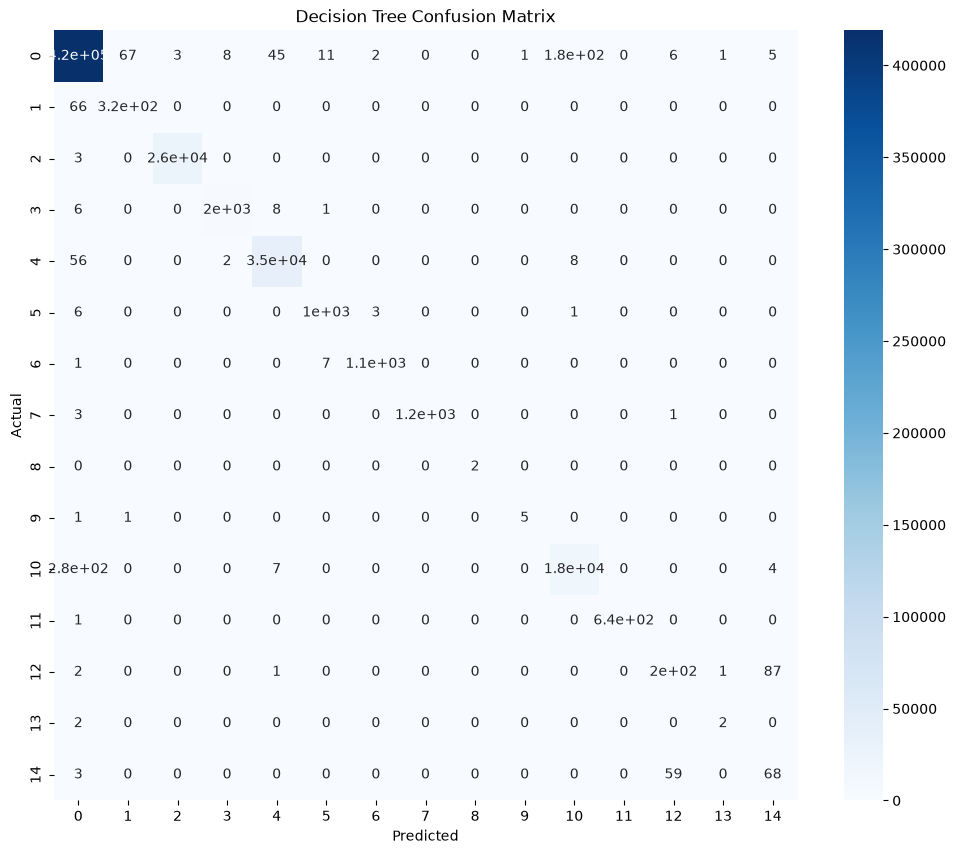

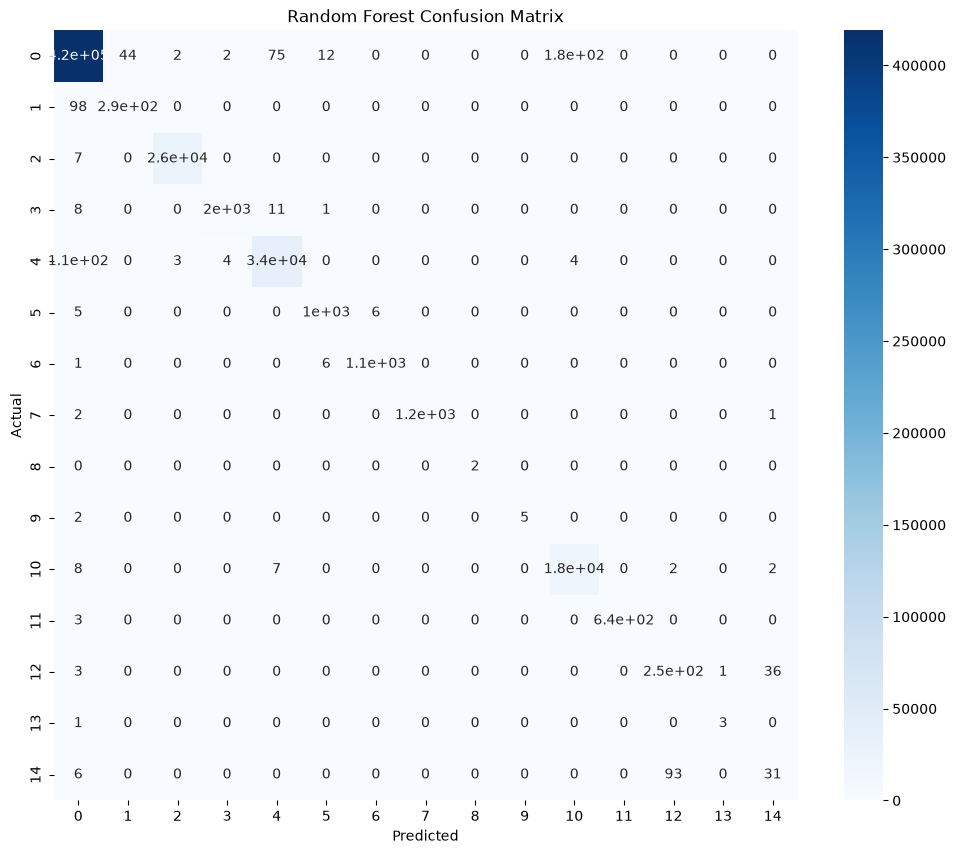

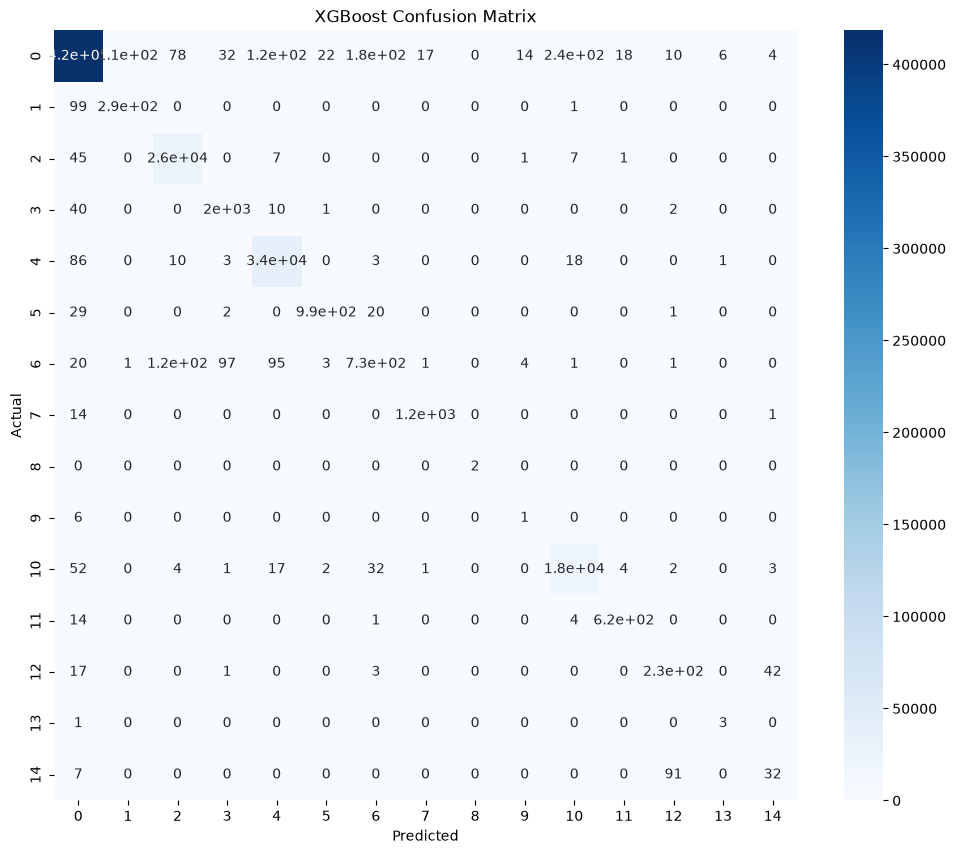

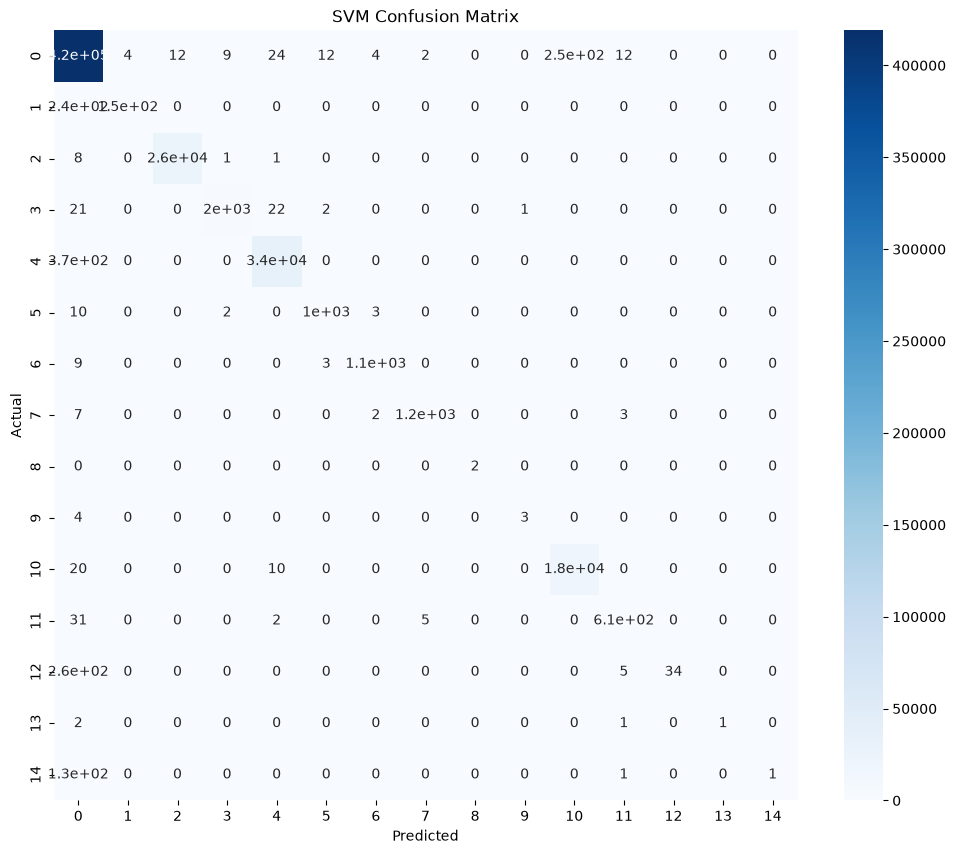

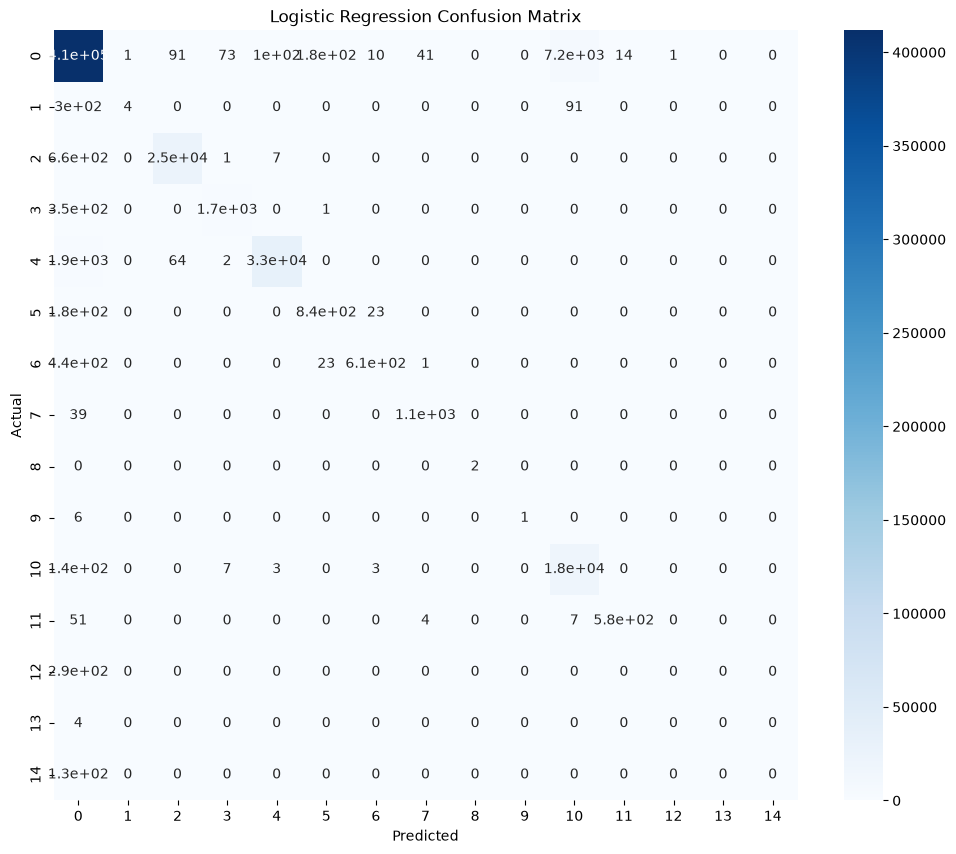

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

for name, model in models.items():
  prediction = model.predict(X_test)
  cm = confusion_matrix(Y_test, prediction)
  plt.figure(figsize = (12, 10))
  sns.heatmap(cm, annot = True, cmap = 'Blues')
  plt.xlabel('Predicted')
  plt.ylabel('Actual')
  plt.title(f'{name} Confusion Matrix')
  plt.show()
  
for name, model in training_models.items():
  prediction = model.predict(X_test_scaled)
  cm = confusion_matrix(Y_test, prediction)
  plt.figure(figsize = (12, 10))
  sns.heatmap(cm, annot = True, cmap = 'Blues')
  plt.xlabel('Predicted')
  plt.ylabel('Actual')
  plt.title(f'{name} Confusion Matrix')
  plt.show()

                    Feature  Importance
     Bwd Packet Length Mean    0.066785
      Bwd Packet Length Std    0.062864
        Average Packet Size    0.055094
     Packet Length Variance    0.048398
          Packet Length Std    0.046689
       Avg Bwd Segment Size    0.045146
Total Length of Fwd Packets    0.035242
      Bwd Packet Length Max    0.032488
          Subflow Fwd Bytes    0.031710
          Subflow Bwd Bytes    0.031036
      Fwd Packet Length Max    0.030031
Total Length of Bwd Packets    0.028722
          Max Packet Length    0.022604
           Destination Port    0.022202
        Subflow Fwd Packets    0.019821
       Avg Fwd Segment Size    0.018758
         Packet Length Mean    0.018183
                   Idle Max    0.017415
          Total Fwd Packets    0.017399
          Fwd Header Length    0.016825


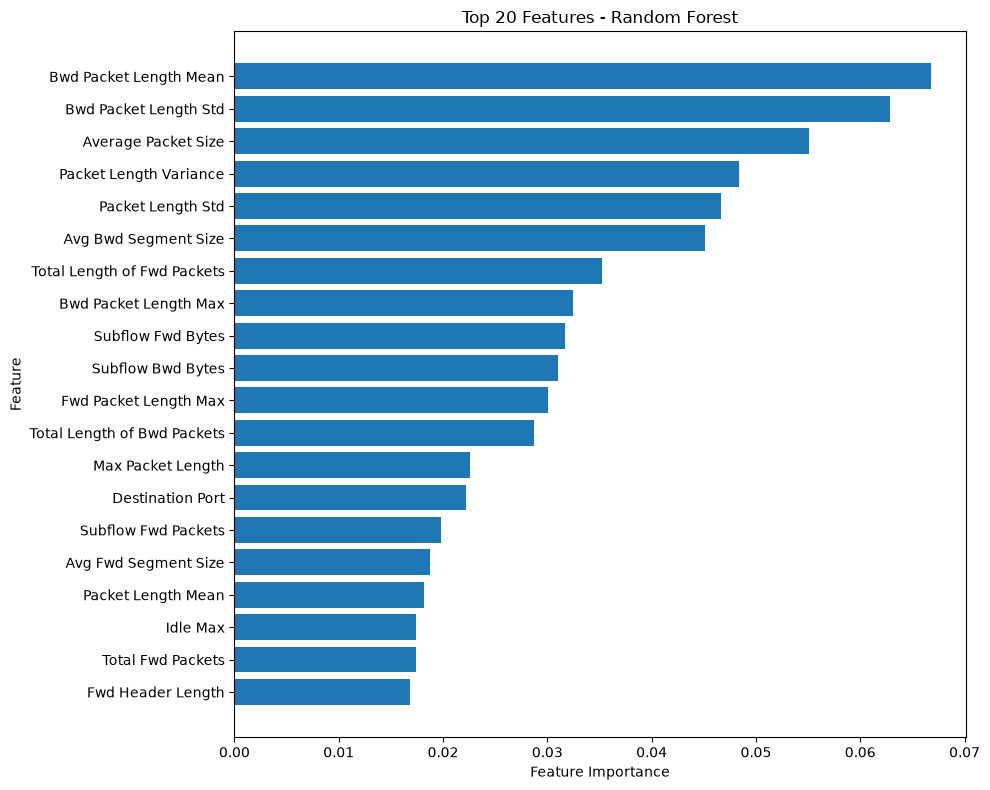

In [ ]:
import matplotlib.pyplot as plt

importances = rf.feature_importances_

feature_importance = pd.DataFrame({
    'Feature' : X_train.columns,
    'Importance' : importances
})

feature_importance = feature_importance.sort_values(by = 'Importance', ascending = False)

print(feature_importance.head(20).to_string(index = False))

top20 = feature_importance.head(20).sort_values(by = 'Importance', ascending = True)

plt.figure(figsize = (10, 8)) 
plt.barh(top20['Feature'], top20['Importance'])
plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Top 20 Features - Random Forest')
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

top20_features = feature_importance.head(20)['Feature'].tolist()

X_train_top = X_train[top20_features]
X_test_top = X_test[top20_features]

rf_top = RandomForestClassifier(random_state = 42)

rf_top.fit(X_train_top, Y_train)

predict = rf_top.predict(X_test_top)

accuracy = accuracy_score(Y_test, predict)
print('Accuracy:', accuracy)
print(classification_report(Y_test, predict))

Accuracy: 0.9966360935074821
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    419297
           1       1.00      0.39      0.56       391
           2       1.00      1.00      1.00     25603
           3       1.00      0.97      0.98      2057
           4       1.00      0.99      0.99     34570
           5       0.98      0.99      0.99      1046
           6       0.99      1.00      0.99      1077
           7       1.00      0.99      1.00      1187
           8       1.00      1.00      1.00         2
           9       1.00      0.86      0.92         7
          10       0.99      1.00      0.99     18164
          11       1.00      0.95      0.97       644
          12       1.00      0.10      0.17       294
          13       1.00      0.25      0.40         4
          14       1.00      0.01      0.02       130

    accuracy                           1.00    504473
   macro avg       1.00      0.77      0.80    5044

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

top30_features = feature_importance.head(30)['Feature'].tolist()

X_train_top = X_train[top30_features]
X_test_top = X_test[top30_features]

rf_top = RandomForestClassifier(random_state = 42)

rf_top.fit(X_train_top, Y_train)

predict = rf_top.predict(X_test_top)

accuracy = accuracy_score(Y_test, predict)
print('Accuracy:', accuracy)
print(classification_report(Y_test, predict))

Accuracy: 0.9978690633591887
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    419297
           1       0.88      0.75      0.81       391
           2       1.00      1.00      1.00     25603
           3       1.00      0.99      0.99      2057
           4       1.00      1.00      1.00     34570
           5       0.98      0.99      0.99      1046
           6       1.00      0.99      0.99      1077
           7       1.00      1.00      1.00      1187
           8       1.00      1.00      1.00         2
           9       1.00      0.71      0.83         7
          10       0.99      1.00      0.99     18164
          11       1.00      1.00      1.00       644
          12       0.79      0.11      0.20       294
          13       1.00      0.25      0.40         4
          14       0.50      0.02      0.04       130

    accuracy                           1.00    504473
   macro avg       0.94      0.79      0.82    5044

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

top40_features = feature_importance.head(40)['Feature'].tolist()

X_train_top = X_train[top40_features]
X_test_top = X_test[top40_features]

rf_top = RandomForestClassifier(random_state = 42)

rf_top.fit(X_train_top, Y_train)

predict = rf_top.predict(X_test_top)

accuracy = accuracy_score(Y_test, predict)
print('Accuracy:', accuracy)
print(classification_report(Y_test, predict))

Accuracy: 0.998124775756086
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    419297
           1       0.92      0.74      0.82       391
           2       1.00      1.00      1.00     25603
           3       1.00      0.99      0.99      2057
           4       1.00      1.00      1.00     34570
           5       0.98      0.99      0.99      1046
           6       1.00      0.99      1.00      1077
           7       1.00      1.00      1.00      1187
           8       1.00      1.00      1.00         2
           9       1.00      0.71      0.83         7
          10       0.99      1.00      0.99     18164
          11       1.00      1.00      1.00       644
          12       0.79      0.25      0.38       294
          13       1.00      0.50      0.67         4
          14       0.60      0.02      0.04       130

    accuracy                           1.00    504473
   macro avg       0.95      0.81      0.85    50447

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

top50_features = feature_importance.head(50)['Feature'].tolist()

X_train_top = X_train[top50_features]
X_test_top = X_test[top50_features]

rf_top = RandomForestClassifier(random_state = 42)

rf_top.fit(X_train_top, Y_train)

predict = rf_top.predict(X_test_top)

accuracy = accuracy_score(Y_test, predict)
print('Accuracy:', accuracy)
print(classification_report(Y_test, predict))

Accuracy: 0.99853708721775
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    419297
           1       0.91      0.73      0.81       391
           2       1.00      1.00      1.00     25603
           3       1.00      0.99      0.99      2057
           4       1.00      1.00      1.00     34570
           5       0.98      0.99      0.99      1046
           6       1.00      0.99      1.00      1077
           7       1.00      1.00      1.00      1187
           8       1.00      1.00      1.00         2
           9       1.00      0.71      0.83         7
          10       0.99      1.00      0.99     18164
          11       1.00      1.00      1.00       644
          12       0.73      0.85      0.78       294
          13       0.50      0.50      0.50         4
          14       0.45      0.25      0.33       130

    accuracy                           1.00    504473
   macro avg       0.90      0.87      0.88    504473

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

top60_features = feature_importance.head(60)['Feature'].tolist()

X_train_top = X_train[top60_features]
X_test_top = X_test[top60_features]

rf_top = RandomForestClassifier(random_state = 42)

rf_top.fit(X_train_top, Y_train)

predict = rf_top.predict(X_test_top)

accuracy = accuracy_score(Y_test, predict)
print('Accuracy:', accuracy)
print(classification_report(Y_test, predict))

Accuracy: 0.9985172645513238
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    419297
           1       0.87      0.73      0.80       391
           2       1.00      1.00      1.00     25603
           3       1.00      0.99      0.99      2057
           4       1.00      1.00      1.00     34570
           5       0.98      0.99      0.99      1046
           6       0.99      0.99      0.99      1077
           7       1.00      1.00      1.00      1187
           8       1.00      1.00      1.00         2
           9       1.00      0.71      0.83         7
          10       0.99      1.00      0.99     18164
          11       1.00      1.00      1.00       644
          12       0.73      0.86      0.79       294
          13       0.75      0.75      0.75         4
          14       0.44      0.24      0.31       130

    accuracy                           1.00    504473
   macro avg       0.92      0.88      0.90    5044

In [ ]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Training labels:", Y_train.shape)
print("Testing labels:", Y_test.shape)

print("\nClass distribution in training data:")
print(pd.Series(Y_train).value_counts().sort_index())

Training data: (2017889, 69)
Testing data: (504473, 69)
Training labels: (2017889,)
Testing labels: (504473,)

Class distribution in training data:
0     1677187
1        1562
2      102413
3        8229
4      138279
5        4182
6        4308
7        4746
8           9
9          29
10      72655
11       2575
12       1176
13         17
14        522
Name: count, dtype: int64


In [ ]:
X_tune_train, X_val, Y_tune_train, Y_val = train_test_split(
    X_train,
    Y_train,
    test_size = 0.1,
    random_state = 42,
    stratify = Y_train
)

print("Tuning training set:", X_tune_train.shape)
print("Validation set:", X_val.shape)

print("\nValidation class distribution:")
print(pd.Series(Y_val).value_counts().sort_index())

Tuning training set: (1816100, 69)
Validation set: (201789, 69)

Validation class distribution:
0     167719
1        156
2      10241
3        823
4      13828
5        418
6        431
7        475
8          1
9          3
10      7265
11       257
12       118
13         2
14        52
Name: count, dtype: int64


In [ ]:
print("Training distribution:")
print(pd.Series(Y_train).value_counts().sort_index())

print("\nValidation distribution:")
print(pd.Series(Y_val).value_counts().sort_index())

Training distribution:
0     1677187
1        1562
2      102413
3        8229
4      138279
5        4182
6        4308
7        4746
8           9
9          29
10      72655
11       2575
12       1176
13         17
14        522
Name: count, dtype: int64

Validation distribution:
0     167719
1        156
2      10241
3        823
4      13828
5        418
6        431
7        475
8          1
9          3
10      7265
11       257
12       118
13         2
14        52
Name: count, dtype: int64


In [123]:
rf_unweighted = RandomForestClassifier(n_estimators = 200, max_depth = 24, max_features = 1.0, random_state = 42)
rf_unweighted.fit(X_tune_train, Y_tune_train)
unweighted_predict = rf_unweighted.predict(X_val)
print('Accuracy:', accuracy_score(Y_val, unweighted_predict))
print(classification_report(Y_val, unweighted_predict, zero_division = 0))

Accuracy: 0.9985479882451471
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    167719
           1       0.93      0.75      0.83       156
           2       1.00      1.00      1.00     10241
           3       1.00      1.00      1.00       823
           4       1.00      1.00      1.00     13828
           5       1.00      0.98      0.99       418
           6       0.99      0.99      0.99       431
           7       1.00      1.00      1.00       475
           8       1.00      1.00      1.00         1
           9       1.00      1.00      1.00         3
          10       0.99      1.00      0.99      7265
          11       1.00      1.00      1.00       257
          12       0.69      0.81      0.74       118
          13       0.50      0.50      0.50         2
          14       0.31      0.21      0.25        52

    accuracy                           1.00    201789
   macro avg       0.89      0.88      0.89    2017

In [124]:
rf_weighted = RandomForestClassifier(n_estimators = 200, max_depth = 24, max_features = 1.0, class_weight = 'balanced', random_state = 42)
rf_weighted.fit(X_tune_train, Y_tune_train)
weighted_predict = rf_weighted.predict(X_val)
print('Accuracy:', accuracy_score(Y_val, weighted_predict))
print(classification_report(Y_val, weighted_predict, zero_division = 0))

Accuracy: 0.9974973858832741
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    167719
           1       0.57      0.99      0.72       156
           2       1.00      1.00      1.00     10241
           3       0.97      1.00      0.98       823
           4       0.99      1.00      1.00     13828
           5       0.96      0.99      0.98       418
           6       0.96      0.99      0.97       431
           7       0.99      1.00      1.00       475
           8       1.00      1.00      1.00         1
           9       0.60      1.00      0.75         3
          10       0.99      1.00      0.99      7265
          11       1.00      1.00      1.00       257
          12       0.64      0.52      0.57       118
          13       0.50      1.00      0.67         2
          14       0.28      0.52      0.37        52

    accuracy                           1.00    201789
   macro avg       0.83      0.93      0.87    2017

In [125]:
from sklearn.metrics import confusion_matrix
import pandas as pd

cm = confusion_matrix(Y_val, unweighted_predict, labels = list(range(15)))

cm_df = pd.DataFrame(
    cm,
    index = [f'Actual {i}' for i in range(15)],
    columns = [f'Predicted {i}' for i in range(15)]
)

print(cm_df)

           Predicted 0  Predicted 1  Predicted 2  Predicted 3  Predicted 4  \
Actual 0        167597            9            1            2           14   
Actual 1            39          117            0            0            0   
Actual 2             1            0        10240            0            0   
Actual 3             2            0            0          819            1   
Actual 4            45            0            0            1        13781   
Actual 5             2            0            0            1            0   
Actual 6             3            0            0            0            0   
Actual 7             0            0            0            0            0   
Actual 8             0            0            0            0            0   
Actual 9             0            0            0            0            0   
Actual 10            0            0            0            0            3   
Actual 11            0            0            0            0   

In [126]:
cm = confusion_matrix(Y_val, weighted_predict, labels = list(range(15)))

cm_df = pd.DataFrame(
    cm,
    index = [f'Actual {i}' for i in range(15)],
    columns = [f'Predicted {i}' for i in range(15)]
)

print(cm_df)

           Predicted 0  Predicted 1  Predicted 2  Predicted 3  Predicted 4  \
Actual 0        167334          117            8           13          107   
Actual 1             1          155            0            0            0   
Actual 2             1            0        10240            0            0   
Actual 3             0            0            0          821            1   
Actual 4             1            0            0           15        13808   
Actual 5             0            0            0            1            0   
Actual 6             1            0            0            0            0   
Actual 7             0            0            0            0            0   
Actual 8             0            0            0            0            0   
Actual 9             0            0            0            0            0   
Actual 10            0            0            0            0            0   
Actual 11            0            0            0            0   

In [127]:
print('Original class labels:')
print(dict(enumerate(target_encoder.classes_)))

Original class labels:
{0: 'BENIGN', 1: 'Bot', 2: 'DDoS', 3: 'DoS GoldenEye', 4: 'DoS Hulk', 5: 'DoS Slowhttptest', 6: 'DoS slowloris', 7: 'FTP-Patator', 8: 'Heartbleed', 9: 'Infiltration', 10: 'PortScan', 11: 'SSH-Patator', 12: 'Web Attack - Brute Force', 13: 'Web Attack - Sql Injection', 14: 'Web Attack - XSS'}


In [128]:
from cuml.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, f1_score

weights = {i: 1.0 for i in range(15)}
weights[14] = 3.0

rf_custom = RandomForestClassifier(
    n_estimators = 100,
    max_depth = 24,
    max_features = 1.0,
    class_weight = weights,
    random_state = 42
)

rf_custom.fit(X_tune_train, Y_tune_train)
custom_pred = rf_custom.predict(X_val)

print('Accuracy:', accuracy_score(Y_val, custom_pred))
print('Macro F1:', f1_score(Y_val, custom_pred, average = 'macro', zero_division = 0))
print(classification_report(Y_val, custom_pred, zero_division = 0))

Accuracy: 0.9984488748147817
Macro F1: 0.9061576242146787
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    167719
           1       0.92      0.76      0.83       156
           2       1.00      1.00      1.00     10241
           3       1.00      1.00      1.00       823
           4       1.00      1.00      1.00     13828
           5       1.00      0.98      0.99       418
           6       0.99      0.99      0.99       431
           7       1.00      1.00      1.00       475
           8       1.00      1.00      1.00         1
           9       1.00      1.00      1.00         3
          10       0.99      1.00      0.99      7265
          11       1.00      1.00      1.00       257
          12       0.72      0.49      0.58       118
          13       0.67      1.00      0.80         2
          14       0.32      0.58      0.41        52

    accuracy                           1.00    201789
   macro avg       0.9

Brute Force (12) and XSS (14):
[[58 60]
 [21 30]]


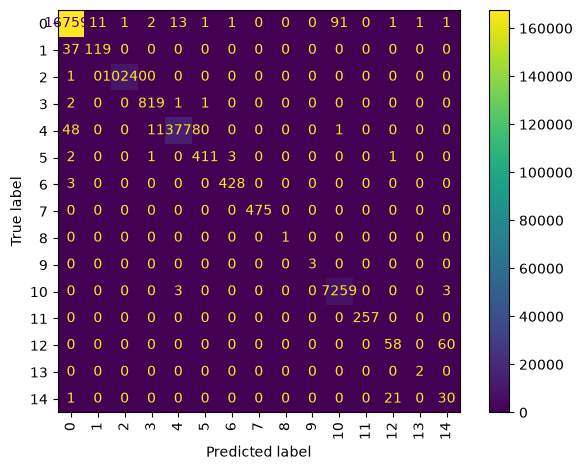

In [129]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(Y_val, custom_pred)

print('Brute Force (12) and XSS (14):')
print(cm[[12, 14]][:, [12, 14]])

disp = ConfusionMatrixDisplay(confusion_matrix = cm)
disp.plot(xticks_rotation = 'vertical', values_format = 'd')
plt.tight_layout()
plt.show()

In [130]:
from cuml.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, f1_score

rf_unweighted = RandomForestClassifier(
    n_estimators = 100,
    max_depth = 24,
    max_features = 1.0,
    class_weight = None,
    random_state = 42
)

rf_unweighted.fit(X_tune_train, Y_tune_train)
unweighted_pred = rf_unweighted.predict(X_val)

print('Accuracy:', accuracy_score(Y_val, unweighted_pred))
print('Macro F1:', f1_score(Y_val, unweighted_pred, average = 'macro', zero_division = 0))
print(classification_report(Y_val, unweighted_pred, zero_division = 0))

Accuracy: 0.9985678109312203
Macro F1: 0.8879310367364697
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    167719
           1       0.91      0.75      0.82       156
           2       1.00      1.00      1.00     10241
           3       1.00      1.00      1.00       823
           4       1.00      1.00      1.00     13828
           5       1.00      0.98      0.99       418
           6       0.99      0.99      0.99       431
           7       1.00      1.00      1.00       475
           8       1.00      1.00      1.00         1
           9       1.00      1.00      1.00         3
          10       0.99      1.00      0.99      7265
          11       1.00      1.00      1.00       257
          12       0.69      0.82      0.75       118
          13       0.50      0.50      0.50         2
          14       0.34      0.23      0.28        52

    accuracy                           1.00    201789
   macro avg       0.8

In [131]:
from sklearn.metrics import confusion_matrix

cm_unweighted = confusion_matrix(Y_val, unweighted_pred)

print("Rows = actual; columns = predicted")
print("Columns/rows: Brute Force (12), XSS (14)")
print(cm_unweighted[[12, 14]][:, [12, 14]])

Rows = actual; columns = predicted
Columns/rows: Brute Force (12), XSS (14)
[[97 21]
 [40 12]]


In [ ]:
print("X_test shape:", X_test.shape)
print("Y_test shape:", Y_test.shape)

print("\nMissing values:", X_test.isna().sum().sum())
print("Infinite values:",
      np.isinf(X_test.select_dtypes(include=np.number)).sum().sum())

print("\nTest class distribution:")
print(pd.Series(Y_test).value_counts().sort_index())

X_test shape: (504473, 69)
Y_test shape: (504473,)

Missing values: 0
Infinite values: 0

Test class distribution:
0     419297
1        391
2      25603
3       2057
4      34570
5       1046
6       1077
7       1187
8          2
9          7
10     18164
11       644
12       294
13         4
14       130
Name: count, dtype: int64


In [133]:
import inspect
from cuml.ensemble import RandomForestClassifier

print(inspect.signature(RandomForestClassifier))

(*, n_estimators=100, split_criterion='gini', bootstrap=True, max_samples=1.0, max_depth=None, max_leaves=-1, max_features='sqrt', n_bins=128, min_samples_leaf=1, min_samples_split=2, min_impurity_decrease=0.0, max_batch_size=4096, random_state=None, n_streams=4, oob_score=False, class_weight=None, verbose=False, output_type=None)


In [ ]:
rf_unweighted_final = RandomForestClassifier(
    n_estimators = 100, 
    max_depth = 24, 
    max_features = 1.0, 
    class_weight = None, 
    random_state = 42
)

rf_unweighted_final.fit(X_train, Y_train)
pred_unweighted = rf_unweighted_final.predict(X_test)

weights = {i : 1.0 for i in range(15)}
weights[14] = 3.0

rf_custom_final = RandomForestClassifier(
    n_estimators = 100,
    max_depth = 24,
    max_features = 1.0,
    class_weight = weights,
    random_state = 42
)

rf_custom_final.fit(X_train, Y_train)
pred_custom = rf_custom_final.predict(X_test)

In [ ]:
print('===== UNWEIGHTED RANDOM FOREST =====')
print('Accuracy:', accuracy_score(Y_test, pred_unweighted))
print('Macro F1:', f1_score(Y_test, pred_unweighted, average = 'macro', zero_division = 0))
print(classification_report(Y_test, pred_unweighted, zero_division = 0))

print('\n===== CUSTOM-WEIGHTED RANDOM FOREST =====')
print('Accuracy:', accuracy_score(Y_test, pred_custom))
print('Macro F1:', f1_score(Y_test, pred_custom, average = 'macro', zero_division = 0))
print(classification_report(Y_test, pred_custom, zero_division = 0))

===== UNWEIGHTED RANDOM FOREST =====
Accuracy: 0.9985390694843926
Macro F1: 0.8928203972328578
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    419297
           1       0.87      0.77      0.82       391
           2       1.00      1.00      1.00     25603
           3       1.00      0.99      0.99      2057
           4       1.00      1.00      1.00     34570
           5       0.98      0.99      0.99      1046
           6       0.99      0.99      0.99      1077
           7       1.00      1.00      1.00      1187
           8       1.00      1.00      1.00         2
           9       1.00      0.71      0.83         7
          10       0.99      1.00      0.99     18164
          11       1.00      1.00      1.00       644
          12       0.73      0.86      0.79       294
          13       0.60      0.75      0.67         4
          14       0.45      0.25      0.32       130

    accuracy                           

In [136]:
import shap

shap_model = rf_custom_final

X_shap = X_train.sample(n = 500, random_state = 42).copy()

print('SHAP sample shape:', X_shap.shape)
print('Model features:', X_shap.shape[1])
print('SHAP sample contains missing values:', X_shap.isnull().sum().sum())

SHAP sample shape: (500, 69)
Model features: 69
SHAP sample contains missing values: 0


In [137]:
probabilites = shap_model.predict_proba(X_shap)

print('Prediction shape:', probabilites.shape)
print('Numebr of classes:', probabilites.shape[1])

Prediction shape: (500, 15)
Numebr of classes: 15


In [138]:
background = X_train.sample(n = 500, random_state = 42)

masker = shap.maskers.Independent(background, max_samples = 500)

explainer = shap.Explainer(
    lambda x: shap_model.predict_proba(pd.DataFrame(x, columns = X_train.columns)),
    masker,
    algorithm = 'permutation'
)

In [139]:
X_shap_test = X_test.sample(n = 20, random_state = 42).copy()

shap_values = explainer(
    X_shap_test,
    max_evals = 2 * X_shap_test.shape[1] + 1
)

print('SHAP values shape:', shap_values.values.shape)

SHAP values shape: (20, 69, 15)


                Feature  Mean Absolute SHAP
    Average Packet Size            0.017628
  Bwd Packet Length Std            0.014175
Init_Win_bytes_backward            0.011342
       Destination Port            0.010305
  Fwd Packet Length Max            0.009620
 Packet Length Variance            0.007983
   Avg Bwd Segment Size            0.006791
           Flow IAT Std            0.005162
      Subflow Fwd Bytes            0.004999
 Init_Win_bytes_forward            0.004356
      Subflow Bwd Bytes            0.003657
           Flow Bytes/s            0.002929
            Fwd IAT Min            0.002772
          Bwd Packets/s            0.002549
               Idle Min            0.002543
   min_seg_size_forward            0.002498
         PSH Flag Count            0.002475
   Avg Fwd Segment Size            0.001663
      Fwd Header Length            0.001371
  Bwd Packet Length Min            0.001248


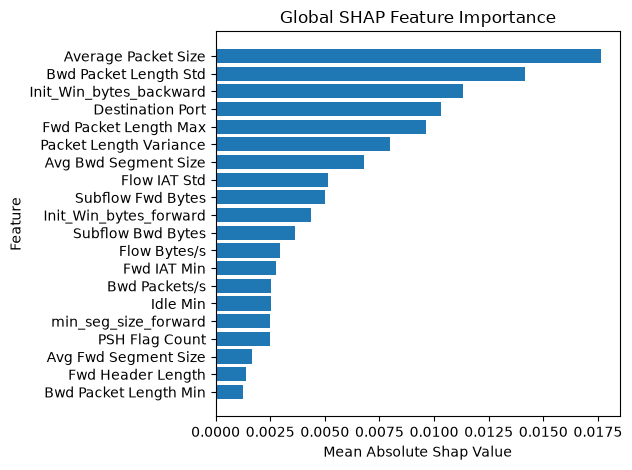

In [140]:
abs_shap = np.abs(shap_values.values)

global_importance = abs_shap.mean(axis = (0, 2))

importance_df = pd.DataFrame({
    'Feature' : X_shap_test.columns,
    'Mean Absolute SHAP' : global_importance
}).sort_values(by = 'Mean Absolute SHAP', ascending = False)

print(importance_df.head(20).to_string(index = False))

top20 = importance_df.head(20).sort_values('Mean Absolute SHAP', ascending = True)

plt.Figure(figsize = (10, 8))
plt.barh(top20['Feature'], top20['Mean Absolute SHAP'])
plt.xlabel('Mean Absolute Shap Value')
plt.ylabel('Feature')
plt.title('Global SHAP Feature Importance')
plt.tight_layout()
plt.show()

In [ ]:
X_shap_test_200 = X_test.sample(n = 200, random_state = 42).copy()

shap_values_200 = explainer(X_shap_test_200, max_evals = 2 * X_shap_test_200.shape[1] + 1)

print('SHAP values shape:', shap_values_200.values.shape)

PermutationExplainer explainer: 201it [00:32,  4.30it/s]                         

SHAP values shape: (200, 69, 15)


In [142]:
global_importance_200 = np.abs(shap_values_200.values).mean(axis = (0, 2))

importance_df_200 = pd.DataFrame({
    'Feature' : X_shap_test_200.columns,
    'Mean Absolute SHAP' : global_importance_200
}).sort_values(by = 'Mean Absolute SHAP', ascending = False)

print(importance_df_200.head(20).to_string(index = False))

                Feature  Mean Absolute SHAP
    Average Packet Size            0.014068
Init_Win_bytes_backward            0.013879
  Bwd Packet Length Std            0.011345
  Fwd Packet Length Max            0.008758
       Destination Port            0.008531
   Avg Bwd Segment Size            0.006289
 Packet Length Variance            0.005840
 Init_Win_bytes_forward            0.005462
      Subflow Fwd Bytes            0.004371
           Flow IAT Std            0.003871
      Subflow Bwd Bytes            0.003508
         PSH Flag Count            0.003139
           Flow Bytes/s            0.002333
   Avg Fwd Segment Size            0.002065
               Idle Min            0.001962
      Fwd Header Length            0.001819
  Fwd Packet Length Std            0.001706
   min_seg_size_forward            0.001573
       act_data_pkt_fwd            0.001239
            Fwd IAT Min            0.001236


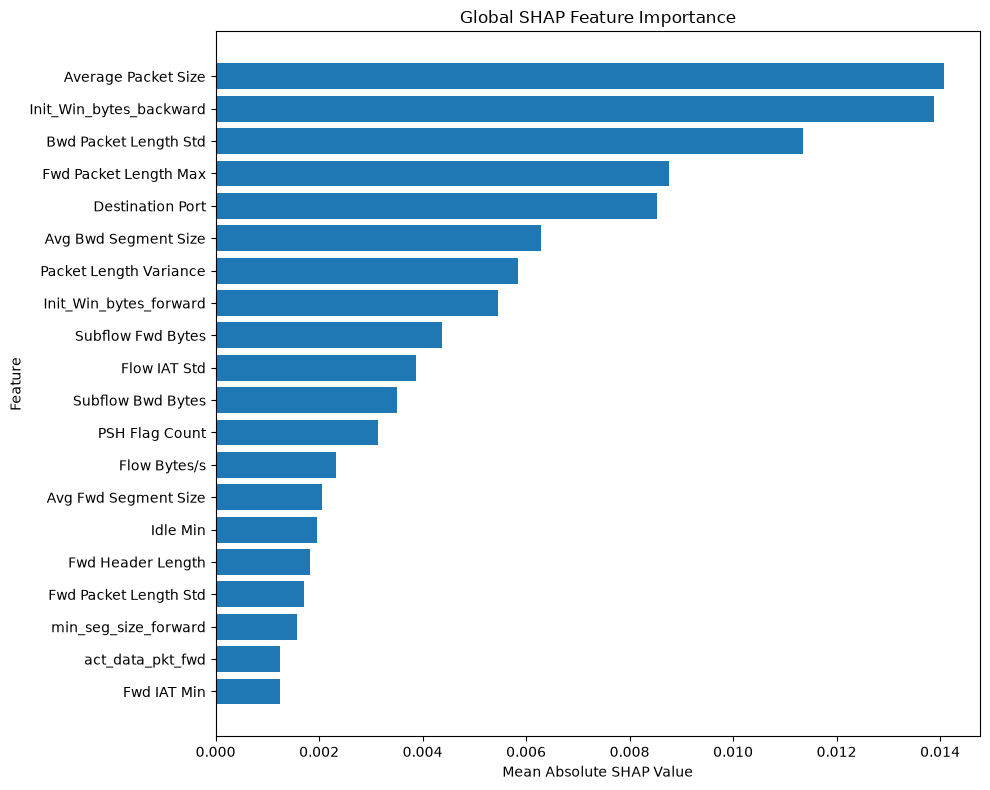

In [ ]:
top20 = importance_df_200.head(20).sort_values(by = 'Mean Absolute SHAP', ascending = True)

plt.figure(figsize = (10, 8))
plt.barh(top20['Feature'], top20['Mean Absolute SHAP'])
plt.xlabel('Mean Absolute SHAP Value')
plt.ylabel('Feature')
plt.title('Global SHAP Feature Importance')
plt.tight_layout()
plt.show()

In [ ]:
predicted = np.asarray(shap_model.predict(X_shap_test_200)).ravel()

if hasattr(Y_test, 'loc'):
    actual = Y_test.loc[X_shap_test_200.index].to_numpy()
else:
    actual = np.asarray(Y_test)[X_test.index.get_indexer(X_shap_test_200.index)]

correct_attack_indices = np.where((actual == predicted) & (actual != 0))[0]

print('Correctly classified attacks:', len(correct_attack_indices))

if len(correct_attack_indices) > 0:
    sample_idx = correct_attack_indices[0]

    print('Sample position:', sample_idx)
    print('Actual class:', target_encoder.inverse_transform([int(actual[sample_idx])])[0])
    print('Predicted class:', target_encoder.inverse_transform([int(predicted[sample_idx])])[0])
else:
    print('No correctly classified attacks found in this subset.')

Correctly classified attacks: 45
Sample position: 2
Actual class: PortScan
Predicted class: PortScan


In [145]:
class_id = int(predicted[sample_idx])

sample_shap = shap_values_200.values[sample_idx, :, class_id]

sample_importance = pd.DataFrame({
    'Feature' : X_shap_test_200.columns,
    'SHAP Value' : sample_shap,
    'Absolute SHAP' : np.abs(sample_shap)
}).sort_values(by = 'Absolute SHAP', ascending = False)

print('Actual class:', target_encoder.inverse_transform([int(actual[sample_idx])])[0])
print('Predicted class:', target_encoder.inverse_transform([class_id])[0])
print('\nTop 10 influential features for this prediction:')
print(sample_importance.head(10).to_string(index = False))

Actual class: PortScan
Predicted class: PortScan

Top 10 influential features for this prediction:
               Feature  SHAP Value  Absolute SHAP
   Average Packet Size    0.389970       0.389970
        PSH Flag Count    0.353730       0.353730
Packet Length Variance    0.066507       0.066507
          Flow IAT Std    0.063245       0.063245
  min_seg_size_forward    0.032937       0.032937
          Flow IAT Min    0.021295       0.021295
     Fwd Header Length    0.021000       0.021000
         Flow IAT Mean   -0.016005       0.016005
 Bwd Packet Length Std    0.011840       0.011840
Init_Win_bytes_forward    0.005920       0.005920


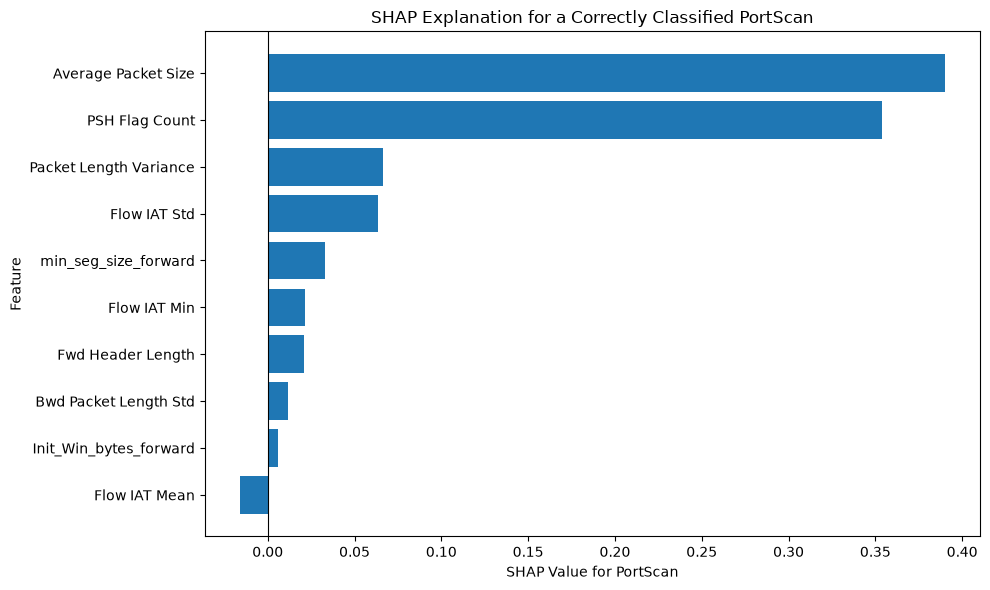

In [146]:
top10 = sample_importance.head(10).sort_values('SHAP Value', ascending = True)

plt.figure(figsize = (10, 6))
plt.barh(top10['Feature'], top10['SHAP Value'])
plt.axvline(0, color = 'black', linewidth = 0.8)
plt.xlabel('SHAP Value for PortScan')
plt.ylabel('Feature')
plt.title('SHAP Explanation for a Correctly Classified PortScan')
plt.tight_layout()
plt.show()

In [147]:
misclassified_indices = np.where((actual != predicted) & (actual != 0))[0]

print('Misclassified attacks:', len(misclassified_indices))

if len(misclassified_indices) > 0:
    wrong_idx = misclassified_indices[0]

    actual_class = target_encoder.inverse_transform([int(actual[wrong_idx])])[0]
    predicted_class = target_encoder.inverse_transform([int(predicted[wrong_idx])])[0]

    print('Sample position:', wrong_idx)
    print('Actual class:', actual_class)
    print('Predicted class:', predicted_class)
else:
    print('No misclassified attacks found in this subset.')

Misclassified attacks: 0
No misclassified attacks found in this subset.


In [ ]:
full_predictions = np.asarray(shap_model.predict(X_test)).ravel()

if hasattr(Y_test, 'loc'):
    full_actual = Y_test.loc[X_test.index].to_numpy()
else:
    full_actual = np.asarray(Y_test)

misclassified_full = np.where((full_actual != full_predictions) &(full_actual != 0))[0]

print('Misclassified attacks in full test set:', len(misclassified_full))

if len(misclassified_full) > 0:
    wrong_idx = misclassified_full[0]

    actual_class = target_encoder.inverse_transform([int(full_actual[wrong_idx])])[0]
    predicted_class = target_encoder.inverse_transform([int(full_predictions[wrong_idx])])[0]

    print('Test-set position:', wrong_idx)
    print('Actual class:', actual_class)
    print('Predicted class:', predicted_class)
else:
    print('No misclassified attacks found in the full test set.')

Misclassified attacks in full test set: 453
Test-set position: 2285
Actual class: DoS Hulk
Predicted class: DoS GoldenEye


In [149]:
X_misclassified = X_test.iloc[[wrong_idx]].copy()

actual_id = int(full_actual[wrong_idx])
predicted_id = int(full_predictions[wrong_idx])

actual_name = target_encoder.inverse_transform([actual_id])[0]
predicted_name = target_encoder.inverse_transform([predicted_id])[0]

print('Actual class:', actual_name)
print('Predicted class:', predicted_name)

shap_misclassified = explainer(
    X_misclassified,
    max_evals = 2 * X_misclassified.shape[1] + 1
)

print('SHAP values shape:', shap_misclassified.values.shape)

Actual class: DoS Hulk
Predicted class: DoS GoldenEye
SHAP values shape: (1, 69, 15)


In [150]:
mis_shap = shap_misclassified.values[0, :, predicted_id]

mis_importance = pd.DataFrame({
    'Feature': X_misclassified.columns,
    'SHAP Value': mis_shap,
    'Absolute SHAP': np.abs(mis_shap)
}).sort_values('Absolute SHAP', ascending = False)

print('\nTop 10 features influencing the predicted class:')
print(mis_importance.head(10).to_string(index = False))


Top 10 features influencing the predicted class:
               Feature  SHAP Value  Absolute SHAP
   Average Packet Size    0.274229       0.274229
        URG Flag Count    0.199277       0.199277
     Fwd Header Length    0.070818       0.070818
Init_Win_bytes_forward    0.041697       0.041697
         Fwd Packets/s    0.035640       0.035640
Packet Length Variance    0.030231       0.030231
         Flow IAT Mean    0.027464       0.027464
      Destination Port    0.020955       0.020955
        Flow Packets/s    0.009156       0.009156
              Idle Min    0.008723       0.008723


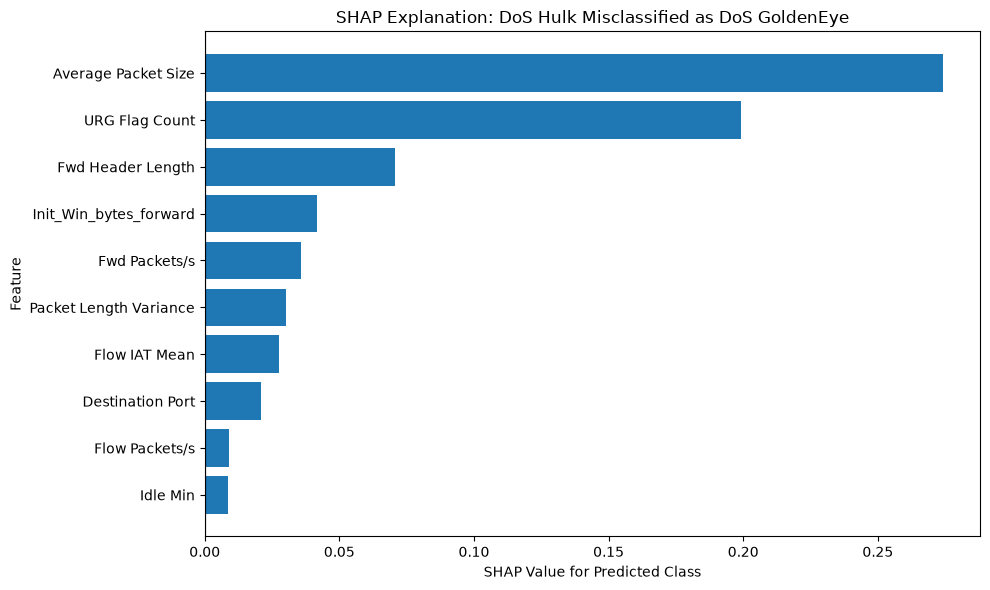

In [151]:
top10_mis = mis_importance.head(10).sort_values(by = 'SHAP Value', ascending = True)

plt.figure(figsize = (10, 6))
plt.barh(top10_mis['Feature'], top10_mis['SHAP Value'])
plt.axvline(0, color = 'black', linewidth = 0.8)
plt.xlabel('SHAP Value for Predicted Class')
plt.ylabel('Feature')
plt.title('SHAP Explanation: DoS Hulk Misclassified as DoS GoldenEye')
plt.tight_layout()
plt.show()

In [152]:
mis_probs = np.asarray(shap_model.predict_proba(X_misclassified))[0]

top_classes = np.argsort(mis_probs)[::-1][:5]

print('Actual class:', actual_name)
print('\nTop predicted classes:')

for class_id in top_classes:
    class_name = target_encoder.inverse_transform([int(class_id)])[0]
    print(f'{class_name} : {mis_probs[class_id]:.4%}')

Actual class: DoS Hulk

Top predicted classes:
DoS GoldenEye : 73.9325%
DoS Hulk : 26.0675%
Web Attack - XSS : 0.0000%
SSH-Patator : 0.0000%
PortScan : 0.0000%


/tmp/ipykernel_1140/4123532439.py:5: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


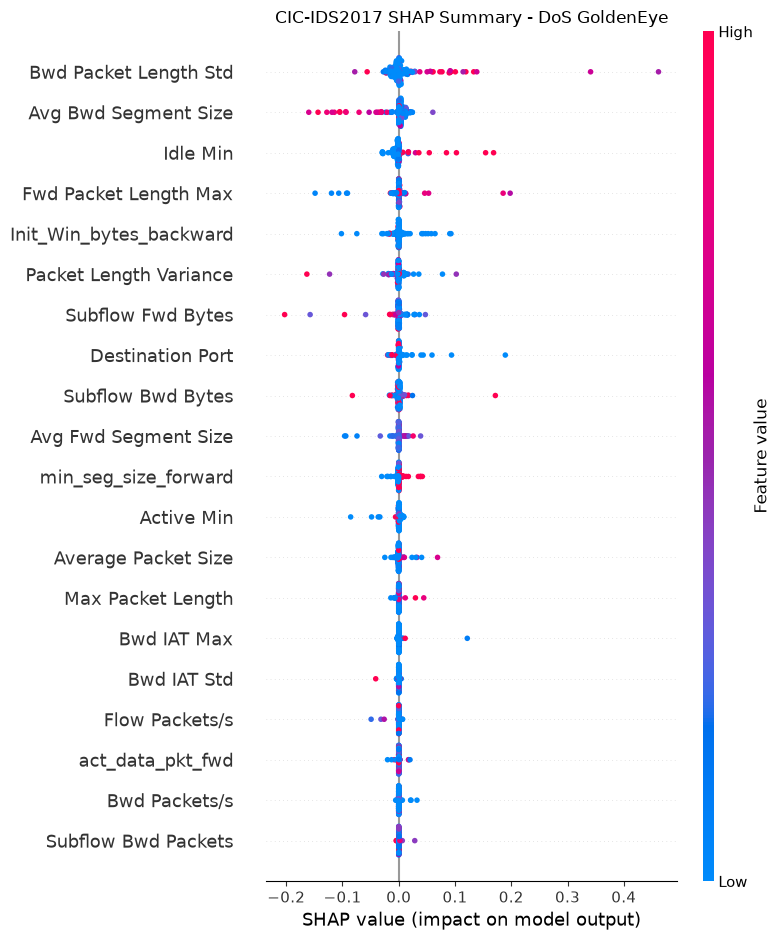

In [153]:
goldeneye_id = int(target_encoder.transform(["DoS GoldenEye"])[0])

goldeneye_shap = shap_values_200.values[:, :, goldeneye_id]

shap.summary_plot(
    goldeneye_shap,
    X_shap_test_200,
    max_display = 20,
    show = False
)

plt.title('CIC-IDS2017 SHAP Summary - DoS GoldenEye')
plt.tight_layout()
plt.show()

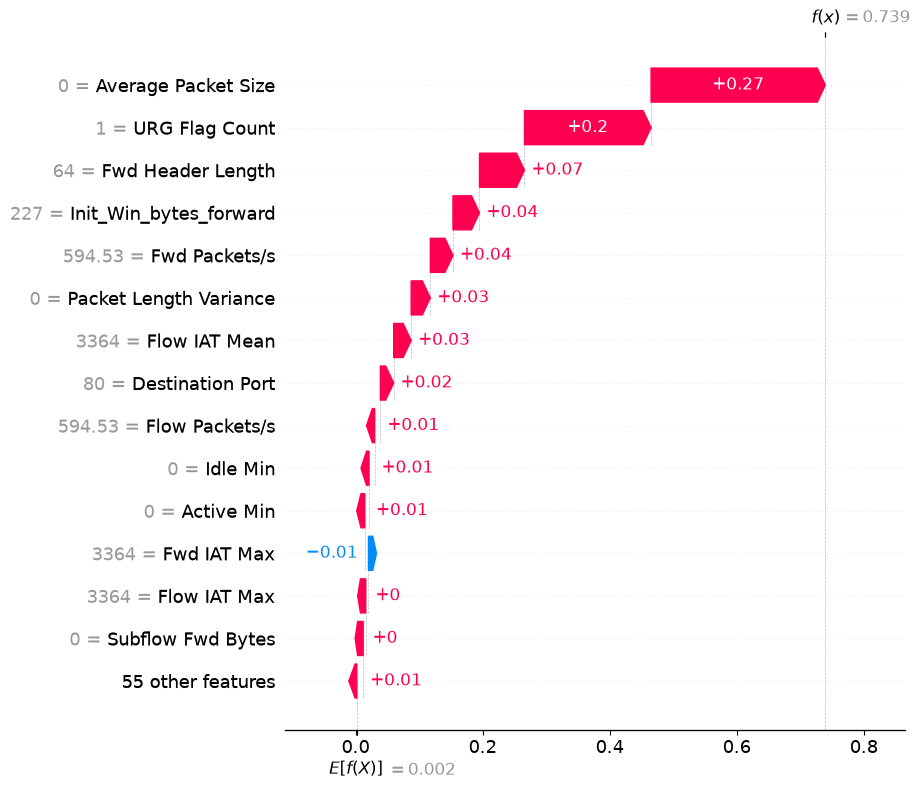

In [154]:
goldeneye_explanation = shap.Explanation(
    values = shap_misclassified.values[0, :, goldeneye_id],
    base_values = shap_misclassified.base_values[0, goldeneye_id],
    data = X_misclassified.iloc[0].values,
    feature_names = X_misclassified.columns.tolist()
)

shap.plots.waterfall(
    goldeneye_explanation,
    max_display = 15
)

In [155]:
shap.force_plot(
    base_value = shap_misclassified.base_values[0, goldeneye_id],
    shap_values = shap_misclassified.values[0, :, goldeneye_id],
    features = X_misclassified.iloc[0],
    matplotlib = False
)

In [156]:
X_portscan = X_shap_test_200.iloc[[sample_idx]].copy()

portscan_class_id = int(predicted[sample_idx])

print('Actual class:', target_encoder.inverse_transform([int(actual[sample_idx])])[0])
print('Predicted class:', target_encoder.inverse_transform([portscan_class_id])[0])

shap_portscan = explainer(
    X_portscan,
    max_evals= 2 * X_portscan.shape[1] + 1
)

print('SHAP values shape:', shap_portscan.values.shape)

Actual class: PortScan
Predicted class: PortScan
SHAP values shape: (1, 69, 15)


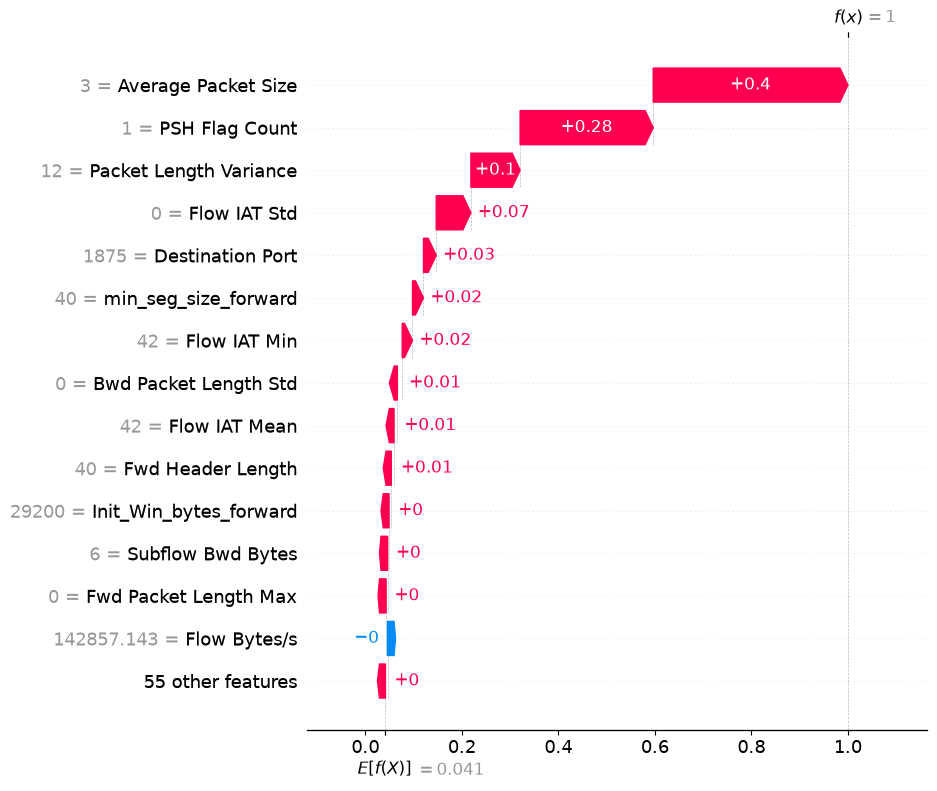

In [157]:
portscan_explanation = shap.Explanation(
    values = shap_portscan.values[0, :, portscan_class_id],
    base_values = shap_portscan.base_values[0, portscan_class_id],
    data = X_portscan.iloc[0].values,
    feature_names = X_portscan.columns.tolist()
)

shap.plots.waterfall(
    portscan_explanation,
    max_display=15
)

In [158]:
shap.force_plot(
    base_value = shap_portscan.base_values[0, portscan_class_id],
    shap_values = shap_portscan.values[0, :, portscan_class_id],
    features = X_portscan.iloc[0],
    matplotlib = False
)

In [159]:
import os
import joblib

os.makedirs('CIC-IDS2017_Models', exist_ok = True) 

joblib.dump(rf_unweighted_final, 'CIC-IDS2017_Models/rf_unweighted.pkl')
joblib.dump(rf_custom_final, 'CIC-IDS2017_Models/rf_custom_weighted.pkl')

feature_names = X_train.columns.tolist()

joblib.dump(feature_names, 'CIC-IDS2017_Models/feature_names.pkl')
joblib.dump(target_encoder, 'CIC-IDS2017_Models/target_encoder.pkl')

print('CIC-IDS2017 models and preprocessing files saved successfully.')

CIC-IDS2017 models and preprocessing files saved successfully.


CIC-IDS2017 Dataset Work done

CICIoT2023 Dataset

In [160]:
%reset -f

import gc
gc.collect()

0

In [161]:
from sklearn.preprocessing import LabelEncoder

target_encoder = LabelEncoder()

labels = [
    "DDOS-ICMP_FLOOD",
    "DDOS-UDP_FLOOD",
    "DDOS-TCP_FLOOD",
    "DDOS-PSHACK_FLOOD",
    "DDOS-SYN_FLOOD",
    "DDOS-RSTFINFLOOD",
    "DDOS-SYNONYMOUSIP_FLOOD",
    "DOS-UDP_FLOOD",
    "DOS-TCP_FLOOD",
    "DOS-SYN_FLOOD",
    "BENIGN",
    "MIRAI-GREETH_FLOOD",
    "MIRAI-UDPPLAIN",
    "MIRAI-GREIP_FLOOD",
    "DDOS-ICMP_FRAGMENTATION",
    "VULNERABILITYSCAN",
    "MITM-ARPSPOOFING",
    "DDOS-UDP_FRAGMENTATION",
    "DDOS-ACK_FRAGMENTATION",
    "DNS_SPOOFING",
    "RECON-HOSTDISCOVERY",
    "RECON-OSSCAN",
    "RECON-PORTSCAN",
    "DOS-HTTP_FLOOD",
    "DDOS-HTTP_FLOOD",
    "DDOS-SLOWLORIS",
    "DICTIONARYBRUTEFORCE",
    "BROWSERHIJACKING",
    "COMMANDINJECTION",
    "SQLINJECTION",
    "XSS",
    "BACKDOOR_MALWARE",
    "RECON-PINGSWEEP",
    "UPLOADING_ATTACK"
]

encoded_labels = target_encoder.fit_transform(labels)

print(encoded_labels)

dict(enumerate(target_encoder.classes_))

[ 6 14 13  8 12  9 11 21 20 19  1 22 24 23  7 32 25 15  4 17 26 27 29 18
  5 10 16  2  3 30 33  0 28 31]


{0: np.str_('BACKDOOR_MALWARE'),
 1: np.str_('BENIGN'),
 2: np.str_('BROWSERHIJACKING'),
 3: np.str_('COMMANDINJECTION'),
 4: np.str_('DDOS-ACK_FRAGMENTATION'),
 5: np.str_('DDOS-HTTP_FLOOD'),
 6: np.str_('DDOS-ICMP_FLOOD'),
 7: np.str_('DDOS-ICMP_FRAGMENTATION'),
 8: np.str_('DDOS-PSHACK_FLOOD'),
 9: np.str_('DDOS-RSTFINFLOOD'),
 10: np.str_('DDOS-SLOWLORIS'),
 11: np.str_('DDOS-SYNONYMOUSIP_FLOOD'),
 12: np.str_('DDOS-SYN_FLOOD'),
 13: np.str_('DDOS-TCP_FLOOD'),
 14: np.str_('DDOS-UDP_FLOOD'),
 15: np.str_('DDOS-UDP_FRAGMENTATION'),
 16: np.str_('DICTIONARYBRUTEFORCE'),
 17: np.str_('DNS_SPOOFING'),
 18: np.str_('DOS-HTTP_FLOOD'),
 19: np.str_('DOS-SYN_FLOOD'),
 20: np.str_('DOS-TCP_FLOOD'),
 21: np.str_('DOS-UDP_FLOOD'),
 22: np.str_('MIRAI-GREETH_FLOOD'),
 23: np.str_('MIRAI-GREIP_FLOOD'),
 24: np.str_('MIRAI-UDPPLAIN'),
 25: np.str_('MITM-ARPSPOOFING'),
 26: np.str_('RECON-HOSTDISCOVERY'),
 27: np.str_('RECON-OSSCAN'),
 28: np.str_('RECON-PINGSWEEP'),
 29: np.str_('RECON-PORTSCAN'

In [162]:
def load_dataset(file_path):
    return pd.read_csv(file_path)

def validate_columns(df, expected_columns):
    missing = set(expected_columns) - set(df.columns)
    extra = set(df.columns) - set(expected_columns)

    if missing:
        print("Missing columns:", missing)

    if extra:
        print("Unexpected columns:", extra)

    return not missing and not extra

def handle_duplicates(df):
    print('\nDuplicate rows:', df.duplicated().sum())

    df = df.drop_duplicates()

    print('Duplicated rows left:', df.duplicated().sum())
    return df

def handle_invalid_values(df):
    count = np.isinf(df.select_dtypes(include = np.number)).sum().sum()
    print('\nInfinite values:', count)

    df = df.replace([np.inf, -np.inf], np.nan)

    count = np.isinf(df.select_dtypes(include = np.number)).sum().sum()
    print('Infinite values left:', count)
    return df

def handle_missing_values(df):
    print('\nMissing values before handling:')
    print(df.isnull().sum().sum())

    df = df.dropna(subset = ['Label']).copy()

    feature_cols = df.columns.drop('Label')
    numeric_cols = df[feature_cols].select_dtypes(include = np.number).columns
    categorical_cols = feature_cols.difference(numeric_cols)

    for col in numeric_cols:
        if df[col].isnull().sum():
            median_value = df[col].median()

            if pd.notna(median_value):
                df[col] = df[col].fillna(median_value)

    for col in categorical_cols:
        if df[col].isnull().sum():
            mode_values = df[col].mode()

            if not mode_values.empty:
                df[col] = df[col].fillna(mode_values.iloc[0])

    print('\nMissing values after handling:')
    print(df.isnull().sum().sum())

    return df

def encode_labels(df, encoder):
    df = df.copy()
    df['Label'] = encoder.transform(df['Label'])
    print('\nLabel encoded successfully.')

    return df

def preprocess_dataset(file_path, expected_columns):
    df = load_dataset(file_path)

    if not validate_columns(df, expected_columns):
        raise ValueError("Dataset schema validation failed.")

    df = handle_duplicates(df)
    df = handle_invalid_values(df)
    df = handle_missing_values(df)
    df = encode_labels(df, target_encoder)

    return df

In [163]:
from pathlib import Path
import pandas as pd

input_folder = Path("CICIoT2023")

output_folder = input_folder.parent / "CICIoT2023_Preprocessed"
output_folder.mkdir(parents = True, exist_ok = True)

csv_files = sorted(input_folder.glob("*.csv"))

print("Number of CSV files:", len(csv_files))
print("Output folder:", output_folder)

Number of CSV files: 63
Output folder: CICIoT2023_Preprocessed


In [164]:
expected_columns = [
    "Header_Length", "Protocol Type", "Time_To_Live", "Rate",
    "fin_flag_number", "syn_flag_number", "rst_flag_number",
    "psh_flag_number", "ack_flag_number", "ece_flag_number",
    "cwr_flag_number", "ack_count", "syn_count", "fin_count",
    "rst_count", "HTTP", "HTTPS", "DNS", "Telnet", "SMTP",
    "SSH", "IRC", "TCP", "UDP", "DHCP", "ARP", "ICMP",
    "IGMP", "IPv", "LLC", "Tot sum", "Min", "Max", "AVG",
    "Std", "Tot size", "IAT", "Number", "Variance", "Label"
]

In [165]:
from pathlib import Path
import numpy as np

input_folder = Path("CICIoT2023")
output_folder = input_folder.parent / "CICIoT2023_Preprocessed"
output_folder.mkdir(parents = True, exist_ok = True)

csv_files = sorted(input_folder.glob("*.csv"))

print("Files found:", len(csv_files))

for i, file_path in enumerate(csv_files, start = 1):
    print(f"\nProcessing {i}/{len(csv_files)}: {file_path.name}")

    df = preprocess_dataset(file_path, expected_columns)

    output_path = output_folder / file_path.name
    df.to_csv(output_path, index = False)

    print("Saved:", output_path.name)
    print("Final shape:", df.shape)

    del df

Files found: 63

Processing 1/63: Merged01.csv

Duplicate rows: 167368
Duplicated rows left: 0

Infinite values: 14
Infinite values left: 0

Missing values before handling:
36

Missing values after handling:
0

Label encoded successfully.
Saved: Merged01.csv
Final shape: (544943, 40)

Processing 2/63: Merged02.csv

Duplicate rows: 179907
Duplicated rows left: 0

Infinite values: 13
Infinite values left: 0

Missing values before handling:
25

Missing values after handling:
0

Label encoded successfully.
Saved: Merged02.csv
Final shape: (568678, 40)

Processing 3/63: Merged03.csv

Duplicate rows: 162037
Duplicated rows left: 0

Infinite values: 17
Infinite values left: 0

Missing values before handling:
35

Missing values after handling:
0

Label encoded successfully.
Saved: Merged03.csv
Final shape: (535252, 40)

Processing 4/63: Merged04.csv

Duplicate rows: 155415
Duplicated rows left: 0

Infinite values: 22
Infinite values left: 0

Missing values before handling:
48

Missing values a

KeyboardInterrupt: 

In [ ]:
from pathlib import Path
import pandas as pd

data_folder = Path("CICIoT2023_Preprocessed")

class_counts = {}

for i, file_path in enumerate(sorted(data_folder.glob("*.csv")), start = 1):
    print(f"Analyzing {i}/63: {file_path.name}")

    df = pd.read_csv(file_path)

    counts = df["Label"].value_counts()

    for label, count in counts.items():
        class_counts[int(label)] = (class_counts.get(int(label), 0) + int(count))

distribution = pd.DataFrame({
    "Label_ID": sorted(class_counts),
    "Samples": [class_counts[i] for i in sorted(class_counts)]
})

distribution["Percentage"] = (distribution["Samples"] / distribution["Samples"].sum() * 100)

distribution = distribution.sort_values("Samples", ascending=False)

print("\nClass distribution:")
print(distribution.to_string(index = False))
print("\nTotal samples:", f"{distribution['Samples'].sum():,}")

Analyzing 1/63: Merged01.csv
Analyzing 2/63: Merged02.csv
Analyzing 3/63: Merged03.csv
Analyzing 4/63: Merged04.csv
Analyzing 5/63: Merged05.csv
Analyzing 6/63: Merged06.csv
Analyzing 7/63: Merged07.csv
Analyzing 8/63: Merged08.csv
Analyzing 9/63: Merged09.csv
Analyzing 10/63: Merged10.csv
Analyzing 11/63: Merged11.csv
Analyzing 12/63: Merged12.csv
Analyzing 13/63: Merged13.csv
Analyzing 14/63: Merged14.csv
Analyzing 15/63: Merged15.csv
Analyzing 16/63: Merged16.csv
Analyzing 17/63: Merged17.csv
Analyzing 18/63: Merged18.csv
Analyzing 19/63: Merged19.csv
Analyzing 20/63: Merged20.csv
Analyzing 21/63: Merged21.csv
Analyzing 22/63: Merged22.csv
Analyzing 23/63: Merged23.csv
Analyzing 24/63: Merged24.csv
Analyzing 25/63: Merged25.csv
Analyzing 26/63: Merged26.csv
Analyzing 27/63: Merged27.csv
Analyzing 28/63: Merged28.csv
Analyzing 29/63: Merged29.csv
Analyzing 30/63: Merged30.csv
Analyzing 31/63: Merged31.csv
Analyzing 32/63: Merged32.csv
Analyzing 33/63: Merged33.csv
Analyzing 34/63: Me

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np

data_folder = Path("CICIoT2023_Preprocessed")
output_path = data_folder.parent / "CICIoT2023 CSVs" / "CICIoT2023_Training_Sample.csv"

output_path.parent.mkdir(parents = True, exist_ok = True)

MAX_PER_CLASS = 20_000
RANDOM_STATE = 42

files = sorted(data_folder.glob("*.csv"))

file_counts = {}

for i, file_path in enumerate(files, start = 1):
    print(f"Counting {i}/{len(files)}: {file_path.name}")

    labels = pd.read_csv(file_path, usecols=["Label"])["Label"]
    file_counts[file_path] = labels.value_counts().to_dict()

global_counts = {}

for counts in file_counts.values():
    for label, count in counts.items():
        global_counts[label] = global_counts.get(label, 0) + count

sampled_parts = []

for i, file_path in enumerate(files, start = 1):
    print(f"Sampling {i}/{len(files)}: {file_path.name}")

    df = pd.read_csv(file_path)

    parts = []

    for label, group in df.groupby("Label", sort = False):
        total_for_class = global_counts[label]
        target = min(MAX_PER_CLASS, total_for_class)

        quota = min(len(group), int(np.ceil(target * len(group) / total_for_class)))

        parts.append(group.sample(n = quota, random_state = RANDOM_STATE))

    sampled_parts.append(pd.concat(parts, ignore_index = True))
    del df

sampled = pd.concat(sampled_parts, ignore_index = True)
del sampled_parts

sampled = (sampled.groupby("Label", group_keys = False).sample(frac = 1, random_state = RANDOM_STATE))

sampled = (sampled.groupby("Label", group_keys = False).head(MAX_PER_CLASS).reset_index(drop = True))

sampled = sampled.sample(frac = 1, random_state = RANDOM_STATE).reset_index(drop = True)

sampled.to_csv(output_path, index = False)

print("\nFinal shape:", sampled.shape)
print("Label column present:", "Label" in sampled.columns)
print("\nSamples per class:")
print(sampled["Label"].value_counts().sort_index())
print("\nSaved to:", output_path)

Counting 1/63: Merged01.csv
Counting 2/63: Merged02.csv
Counting 3/63: Merged03.csv
Counting 4/63: Merged04.csv
Counting 5/63: Merged05.csv
Counting 6/63: Merged06.csv
Counting 7/63: Merged07.csv
Counting 8/63: Merged08.csv
Counting 9/63: Merged09.csv
Counting 10/63: Merged10.csv
Counting 11/63: Merged11.csv
Counting 12/63: Merged12.csv
Counting 13/63: Merged13.csv
Counting 14/63: Merged14.csv
Counting 15/63: Merged15.csv
Counting 16/63: Merged16.csv
Counting 17/63: Merged17.csv
Counting 18/63: Merged18.csv
Counting 19/63: Merged19.csv
Counting 20/63: Merged20.csv
Counting 21/63: Merged21.csv
Counting 22/63: Merged22.csv
Counting 23/63: Merged23.csv
Counting 24/63: Merged24.csv
Counting 25/63: Merged25.csv
Counting 26/63: Merged26.csv
Counting 27/63: Merged27.csv
Counting 28/63: Merged28.csv
Counting 29/63: Merged29.csv
Counting 30/63: Merged30.csv
Counting 31/63: Merged31.csv
Counting 32/63: Merged32.csv
Counting 33/63: Merged33.csv
Counting 34/63: Merged34.csv
Counting 35/63: Merged3

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv("CICIoT2023 CSVs/CICIoT2023_Training_Sample.csv")

X = df.drop(columns = ["Label"])
Y = df["Label"].astype("int32")

X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size = 0.20,
    random_state = 42,
    stratify = Y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training labels:", Y_train.shape)
print("Testing labels:", Y_test.shape)

print("\nTraining class distribution:")
print(Y_train.value_counts().sort_index())

print("\nTesting class distribution:")
print(Y_test.value_counts().sort_index())

Training features: (446783, 39)
Testing features: (111696, 39)
Training labels: (446783,)
Testing labels: (111696,)

Training class distribution:
Label
0      2462
1     16000
2      4502
3      4134
4     16000
5     16000
6     16000
7     16000
8     16000
9     16000
10    16000
11    16000
12    16000
13    16000
14    16000
15    16000
16    10017
17    16000
18    16000
19    16000
20    16000
21    16000
22    16000
23    16000
24    16000
25    16000
26    16000
27    16000
28     1729
29    16000
30     4018
31      957
32    16000
33     2964
Name: count, dtype: int64

Testing class distribution:
Label
0      616
1     4000
2     1125
3     1034
4     4000
5     4000
6     4000
7     4000
8     4000
9     4000
10    4000
11    4000
12    4000
13    4000
14    4000
15    4000
16    2505
17    4000
18    4000
19    4000
20    4000
21    4000
22    4000
23    4000
24    4000
25    4000
26    4000
27    4000
28     432
29    4000
30    1004
31     239
32    4000
33     741
Name:

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from cuml.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from cuml.svm import SVC
from cuml.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score
from sklearn.model_selection import train_test_split

dt = DecisionTreeClassifier(random_state = 42)
rf = RandomForestClassifier(random_state = 42)
xgb = XGBClassifier(random_state = 42, device = 'cuda')
svm = SVC(random_state = 42)
lr = LogisticRegression()

dt.fit(X_train, Y_train)
rf.fit(X_train, Y_train)
xgb.fit(X_train, Y_train)
svm.fit(X_train_scaled, Y_train)
lr.fit(X_train_scaled, Y_train)

LogisticRegression()

In [ ]:
models = {
    "Decision Tree" : dt,
    "Random Forest" : rf,
    "XGBoost" : xgb,
}

scaled_models = {
    "SVM" : svm,
    "Logistic Regression" : lr
}

for name, model in models.items():
    pred = model.predict(X_test)
    print(f'{name} Accuracy:', accuracy_score(Y_test, pred))
    print(classification_report(Y_test, pred, zero_division = 0))

for name, model in scaled_models.items():
    pred = model.predict(X_test_scaled)
    print(f'{name} Accuracy:', accuracy_score(Y_test, pred))
    print(classification_report(Y_test, pred, zero_division = 0))

Decision Tree Accuracy: 0.6837397937258273
              precision    recall  f1-score   support

           0       0.13      0.12      0.13       616
           1       0.44      0.43      0.44      4000
           2       0.41      0.41      0.41      1125
           3       0.35      0.34      0.34      1034
           4       0.98      0.99      0.99      4000
           5       0.82      0.82      0.82      4000
           6       1.00      1.00      1.00      4000
           7       0.99      0.98      0.99      4000
           8       1.00      1.00      1.00      4000
           9       1.00      1.00      1.00      4000
          10       0.93      0.93      0.93      4000
          11       0.43      0.48      0.46      4000
          12       0.39      0.38      0.38      4000
          13       0.57      0.59      0.58      4000
          14       0.66      0.68      0.67      4000
          15       0.99      0.98      0.99      4000
          16       0.45      0.46     

/home/asim_azhar/miniforge3/envs/rapids/lib/python3.13/site-packages/xgboost/core.py:569: UserWarning: [05:13:34] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


XGBoost Accuracy: 0.7358723678556081
              precision    recall  f1-score   support

           0       0.25      0.12      0.16       616
           1       0.47      0.70      0.56      4000
           2       0.70      0.41      0.52      1125
           3       0.50      0.38      0.43      1034
           4       0.99      0.99      0.99      4000
           5       0.90      0.85      0.87      4000
           6       1.00      1.00      1.00      4000
           7       0.99      0.99      0.99      4000
           8       1.00      1.00      1.00      4000
           9       1.00      1.00      1.00      4000
          10       0.94      0.99      0.97      4000
          11       0.45      0.73      0.55      4000
          12       0.51      0.30      0.38      4000
          13       0.66      0.52      0.58      4000
          14       0.67      0.85      0.75      4000
          15       0.99      0.99      0.99      4000
          16       0.58      0.54      0.56 

In [ ]:
xgb = XGBClassifier(
    n_estimators = 300,
    max_depth = 8,
    learning_rate = 0.1,
    objective = "multi:softprob",
    num_class = 34,
    eval_metric = "mlogloss",
    tree_method = "hist",
    device = "cuda",
    random_state = 42,
    n_jobs = -1
)

xgb.fit(X_train, Y_train)

pred = xgb.predict(X_test)

print("XGBoost Accuracy:", accuracy_score(Y_test, pred))
print(classification_report(Y_test, pred, zero_division = 0))

XGBoost Accuracy: 0.7395161867927231
              precision    recall  f1-score   support

           0       0.29      0.14      0.19       616
           1       0.48      0.70      0.57      4000
           2       0.70      0.42      0.53      1125
           3       0.49      0.40      0.44      1034
           4       0.99      0.99      0.99      4000
           5       0.91      0.85      0.88      4000
           6       1.00      1.00      1.00      4000
           7       0.99      0.99      0.99      4000
           8       1.00      1.00      1.00      4000
           9       1.00      1.00      1.00      4000
          10       0.95      0.99      0.97      4000
          11       0.45      0.72      0.55      4000
          12       0.50      0.31      0.38      4000
          13       0.66      0.53      0.59      4000
          14       0.67      0.84      0.75      4000
          15       1.00      0.99      0.99      4000
          16       0.59      0.54      0.57 

In [ ]:
from pathlib import Path
import pandas as pd
from sklearn.metrics import classification_report

class_names = target_encoder.classes_

report = classification_report(
    Y_test,
    pred,
    labels = list(range(len(class_names))),
    target_names = class_names,
    output_dict = True,
    zero_division = 0
)

results = pd.DataFrame(report).T

results = results.loc[class_names, ["precision", "recall", "f1-score", "support"]]

results = results.sort_values(by = "f1-score", ascending = True)

print(results.round(3).to_string())

output_path = Path("CICIoT2023 CSVs") / "CICIoT2023_XGBoost_Classwise_Results.csv"
output_path.parent.mkdir(parents = True, exist_ok = True)

results.to_csv(output_path, index = False)

print("\nSaved class-wise results successfully.")

                         precision  recall  f1-score  support
UPLOADING_ATTACK             0.200   0.046     0.075    239.0
RECON-PINGSWEEP              0.393   0.102     0.162    432.0
XSS                          0.207   0.146     0.171    741.0
SQLINJECTION                 0.488   0.104     0.171   1004.0
BACKDOOR_MALWARE             0.293   0.140     0.189    616.0
RECON-OSSCAN                 0.376   0.254     0.303   4000.0
DDOS-SYN_FLOOD               0.501   0.312     0.384   4000.0
RECON-PORTSCAN               0.450   0.367     0.404   4000.0
COMMANDINJECTION             0.495   0.403     0.444   1034.0
VULNERABILITYSCAN            0.411   0.614     0.493   4000.0
DOS-SYN_FLOOD                0.592   0.457     0.516   4000.0
BROWSERHIJACKING             0.703   0.424     0.529   1125.0
DDOS-SYNONYMOUSIP_FLOOD      0.448   0.716     0.551   4000.0
DICTIONARYBRUTEFORCE         0.590   0.545     0.567   2505.0
BENIGN                       0.482   0.704     0.572   4000.0
DDOS-TCP

In [ ]:
from pathlib import Path
import pandas as pd
from sklearn.metrics import confusion_matrix

class_names = target_encoder.classes_

cm = confusion_matrix(Y_test, pred, labels = list(range(len(class_names))))

cm_df = pd.DataFrame(cm, index = class_names, columns = class_names)

output_path = Path("CICIoT2023 CSVs") / "CICIoT2023_XGBoost_Confusion_Matrix.csv"

output_path.parent.mkdir(parents = True, exist_ok = True)

cm_df.to_csv(output_path, index = False)

errors = []

for i, actual in enumerate(class_names):
    for j, predicted in enumerate(class_names):
        if i != j and cm[i, j] > 0:
            errors.append({
                "Actual attack": actual,
                "Predicted as": predicted,
                "Misclassified samples": int(cm[i, j])
            })

errors_df = pd.DataFrame(errors).sort_values("Misclassified samples", ascending = False)

print("Top 20 misclassifications:")
print(errors_df.head(20).to_string(index = False))

print("\nSaved confusion matrix.")

Top 20 misclassifications:
          Actual attack            Predicted as  Misclassified samples
         DDOS-SYN_FLOOD DDOS-SYNONYMOUSIP_FLOOD                   1989
         DDOS-TCP_FLOOD           DOS-TCP_FLOOD                   1855
          DOS-UDP_FLOOD          DDOS-UDP_FLOOD                   1656
          DOS-SYN_FLOOD DDOS-SYNONYMOUSIP_FLOOD                   1537
          DOS-TCP_FLOOD          DDOS-TCP_FLOOD                   1089
           RECON-OSSCAN          RECON-PORTSCAN                   1025
           RECON-OSSCAN                  BENIGN                    881
         RECON-PORTSCAN       VULNERABILITYSCAN                    826
         DDOS-SYN_FLOOD           DOS-SYN_FLOOD                    759
         RECON-PORTSCAN            RECON-OSSCAN                    648
       MITM-ARPSPOOFING            DNS_SPOOFING                    637
DDOS-SYNONYMOUSIP_FLOOD          DDOS-SYN_FLOOD                    636
         DDOS-UDP_FLOOD           DOS-UDP_FLOOD   

        Feature  Importance
  Protocol Type    0.425288
      syn_count    0.132038
         Number    0.096866
           ICMP    0.051900
      ack_count    0.045123
fin_flag_number    0.032393
            UDP    0.031474
        Tot sum    0.019587
            SSH    0.016233
      fin_count    0.014848
            Min    0.014473
            TCP    0.013901
rst_flag_number    0.013692
            AVG    0.013670
psh_flag_number    0.013248
syn_flag_number    0.009334
            Max    0.008123
ack_flag_number    0.007607
           HTTP    0.006874
          HTTPS    0.006047
  Header_Length    0.005732
      rst_count    0.004646
            IAT    0.003168
            Std    0.002351
   Time_To_Live    0.001903
            ARP    0.001619
            DNS    0.001471
           Rate    0.001365
ece_flag_number    0.001295
            IRC    0.000959
           DHCP    0.000709
cwr_flag_number    0.000644
           IGMP    0.000530
         Telnet    0.000461
           SMTP    0

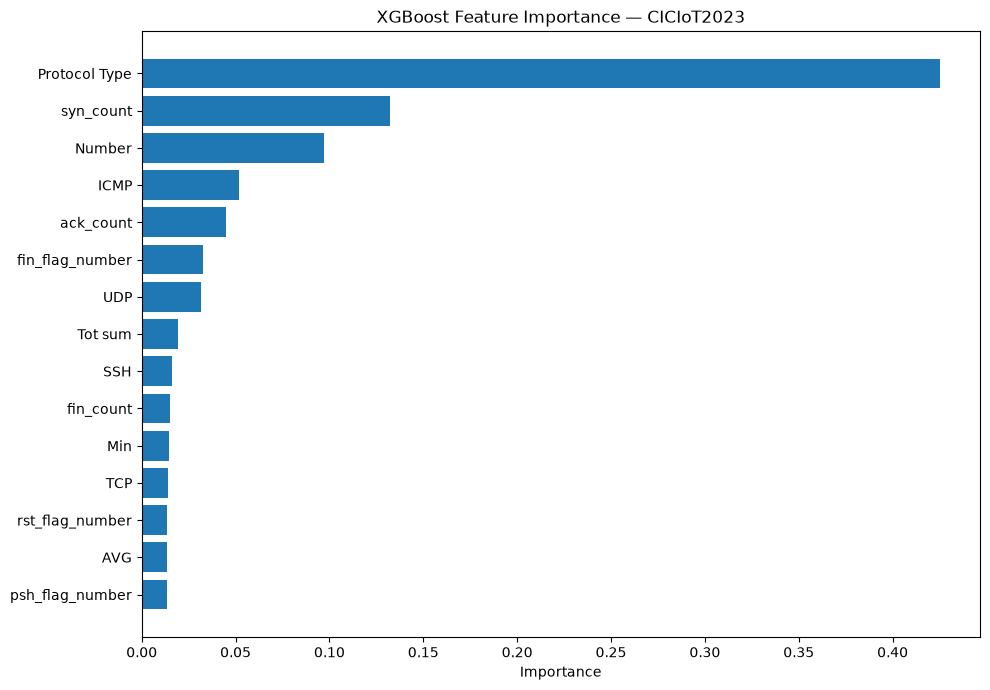

AttributeError: 'list' object has no attribute 'to_csv'

In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": xgb.feature_importances_
}).sort_values("Importance", ascending = False)

print(importance.to_string(index = False))

top_features = importance.head(15).sort_values("Importance")

plt.figure(figsize = (10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Importance")
plt.title("XGBoost Feature Importance - CICIoT2023")
plt.tight_layout()
plt.show()

output_path = Path("CICIoT2023 CSVs") / "CICIoT2023_XGBoost_Feature_Importance.csv"

output_path.parent.mkdir(parents = True, exist_ok = True)

results.to_csv(output_path, index = False)

importance.to_csv(output_path, index = False)

In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

X_train_ablation = X_train.drop(columns = ["Protocol Type"])
X_test_ablation = X_test.drop(columns = ["Protocol Type"])

xgb_no_protocol = XGBClassifier(
    n_estimators = 300,
    max_depth = 8,
    learning_rate = 0.1,
    objective = "multi:softprob",
    num_class = 34,
    eval_metric = "mlogloss",
    tree_method = "hist",
    device = "cuda",
    random_state = 42,
    n_jobs = -1
)

xgb_no_protocol.fit(X_train_ablation, Y_train)

pred = xgb_no_protocol.predict(X_test_ablation)

print("XGBoost without Protocol Type")
print("Accuracy:", accuracy_score(Y_test, pred))
print("Macro F1:", f1_score(Y_test, pred, average="macro"))
print("Weighted F1:", f1_score(Y_test, pred, average="weighted"))

print(classification_report(Y_test, pred, target_names = target_encoder.classes_, zero_division = 0))

NameError: name 'X_train' is not defined

In [ ]:
from pathlib import Path
import gc
import time

import numpy as np
import pandas as pd
import psutil
import xgboost as xgb

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

PROJECT_DIR = Path.cwd()
SAMPLE_FILE = PROJECT_DIR / "CICIoT2023 CSVs" / "CICIoT2023_Training_Sample.csv"

MODEL_PATH = PROJECT_DIR / "CICIoT2023_Models" / "CICIoT2023_XGBoost_Sample_Model.json"

MODEL_PATH.parent.mkdir(parents = True, exist_ok = True)


assert SAMPLE_FILE.exists(), f"File not found: {SAMPLE_FILE}"

print("XGBoost:", xgb.__version__)
print("Available RAM before loading:", round(psutil.virtual_memory().available / 1024**3, 2), "GB")


df = pd.read_csv(SAMPLE_FILE)

assert "Label" in df.columns
assert df.shape[1] == 40, f"Unexpected shape: {df.shape}"

X = df.drop(columns = ["Label"]).to_numpy(dtype = np.float32)
Y = df["Label"].to_numpy(dtype = np.int32)

assert np.all((Y >= 0) & (Y < 34)), "Unexpected label IDs"

print("Dataset shape:", df.shape)
print("Feature shape:", X.shape)
print("Number of classes:", len(np.unique(Y)))

del df
gc.collect()

X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size = 0.20,
    random_state = 42,
    stratify = Y
)

del X, Y
gc.collect()

print("Training rows:", len(Y_train))
print("Testing rows:", len(Y_test))
print("Available RAM after split:", round(psutil.virtual_memory().available / 1024**3, 2), "GB")

params = {
    "objective": "multi:softprob",
    "num_class": 34,
    "eval_metric": "mlogloss",
    "tree_method": "hist",
    "device": "cuda",
    "max_depth": 8,
    "learning_rate": 0.1,
    "max_bin": 256,
    "nthread": 4,
    "42": 42
}

dtrain = xgb.DMatrix(X_train, label = Y_train)
dtest = xgb.DMatrix(X_test, label = Y_test)

print("\nStarting GPU training...")
start = time.time()

model = xgb.train(
    params = params,
    dtrain = dtrain,
    num_boost_round = 300,
    evals = [(dtest, "test")],
    early_stopping_rounds = 20,
    verbose_eval = 25
)

print("Training time (minutes):", round((time.time() - start) / 60, 2))

probabilities = model.predict(dtest, iteration_range = (0, model.best_iteration + 1))
pred = np.argmax(probabilities, axis = 1)

accuracy = accuracy_score(Y_test, pred)
macro_f1 = f1_score(Y_test, pred, average = "macro", zero_division = 0)
weighted_f1 = f1_score(Y_test, pred, average = "weighted", zero_division = 0)

print("\nFINAL SAMPLE MODEL RESULTS")
print(f"Accuracy:   {accuracy:.4f}")
print(f"Macro F1:   {macro_f1:.4f}")
print(f"Weighted F1:{weighted_f1:.4f}")
print("Best iteration:", model.best_iteration)

print("\nClassification report:")
print(classification_report(Y_test, pred, labels = np.arange(34), zero_division = 0, digits = 4))

model.save_model(str(MODEL_PATH))

report = classification_report(Y_test, pred, labels = np.arange(34), output_dict = True,zero_division = 0)

pd.DataFrame(report).transpose().to_csv(PROJECT_DIR / "CICIoT2023 CSVs" / "CICIoT2023_XGBoost_Sample_Classification_Report.csv")

pd.DataFrame(confusion_matrix(Y_test, pred, labels = np.arange(34))).to_csv(
    PROJECT_DIR / "CICIoT2023 CSVs" / "CICIoT2023_XGBoost_Sample_Confusion_Matrix.csv",
    index = False
)

print("\nModel saved to:", MODEL_PATH)
print("Classification report and confusion matrix saved.")

del dtrain, dtest, X_train, X_test, Y_train, Y_test
gc.collect()

print("Available RAM after cleanup:", round(psutil.virtual_memory().available / 1024**3, 2), "GB")


XGBoost: 3.4.1
Available RAM before loading: 3.88 GB
Dataset shape: (558479, 40)
Feature shape: (558479, 39)
Number of classes: 34
Training rows: 446783
Testing rows: 111696
Available RAM after split: 3.87 GB

Starting GPU training...
[0]	test-mlogloss:2.55164
[25]	test-mlogloss:0.86189
[50]	test-mlogloss:0.70858
[75]	test-mlogloss:0.67223
[100]	test-mlogloss:0.65876
[125]	test-mlogloss:0.65220
[150]	test-mlogloss:0.64785
[175]	test-mlogloss:0.64448
[200]	test-mlogloss:0.64193
[225]	test-mlogloss:0.64035
[250]	test-mlogloss:0.63918
[275]	test-mlogloss:0.63869
[299]	test-mlogloss:0.63792
Training time (minutes): 0.81

FINAL SAMPLE MODEL RESULTS
Accuracy:   0.7393
Macro F1:   0.6478
Weighted F1:0.7321
Best iteration: 299

Classification report:
              precision    recall  f1-score   support

           0     0.2687    0.1282    0.1736       616
           1     0.4851    0.7047    0.5747      4000
           2     0.7314    0.4284    0.5404      1125
           3     0.5067    0.4

In [ ]:
from pathlib import Path
import gc
import time

import numpy as np
import pandas as pd
import psutil

DATA_DIR = Path.cwd() / "CICIoT2023_Preprocessed"
CACHE_DIR = Path.home() / "ciciot_xgb_cache"
CACHE_DIR.mkdir(parents = True, exist_ok = True)

SAMPLE_PATH = CACHE_DIR  / "CICIoT2023_Experiment3_Sample.csv"

CHUNK_SIZE = 50_000
MAX_PER_CLASS = 265_000

FEATURES = [
    "Header_Length", "Protocol Type", "Time_To_Live", "Rate",
    "fin_flag_number", "syn_flag_number", "rst_flag_number",
    "psh_flag_number", "ack_flag_number", "ece_flag_number",
    "cwr_flag_number", "ack_count", "syn_count", "fin_count",
    "rst_count", "HTTP", "HTTPS", "DNS", "Telnet", "SMTP",
    "SSH", "IRC", "TCP", "UDP", "DHCP", "ARP", "ICMP",
    "IGMP", "IPv", "LLC", "Tot sum", "Min", "Max", "AVG",
    "Std", "Tot size", "IAT", "Number", "Variance"
]

files = sorted(DATA_DIR.glob("Merged*.csv"))
assert len(files) == 63, f"Expected 63 files, found {len(files)}"

if SAMPLE_PATH.exists():
    raise FileExistsError(
        f"Sample already exists: {SAMPLE_PATH}\n"
        "Rename or inspect it before creating another."
    )

rng = np.random.default_rng(42)
reservoirs = {}
total_rows = 0
start = time.time()

print("Creating Experiment 3 sample...")
print("Output:", SAMPLE_PATH)
print("Available RAM:", round(psutil.virtual_memory().available / 1024**3, 2), "GB")

for file_idx, file in enumerate(files, start=1):
    for chunk in pd.read_csv(file, usecols = FEATURES + ["Label"], chunksize = CHUNK_SIZE):
        chunk["Label"] = chunk["Label"].astype(np.int32)
        total_rows += len(chunk)

        chunk["_priority"] = rng.random(len(chunk))

        for label, group in chunk.groupby("Label", sort = False):
            candidates = group

            if label in reservoirs:
                candidates = pd.concat([reservoirs[label], group], ignore_index = True)

            if len(candidates) > MAX_PER_CLASS:
                candidates = candidates.nsmallest(MAX_PER_CLASS, "_priority")
            reservoirs[label] = candidates

        del chunk

    if file_idx % 5 == 0 or file_idx == len(files):
        rows_kept = sum(len(v) for v in reservoirs.values())
        print(
            f"{file_idx}/{len(files)} files | "
            f"Source rows scanned: {total_rows:,} | "
            f"Sample rows retained: {rows_kept:,} | "
            f"Available RAM: "
            f"{psutil.virtual_memory().available / 1024**3:.2f} GB"
        )

print("\nCombining the class samples...")
sample = pd.concat(reservoirs.values(), ignore_index = True)
sample = sample.drop(columns = "_priority")
sample = sample.sample(frac = 1, random_state = 42).reset_index(drop = True)

assert sample["Label"].nunique() == 34
assert sample.columns.tolist() == FEATURES + ["Label"]

print("Final sample shape:", sample.shape)
print("\nRows per class:")
print(sample["Label"].value_counts().sort_index().to_string())

print("\nSaving sample to Linux filesystem...")
sample.to_csv(SAMPLE_PATH, index = False)

print("\nSAMPLE SAVED")
print("Path:", SAMPLE_PATH)
print("File size (GB):", round(SAMPLE_PATH.stat().st_size / 1024**3, 2))
print("Elapsed minutes:", round((time.time() - start) / 60, 2))

del sample, reservoirs
gc.collect()

print("Available RAM after cleanup:", round(psutil.virtual_memory().available / 1024**3, 2), "GB")


AssertionError: Expected 63 files, found 0

In [ ]:
import gc
import time
from pathlib import Path

import numpy as np
import pandas as pd
import psutil
import xgboost as xgb

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report

SAMPLE_PATH = Path.home() / "ciciot_xgb_cache" / "CICIoT2023_Experiment3_Sample.csv"

MODEL_PATH = (Path.cwd() / "CICIoT2023_Models" / "CICIoT2023_Experiment3_XGBoost_Model.json")

MODEL_PATH.parent.mkdir(parents = True, exist_ok = True)

print("XGBoost version:", xgb.__version__)
print("Available RAM before loading:", round(psutil.virtual_memory().available / 1024**3, 2), "GB")

df = pd.read_csv(SAMPLE_PATH, dtype = np.float32)
df["Label"] = df["Label"].astype(np.int32)

X = df.drop(columns = ["Label"])
Y = df["Label"]

assert X.shape[1] == 39
assert Y.nunique() == 34
assert not X.isna().any().any(), "Missing values found in features!"

print("Dataset shape:", df.shape)
print("Classes:", Y.nunique())

X_train, X_temp, Y_train, Y_temp = train_test_split(
    X, 
    Y,
    test_size = 0.30,
    stratify = Y,
    random_state = 42
)

X_val, X_test, Y_val, Y_test = train_test_split(
    X_temp, 
    Y_temp,
    test_size = 0.50,
    stratify = Y_temp,
    random_state = 42
)

print("\nTraining rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Test rows:", len(X_test))

X_train = X_train.to_numpy(dtype = np.float32, copy = True)
X_val = X_val.to_numpy(dtype = np.float32, copy = True)
X_test = X_test.to_numpy(dtype = np.float32, copy = True)

Y_train = Y_train.to_numpy(dtype = np.int32, copy = True)
Y_val = Y_val.to_numpy(dtype = np.int32, copy = True)
Y_test = Y_test.to_numpy(dtype = np.int32, copy = True)

del df, X, Y, X_temp, Y_temp
gc.collect()

print("\nAvailable RAM before training:", round(psutil.virtual_memory().available / 1024**3, 2), "GB")

dtrain = xgb.QuantileDMatrix(X_train, label=Y_train, max_bin = 128)
dval = xgb.QuantileDMatrix(X_val, label = Y_val, max_bin = 128, ref = dtrain)
dtest = xgb.QuantileDMatrix(X_test, label = Y_test, max_bin = 128, ref = dtrain)

params = {
    "objective": "multi:softprob",
    "num_class": 34,
    "eval_metric": "mlogloss",
    "tree_method": "hist",
    "device": "cuda",
    "max_depth": 6,
    "learning_rate": 0.1,
    "max_bin": 128,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "42": 42,
    "nthread": 4
}

print("\nStarting Experiment 3 training...")
start = time.time()

model = xgb.train(
    params,
    dtrain,
    num_boost_round = 300,
    evals = [(dval, "validation")],
    early_stopping_rounds = 20,
    verbose_eval = 10
)

print("\nTraining time (minutes):", round((time.time() - start) / 60, 2))

model.save_model(str(MODEL_PATH))
print("Model saved to:", MODEL_PATH)

probabilities = model.predict(dtest,iteration_range = (0, model.best_iteration + 1))
pred = np.argmax(probabilities, axis = 1)

print("\nBest iteration:", model.best_iteration)
print("Test accuracy:", round(accuracy_score(Y_test, pred), 4))
print("Macro F1:", round(f1_score(Y_test, pred, average = "macro", zero_division = 0), 4))
print("Weighted F1:", round(f1_score(Y_test, pred, average = "weighted", zero_division = 0), 4))

print("\nClassification report:")
print(classification_report(Y_test, pred, labels = list(range(34)), zero_division = 0, digits = 4))

print("\nAvailable RAM after training:", round(psutil.virtual_memory().available / 1024**3, 2), "GB")


XGBoost version: 3.4.1
Available RAM before loading: 3.86 GB
Dataset shape: (5663662, 40)
Classes: 34

Training rows: 3964563
Validation rows: 849549
Test rows: 849550

Available RAM before training: 3.21 GB

Starting Experiment 3 training...
[0]	validation-mlogloss:2.41544
[10]	validation-mlogloss:1.09682
[20]	validation-mlogloss:0.76182
[30]	validation-mlogloss:0.62769
[40]	validation-mlogloss:0.56697
[50]	validation-mlogloss:0.53627
[60]	validation-mlogloss:0.51905
[70]	validation-mlogloss:0.50866
[80]	validation-mlogloss:0.50200
[90]	validation-mlogloss:0.49726
[100]	validation-mlogloss:0.49370
[110]	validation-mlogloss:0.49079
[120]	validation-mlogloss:0.48858
[130]	validation-mlogloss:0.48675
[140]	validation-mlogloss:0.48487
[150]	validation-mlogloss:0.48312
[160]	validation-mlogloss:0.48162
[170]	validation-mlogloss:0.48013
[180]	validation-mlogloss:0.47877
[190]	validation-mlogloss:0.47748
[200]	validation-mlogloss:0.47631
[210]	validation-mlogloss:0.47524
[220]	validation-mlo

In [ ]:
import xgboost as xgb

model = xgb.Booster()
model.load_model(str(MODEL_PATH))

print("Model loaded successfully!")
print("Best iteration:", model.best_iteration)

val_probabilities = model.predict(dval, iteration_range = (0, model.best_iteration + 1))

pred = np.argmax(val_probabilities, axis = 1)

report = classification_report(Y_val, pred, labels = list(range(34)), output_dict = True, zero_division = 0)

report_df = pd.DataFrame(report).T

class_report = report_df.loc[
    [str(i) for i in range(34)],
    ["precision", "recall", "f1-score", "support"]
]

class_report.sort_values("recall").head(10)

Model loaded successfully!
Best iteration: 299


,precision,recall,f1-score,support
31,0.222222,0.022222,0.040404,180.0
28,0.416667,0.030864,0.057471,324.0
33,0.362069,0.037770,0.068404,556.0
0,0.518519,0.060606,0.108527,462.0
30,0.881356,0.068966,0.127921,754.0
27,0.449521,0.116724,0.185325,14076.0
2,0.701887,0.220379,0.335437,844.0
3,0.698582,0.254194,0.372753,775.0
29,0.510615,0.275520,0.357914,11785.0
12,0.524082,0.288528,0.372165,39750.0


In [ ]:
from sklearn.metrics import confusion_matrix
import pandas as pd
import numpy as np

cm = confusion_matrix(Y_val, pred, labels = list(range(34)))

weak_classes = [31, 28, 33, 0, 30]

for cls in weak_classes:
    row = cm[cls].copy()
    row[cls] = 0

    top_indices = np.argsort(row)[::-1][:5]

    print(f"\nClass {cls} - most common misclassifications:")

    for predicted_cls in top_indices:
        if row[predicted_cls] > 0:
            print(
                f"  Predicted as class {predicted_cls}: "
                f"{row[predicted_cls]} examples"
            )


Class 31 — most common misclassifications:
  Predicted as class 32: 77 examples
  Predicted as class 1: 30 examples
  Predicted as class 26: 28 examples
  Predicted as class 25: 21 examples
  Predicted as class 3: 8 examples

Class 28 — most common misclassifications:
  Predicted as class 32: 140 examples
  Predicted as class 1: 91 examples
  Predicted as class 25: 27 examples
  Predicted as class 26: 24 examples
  Predicted as class 27: 17 examples

Class 33 — most common misclassifications:
  Predicted as class 32: 227 examples
  Predicted as class 1: 117 examples
  Predicted as class 26: 70 examples
  Predicted as class 25: 62 examples
  Predicted as class 3: 38 examples

Class 0 — most common misclassifications:
  Predicted as class 32: 210 examples
  Predicted as class 1: 88 examples
  Predicted as class 26: 61 examples
  Predicted as class 25: 40 examples
  Predicted as class 17: 12 examples

Class 30 — most common misclassifications:
  Predicted as class 32: 562 examples
  Pred

In [ ]:
train_counts = np.bincount(np.asarray(Y_train, dtype = np.int32), minlength = 34)

val_counts = np.bincount(Y_val, minlength = 34)

pred_counts = np.bincount(pred, minlength = 34)

counts_df = pd.DataFrame({
    "class": range(34),
    "train_examples": train_counts,
    "validation_examples": val_counts,
    "predicted_examples": pred_counts
})

counts_df[counts_df["class"].isin([0, 1, 25, 26, 28, 30, 31, 32, 33])].sort_values("class")

,class,train_examples,validation_examples,predicted_examples
0,0,2155,462,54
1,1,185500,39750,48935
25,25,185500,39750,39309
26,26,90001,19286,20008
28,28,1513,324,24
30,30,3515,754,59
31,31,837,180,18
32,32,185500,39750,53786
33,33,2593,556,58


In [ ]:
from sklearn.utils.class_weight import compute_sample_weight

sample_weights = compute_sample_weight(class_weight = "balanced", y = Y_train)

print("Number of weights:", len(sample_weights))
print("Minimum weight:", sample_weights.min())
print("Maximum weight:", sample_weights.max())

Number of weights: 3964563
Minimum weight: 0.6285972728714128
Maximum weight: 139.31277672359266


In [ ]:
dtrain_weighted = xgb.QuantileDMatrix(
    X_train,
    label = Y_train,
    weight = sample_weights,
    max_bin = 128
)

dval_weighted = xgb.QuantileDMatrix(
    X_val,
    label = Y_val,
    max_bin = 128,
    ref = dtrain_weighted
)

print("Training matrix:", dtrain_weighted.num_row(), "rows")
print("Validation matrix:", dval_weighted.num_row(), "rows")

Training matrix: 3964563 rows
Validation matrix: 849549 rows


In [ ]:
import numpy as np
import pandas as pd

class_30 = X_train[Y_train == 30]
class_32 = X_train[Y_train == 32]

print("Class 30 training samples:", len(class_30))
print("Class 32 training samples:", len(class_32))
print("Number of features:", X_train.shape[1])

feature_names = [f"Feature_{i}" for i in range(X_train.shape[1])]

df_30 = pd.DataFrame(class_30, columns = feature_names)
df_32 = pd.DataFrame(class_32, columns = feature_names)

mean_30 = df_30.mean()
mean_32 = df_32.mean()
median_30 = df_30.median()
median_32 = df_32.median()

std_30 = df_30.std()
std_32 = df_32.std()

pooled_std = np.sqrt((std_30**2 + std_32**2) / 2)
effect_size = (mean_30 - mean_32) / pooled_std.replace(0, np.nan)

comparison = pd.DataFrame({
    "Mean_Class30": mean_30,
    "Mean_Class32": mean_32,
    "Median_Class30": median_30,
    "Median_Class32": median_32,
    "Standardized_Mean_Difference": effect_size
})

comparison["Absolute_Difference"] = (comparison["Standardized_Mean_Difference"].abs())

comparison = comparison.sort_values("Absolute_Difference", ascending = False)

display(comparison.head(15).round(4))

Class 30 training samples: 3515
Class 32 training samples: 185500
Number of features: 39


,Mean_Class30,Mean_Class32,Median_Class30,Median_Class32,Standardized_Mean_Difference,Absolute_Difference
Feature_33,167.360107,256.609985,118.000000,122.000000,-0.2873,0.2873
Feature_35,167.360107,256.609985,118.000000,122.000000,-0.2873,0.2873
Feature_30,1673.600830,2565.041016,1180.000000,1220.000000,-0.2871,0.2871
Feature_34,162.372696,238.999603,86.442101,89.538300,-0.2512,0.2512
Feature_14,0.031600,0.199000,0.000000,0.000000,-0.2491,0.2491
Feature_6,0.003200,0.019900,0.000000,0.000000,-0.2491,0.2491
Feature_13,0.664300,0.483700,0.000000,0.000000,0.2304,0.2304
Feature_4,0.066400,0.048400,0.000000,0.000000,0.2304,0.2304
Feature_32,530.142517,726.617798,317.000000,317.000000,-0.2266,0.2266
Feature_38,91139.460938,178460.218750,7472.233398,8017.111328,-0.1571,0.1571


In [ ]:
import pandas as pd
import numpy as np

csv_path = "/home/asim_azhar/ciciot_xgb_cache/CICIoT2023_Experiment3_Sample.csv"

all_columns = pd.read_csv(csv_path, nrows = 0).columns.tolist()

feature_columns = [c for c in all_columns if c != "Label"]

print("Number of feature names:", len(feature_columns))
print("Number of model features:", X_train.shape[1])

if len(feature_columns) == X_train.shape[1]:
    print("\nFeature names mapped to model indices:")
    for i, name in enumerate(feature_columns):
        print(f"Feature_{i}: {name}")
else:
    print("\nColumn count mismatch. We need to verify the original preprocessing.")

Number of feature names: 39
Number of model features: 39

Feature names mapped to model indices:
Feature_0: Header_Length
Feature_1: Protocol Type
Feature_2: Time_To_Live
Feature_3: Rate
Feature_4: fin_flag_number
Feature_5: syn_flag_number
Feature_6: rst_flag_number
Feature_7: psh_flag_number
Feature_8: ack_flag_number
Feature_9: ece_flag_number
Feature_10: cwr_flag_number
Feature_11: ack_count
Feature_12: syn_count
Feature_13: fin_count
Feature_14: rst_count
Feature_15: HTTP
Feature_16: HTTPS
Feature_17: DNS
Feature_18: Telnet
Feature_19: SMTP
Feature_20: SSH
Feature_21: IRC
Feature_22: TCP
Feature_23: UDP
Feature_24: DHCP
Feature_25: ARP
Feature_26: ICMP
Feature_27: IGMP
Feature_28: IPv
Feature_29: LLC
Feature_30: Tot sum
Feature_31: Min
Feature_32: Max
Feature_33: AVG
Feature_34: Std
Feature_35: Tot size
Feature_36: IAT
Feature_37: Number
Feature_38: Variance


In [ ]:
pairs_to_check = [(33, 35), (30, 33), (30, 35), (6, 14), (4, 13)]

for i, j in pairs_to_check:
    identical = np.array_equal(X_train[:, i], X_train[:, j])
    correlation = np.corrcoef(X_train[:, i], X_train[:, j])[0, 1]

    print(
        f"Feature_{i} vs Feature_{j}: "
        f"identical={identical}, correlation={correlation:.6f}"
    )

Feature_33 vs Feature_35: identical=True, correlation=1.000000
Feature_30 vs Feature_33: identical=False, correlation=0.702937
Feature_30 vs Feature_35: identical=False, correlation=0.702937
Feature_6 vs Feature_14: identical=False, correlation=0.954454
Feature_4 vs Feature_13: identical=False, correlation=0.992763


In [ ]:
print("Encoded class IDs:", np.unique(Y_train))
print("Number of classes:", len(np.unique(Y_train)))

print("\nMapping for the problematic classes:")
for class_id in [1, 26, 27, 29, 30, 32]:
    print(class_id, "->", target_encoder.inverse_transform([class_id])[0])

Encoded class IDs: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33]
Number of classes: 34

Mapping for the problematic classes:
1 -> BENIGN
26 -> RECON-HOSTDISCOVERY
27 -> RECON-OSSCAN
29 -> RECON-PORTSCAN
30 -> SQLINJECTION
32 -> VULNERABILITYSCAN


In [ ]:
import numpy as np
import pandas as pd

train_counts = pd.Series(Y_train).value_counts().sort_index()
val_counts = pd.Series(Y_val).value_counts().sort_index()

summary = pd.DataFrame({
    "Attack": [str(x) for x in target_encoder.classes_],
    "Train_Count": [int(train_counts.get(i, 0)) for i in range(34)],
    "Validation_Count": [int(val_counts.get(i, 0)) for i in range(34)]
})

display(
    summary[
        summary["Attack"].isin([
            "SQLINJECTION",
            "VULNERABILITYSCAN",
            "RECON-OSSCAN",
            "RECON-PORTSCAN",
            "RECON-HOSTDISCOVERY",
            "BENIGN"
        ])
    ].sort_values("Train_Count").reset_index(drop = True)
)

,Attack,Train_Count,Validation_Count
0,SQLINJECTION,3515,754
1,RECON-PORTSCAN,54997,11785
2,RECON-OSSCAN,65686,14076
3,RECON-HOSTDISCOVERY,90001,19286
4,BENIGN,185500,39750
5,VULNERABILITYSCAN,185500,39750


In [ ]:
print(comparison.columns.tolist())
display(comparison.head())

['Mean_Class30', 'Mean_Class32', 'Median_Class30', 'Median_Class32', 'Standardized_Mean_Difference', 'Absolute_Difference']


,Mean_Class30,Mean_Class32,Median_Class30,Median_Class32,Standardized_Mean_Difference,Absolute_Difference
Feature_33,167.360092,256.610016,118.000000,122.000000,-0.287252,0.287252
Feature_35,167.360092,256.610016,118.000000,122.000000,-0.287252,0.287252
Feature_30,1673.600830,2565.041016,1180.000000,1220.000000,-0.287073,0.287073
Feature_34,162.372696,238.999634,86.442078,89.538315,-0.251180,0.251180
Feature_14,0.031579,0.198970,0.000000,0.000000,-0.249098,0.249098


In [ ]:
import numpy as np
import pandas as pd
import xgboost as xgb
import time
import gc

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support, classification_report

csv_path = Path(
    "/home/asim_azhar/ciciot_xgb_cache/"
    "CICIoT2023_Experiment3_Sample.csv"
)

df = pd.read_csv(csv_path)

print("Dataset shape:", df.shape)
print("Columns:", len(df.columns))
print("Dataset loaded successfully.")

Dataset shape: (5663662, 40)
Columns: 40
Dataset loaded successfully.


In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop(columns = ["Label"]).to_numpy(dtype = np.float32)
Y = df["Label"].to_numpy(dtype = np.int32)

X_train, X_temp, Y_train, Y_temp = train_test_split(
    X,
    Y,
    test_size = 0.30,
    random_state = 42,
    stratify = Y
)

X_val, X_test, Y_val, Y_test = train_test_split(
    X_temp,
    Y_temp,
    test_size = 0.50,
    random_state = 42,
    stratify = Y_temp
)

print("Train:", X_train.shape, Y_train.shape)
print("Validation:", X_val.shape, Y_val.shape)
print("Test:", X_test.shape, Y_test.shape)

Train: (3964563, 39) (3964563,)
Validation: (849549, 39) (849549,)
Test: (849550, 39) (849550,)


In [ ]:
import xgboost as xgb
import os

model_path = "/mnt/c/Users/Asim Azhar/Documents/AI-Powered Cyber Threat Detection using Network Traffic Analysis/CICIoT2023_Models/CICIoT2023_Experiment3_XGBoost_Model.json"

print("Model file exists:", os.path.exists(model_path))

experiment3_model = xgb.XGBClassifier()
experiment3_model.load_model(model_path)

print("Experiment 3 model loaded successfully.")
print("Number of features:", experiment3_model.n_features_in_)

Model file exists: True
Experiment 3 model loaded successfully.
Number of features: 39


In [ ]:
import shap

sql_id = 30
vuln_id = 32

rng = np.random.default_rng(42)
sample_size = min(2000, len(X_test))

sample_indices = rng.choice(len(X_test), size = sample_size, replace = False)

X_shap_df = pd.DataFrame(X_test[sample_indices].copy(), columns = feature_names)

explainer = shap.TreeExplainer(experiment3_model)

shap_values = explainer.shap_values(X_shap_df)
shap_array = np.asarray(shap_values)

print("SHAP calculation complete.")
print("Sample shape:", X_shap_df.shape)
print("SHAP output shape:", shap_array.shape)

assert np.array_equal(X_shap_df.columns.to_numpy(), feature_names)

if shap_array.ndim == 3:
    assert shap_array.shape[0] == len(X_shap_df)
    assert shap_array.shape[1] == X_test.shape[1]
    print("Number of explained classes:", shap_array.shape[2])
else:
    print("Unexpected SHAP output format; inspect the shape before continuing.")


SHAP calculation complete.
Sample shape: (2000, 39)
SHAP output shape: (2000, 39, 34)
Number of explained classes: 34


Top 15 features by global SHAP importance:
   Feature Mean_Absolute_SHAP
Feature_37           1.922657
Feature_30           0.722548
Feature_11           0.493696
Feature_12           0.475547
 Feature_0           0.404170
Feature_23           0.398412
Feature_36           0.369707
Feature_22           0.352419
Feature_32           0.343622
Feature_33           0.342366
 Feature_5           0.310681
 Feature_3           0.222403
Feature_31           0.212073
Feature_16           0.194295
 Feature_1           0.179719


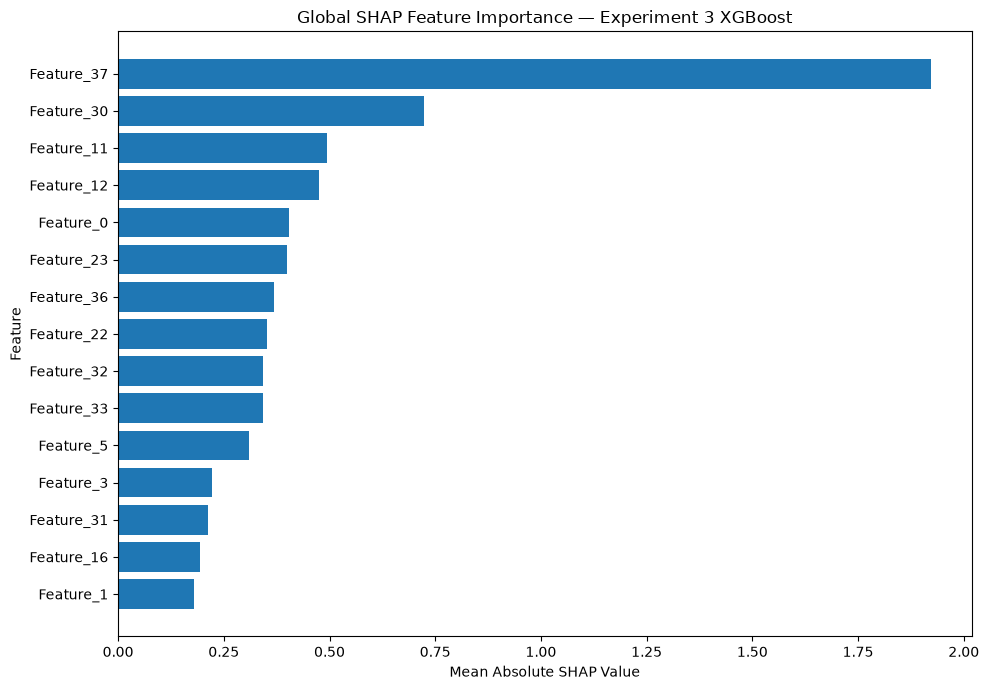

In [ ]:
global_importance = np.abs(shap_array).mean(axis = (0, 2))

importance_df = pd.DataFrame({
    "Feature": X_shap_df.columns,
    "Mean_Absolute_SHAP": global_importance
}).sort_values("Mean_Absolute_SHAP", ascending = False)

print("Top 15 features by global SHAP importance:")
print(importance_df.head(15).to_string(index = False, formatters = {"Mean_Absolute_SHAP": "{:.6f}".format}))

top_features = importance_df.head(15).sort_values("Mean_Absolute_SHAP")

plt.figure(figsize = (10, 7))
plt.barh(top_features["Feature"], top_features["Mean_Absolute_SHAP"])
plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.title("Global SHAP Feature Importance - Experiment 3 XGBoost")
plt.tight_layout()
plt.show()


Top 15 features for SQLINJECTION:
   Feature Mean_Absolute_SHAP
Feature_37           2.167601
Feature_36           1.842053
Feature_30           0.600077
Feature_12           0.302964
Feature_16           0.291270
Feature_34           0.290583
Feature_31           0.239289
 Feature_8           0.230279
Feature_32           0.202372
 Feature_3           0.178633
Feature_15           0.176752
Feature_23           0.151645
Feature_22           0.139651
 Feature_2           0.103479
 Feature_7           0.098339


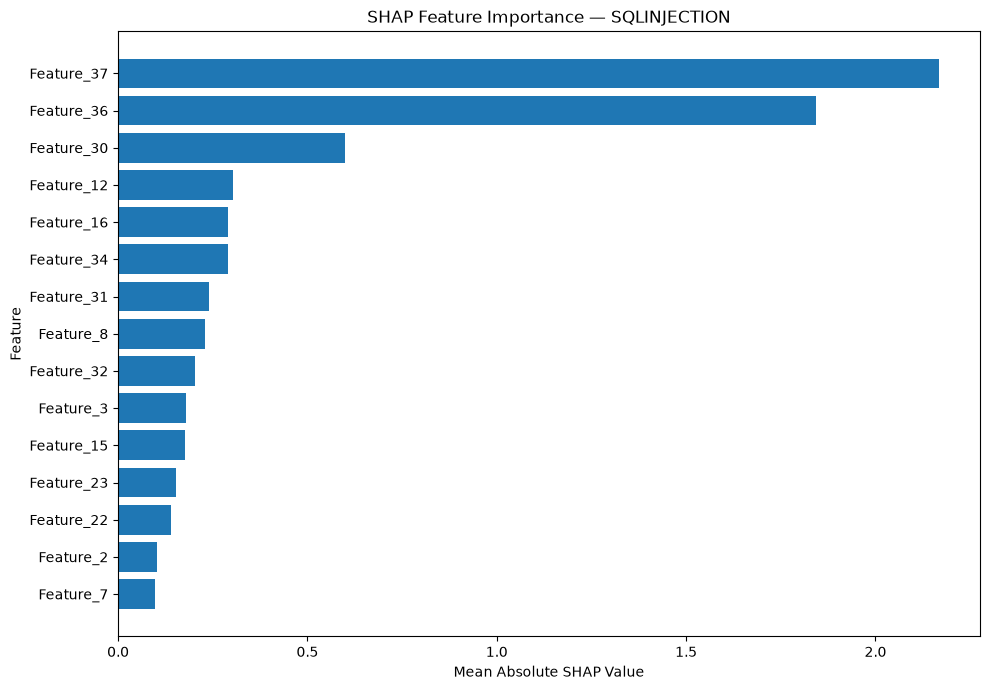

In [ ]:
sql_shap_values = shap_array[:, :, sql_id]
sql_importance = np.abs(sql_shap_values).mean(axis = 0)

sql_importance_df = pd.DataFrame({
    "Feature": X_shap_df.columns,
    "Mean_Absolute_SHAP": sql_importance
}).sort_values("Mean_Absolute_SHAP", ascending = False)

print("Top 15 features for SQLINJECTION:")
print(sql_importance_df.head(15).to_string(index = False, formatters = {"Mean_Absolute_SHAP": "{:.6f}".format}))

top_sql = sql_importance_df.head(15).sort_values("Mean_Absolute_SHAP")

plt.figure(figsize = (10, 7))
plt.barh(top_sql["Feature"], top_sql["Mean_Absolute_SHAP"])
plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.title("SHAP Feature Importance - SQLINJECTION")
plt.tight_layout()
plt.show()


In [ ]:
test_probs = experiment3_model.predict_proba(X_test)
test_pred = test_probs.argmax(axis = 1)
Y_test_array = np.asarray(Y_test).reshape(-1)

misclassified_indices = np.where((Y_test_array == sql_id) & (test_pred == vuln_id))[0]

print("SQLINJECTION -> VULNERABILITYSCAN cases:", len(misclassified_indices))

if len(misclassified_indices) == 0:
    raise ValueError("No matching misclassifications found.")

row_idx = int(misclassified_indices[0])
X_one = X_test[[row_idx]].copy()

print("\nSelected test row:", row_idx)
print("Actual class:", Y_test_array[row_idx])
print("Predicted class:", test_pred[row_idx])
print("SQLINJECTION probability:", float(test_probs[row_idx, sql_id]))
print("VULNERABILITYSCAN probability:", float(test_probs[row_idx, vuln_id]))
print("\nSelected row's features:")
print(X_one[0])


SQLINJECTION -> VULNERABILITYSCAN cases: 570

Selected test row: 1278
Actual class: 30
Predicted class: 32
SQLINJECTION probability: 0.01874898560345173
VULNERABILITYSCAN probability: 0.598638653755188

Selected row's features:
[2.4000000e+01 6.0000000e+00 6.0700001e+01 9.3343658e+01 1.0000000e-01
 0.0000000e+00 0.0000000e+00 2.0000000e-01 6.9999999e-01 0.0000000e+00
 0.0000000e+00 7.0000000e+00 0.0000000e+00 1.0000000e+00 0.0000000e+00
 0.0000000e+00 3.0000001e-01 0.0000000e+00 0.0000000e+00 0.0000000e+00
 0.0000000e+00 0.0000000e+00 6.9999999e-01 2.0000000e-01 0.0000000e+00
 0.0000000e+00 1.0000000e-01 0.0000000e+00 1.0000000e+00 1.0000000e+00
 9.7100000e+02 6.0000000e+01 2.1700000e+02 9.7099998e+01 6.1305157e+01
 9.7099998e+01 1.1289215e-02 1.0000000e+01 3.7583223e+03]


In [ ]:
sv_one = np.asarray(explainer.shap_values(X_one))

print("Individual SHAP shape:", sv_one.shape)

assert sv_one.shape == (1, 39, 34)

base_values = np.asarray(explainer.expected_value).reshape(-1)

print("SQLINJECTION baseline:", base_values[sql_id])
print("VULNERABILITYSCAN baseline:", base_values[vuln_id])

Individual SHAP shape: (1, 39, 34)
SQLINJECTION baseline: -2.318772
VULNERABILITYSCAN baseline: 1.3844361


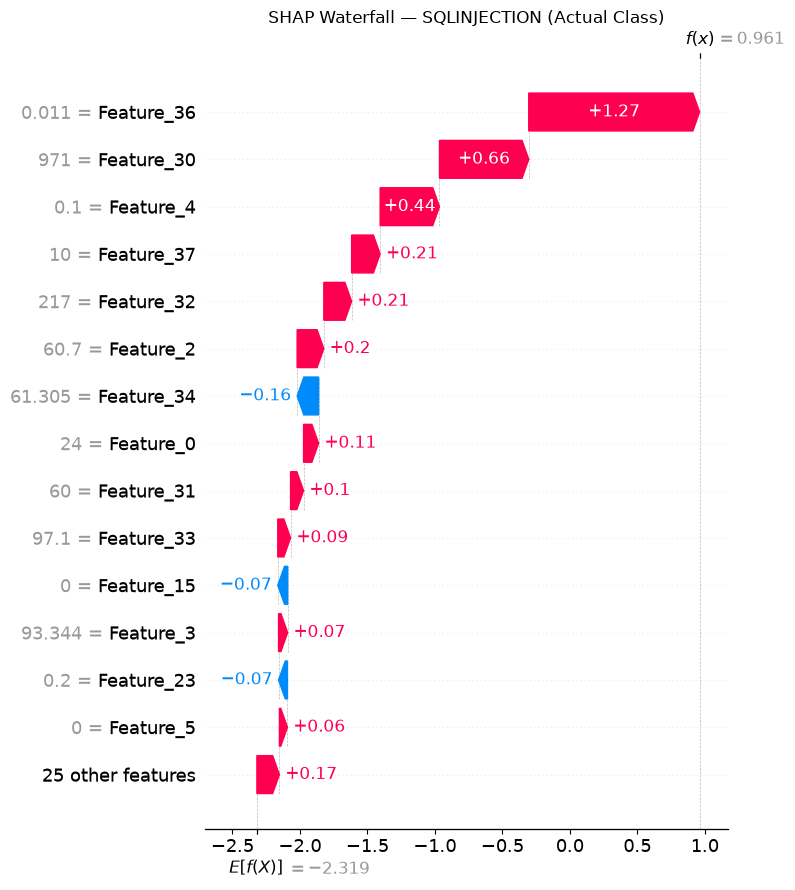

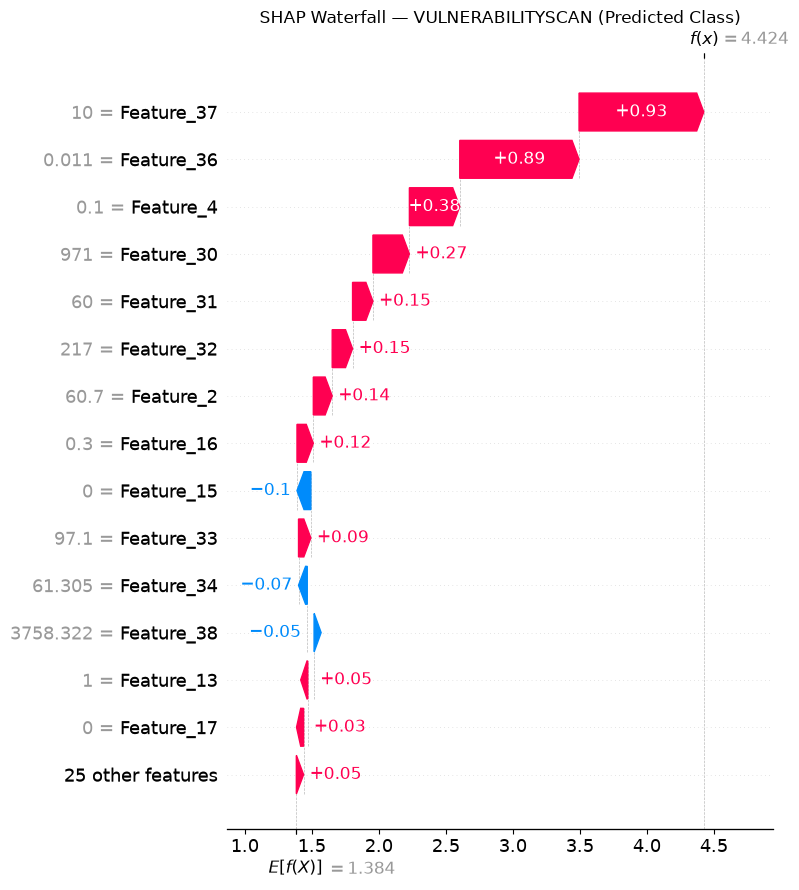

In [ ]:
sv_one = np.asarray(sv_one)
base_values = np.asarray(explainer.expected_value).reshape(-1)

assert sv_one.shape == (1, X_one.shape[1], 34)
assert len(base_values) == 34

exp_sql = shap.Explanation(
    values = sv_one[0, :, sql_id],
    base_values = base_values[sql_id],
    data = X_one[0],
    feature_names = feature_names
)

plt.close("all")
shap.plots.waterfall(exp_sql, max_display = 15, show = False)
plt.title("SHAP Waterfall - SQLINJECTION (Actual Class)")
plt.tight_layout()
plt.show()

exp_vuln = shap.Explanation(
    values = sv_one[0, :, vuln_id],
    base_values = base_values[vuln_id],
    data = X_one[0],
    feature_names = feature_names
)

plt.close("all")
shap.plots.waterfall(exp_vuln, max_display = 15, show = False)
plt.title("SHAP Waterfall - VULNERABILITYSCAN (Predicted Class)")
plt.tight_layout()
plt.show()


In [ ]:
print("SQLINJECTION baseline:", base_values[sql_id])
print("SQLINJECTION final output:", base_values[sql_id] + sv_one[0, :, sql_id].sum())

print("VULNERABILITYSCAN baseline:", base_values[vuln_id])
print("VULNERABILITYSCAN final output:", base_values[vuln_id] + sv_one[0, :, vuln_id].sum())

print("Predicted class:", test_pred[row_idx])
print("Class probabilities:", "SQLINJECTION =", test_probs[row_idx, sql_id], "| VULNERABILITYSCAN =", test_probs[row_idx, vuln_id])


SQLINJECTION baseline: -2.318772
SQLINJECTION final output: 0.9609773
VULNERABILITYSCAN baseline: 1.3844361
VULNERABILITYSCAN final output: 4.424494
Predicted class: 32
Class probabilities: SQLINJECTION = 0.018748986 | VULNERABILITYSCAN = 0.59863865


In [ ]:
comparison_df = pd.DataFrame({
    "Feature": feature_names,
    "Value": X_one[0],
    "SHAP_SQLINJECTION": sv_one[0, :, sql_id],
    "SHAP_VULNERABILITYSCAN": sv_one[0, :, vuln_id]
})

comparison_df["Difference_VULN_minus_SQL"] = (comparison_df["SHAP_VULNERABILITYSCAN"] - comparison_df["SHAP_SQLINJECTION"])

comparison_df["Abs_Difference"] = (comparison_df["Difference_VULN_minus_SQL"].abs())

print("Features with the largest differences between class explanations:")
print(comparison_df.sort_values("Abs_Difference", ascending = False)
    [["Feature", "Value", "SHAP_SQLINJECTION", "SHAP_VULNERABILITYSCAN", "Difference_VULN_minus_SQL"]].head(15).to_string(
        index = False, float_format = lambda x: f"{x:.5f}"
    )
)

Features with the largest differences between class explanations:
   Feature      Value  SHAP_SQLINJECTION  SHAP_VULNERABILITYSCAN  Difference_VULN_minus_SQL
Feature_37   10.00000            0.21118                 0.93062                    0.71944
Feature_30  971.00000            0.66140                 0.27194                   -0.38946
Feature_36    0.01129            1.26572                 0.89011                   -0.37561
Feature_16    0.30000           -0.02121                 0.12185                    0.14306
 Feature_0   24.00000            0.11139                 0.00476                   -0.10663
Feature_34   61.30516           -0.15904                -0.06520                    0.09385
 Feature_3   93.34366            0.06744                -0.02117                   -0.08861
 Feature_4    0.10000            0.43975                 0.37577                   -0.06398
 Feature_5    0.00000            0.05974                -0.00017                   -0.05991
 Feature_2   6

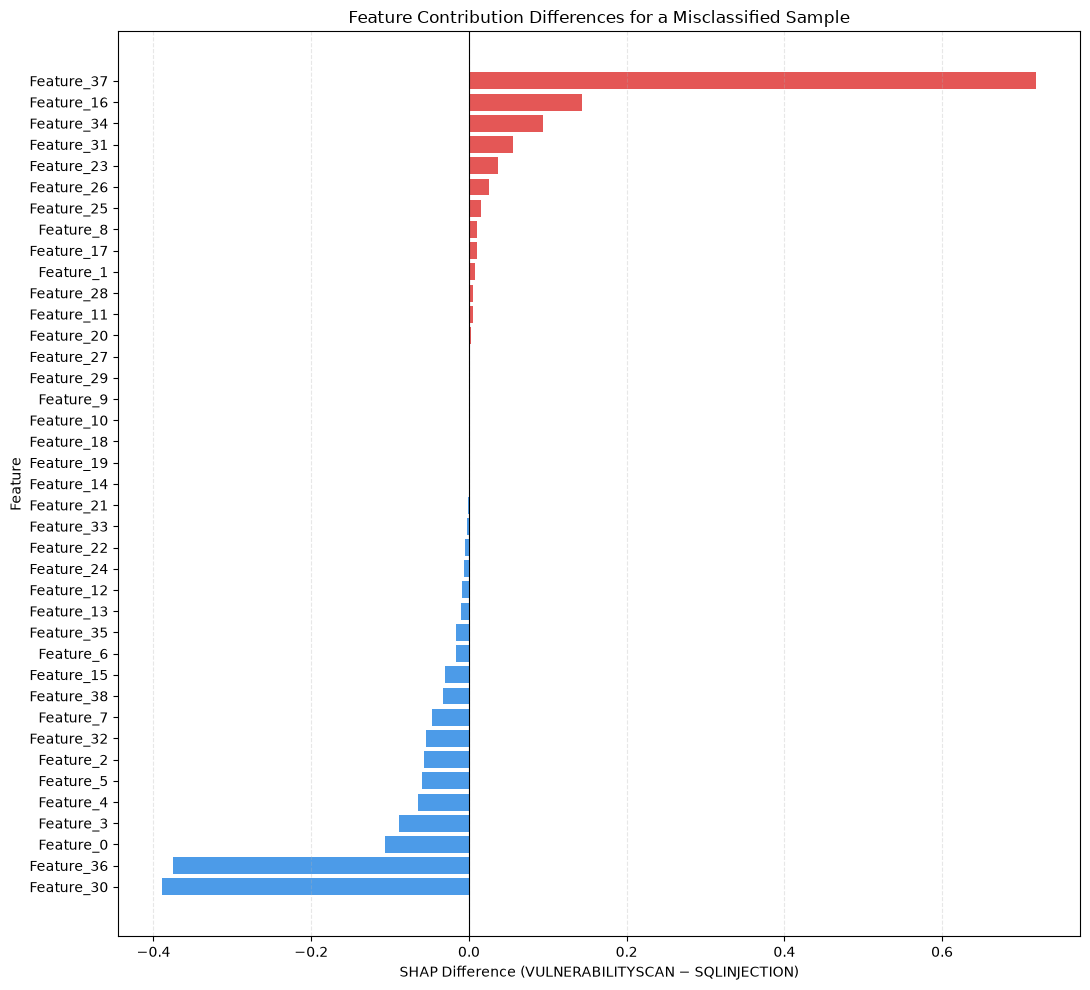

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

plot_df = comparison_df.sort_values("Difference_VULN_minus_SQL",ascending = True).copy()

plt.figure(figsize = (11, 10))

colors = ["#E45756" if value > 0 else "#4C9BE8" for value in plot_df["Difference_VULN_minus_SQL"]]

plt.barh(plot_df["Feature"], plot_df["Difference_VULN_minus_SQL"], color = colors)

plt.axvline(0, color = "black", linewidth = 0.8)
plt.xlabel("SHAP Difference (VULNERABILITYSCAN − SQLINJECTION)")
plt.ylabel("Feature")
plt.title("Feature Contribution Differences for a Misclassified Sample")
plt.grid(axis = "x", linestyle = "--", alpha = 0.3)
plt.tight_layout()
plt.show()


In [ ]:
shap.initjs()

print("Force Plot - SQLINJECTION (Actual Class)")

shap.force_plot(
    base_values[sql_id],
    sv_one[0, :, sql_id],
    X_one[0],
    matplotlib = True,
    show = False
)

plt.title("Force Plot - SQLINJECTION")
plt.tight_layout()
plt.show()

print("Force Plot - VULNERABILITYSCAN (Predicted Class)")

shap.force_plot(
    base_values[vuln_id],
    sv_one[0, :, vuln_id],
    X_one[0],
    matplotlib = True,
    show = False
)

plt.title("Force Plot - VULNERABILITYSCAN")
plt.tight_layout()
plt.show()


NameError: name 'shap' is not defined

CICIoT2023 Work Done

CICIoMT2024 Dataset

In [1]:
%reset -f

import gc
gc.collect()

0

In [2]:
import os
import pandas as pd
from pathlib import Path

folder = Path("CICIoMT2024/attacks/train")

expected_columns = set()

for file in folder.rglob("*.csv"):
    df = pd.read_csv(file)
    expected_columns.update(df.columns)

expected_columns = list(expected_columns)

print(expected_columns)
print(len(expected_columns))

['UDP', 'Magnitue', 'IGMP', 'IPv', 'syn_flag_number', 'Min', 'AVG', 'fin_count', 'psh_flag_number', 'Telnet', 'Protocol Type', 'SSH', 'IAT', 'Variance', 'ICMP', 'fin_flag_number', 'ack_flag_number', 'Drate', 'Covariance', 'LLC', 'Tot size', 'Std', 'Srate', 'syn_count', 'Max', 'DNS', 'HTTPS', 'Duration', 'ece_flag_number', 'Radius', 'ARP', 'IRC', 'Header_Length', 'Label', 'SMTP', 'DHCP', 'rst_count', 'Tot sum', 'Weight', 'Rate', 'HTTP', 'cwr_flag_number', 'rst_flag_number', 'Number', 'TCP', 'ack_count']
46


In [3]:
check = False

for col in expected_columns:
    if col == 'Label':
        check = True
        print(check)
        break
if not check:
    print("'Label' is not present.")

True


In [5]:
import os
import gc
import numpy as np
import pandas as pd
from pathlib import Path

def merge_files(input_path, output_path):
    files = sorted(input_path.glob("*.csv"))
    total_files = len(files)

    for i, file in enumerate(files, start = 1):
        print(f"Merging files...  Status: {i}/{total_files} - {file.name}")
        df_temp = pd.read_csv(file)
        df_temp.to_csv(output_path, mode = "w" if i == 1 else "a",index = False, header = i == 1)
        del df_temp
        gc.collect()

    print(f"\nMerged File Saved to {output_path}.\n")

path_train_folder = Path("CICIoMT2024/attacks/train")
path_test_folder = Path("CICIoMT2024/attacks/test")

dest_folder = Path("CICIoMT2024_Working/Merged_datasets")

dest_folder.mkdir(parents = True, exist_ok = True)

output = dest_folder / "Merged_train.csv"

merge_files(path_train_folder, output)

output = dest_folder / "Merged_test.csv"

merge_files(path_test_folder, output)


Merging files...  Status: 1/51 - ARP_Spoofing_train.pcap.csv
Merging files...  Status: 2/51 - Benign_train.pcap.csv
Merging files...  Status: 3/51 - MQTT-DDoS-Connect_Flood_train.pcap.csv
Merging files...  Status: 4/51 - MQTT-DDoS-Publish_Flood_train.pcap.csv
Merging files...  Status: 5/51 - MQTT-DoS-Connect_Flood_train.pcap.csv
Merging files...  Status: 6/51 - MQTT-DoS-Publish_Flood_train.pcap.csv
Merging files...  Status: 7/51 - MQTT-Malformed_Data_train.pcap.csv
Merging files...  Status: 8/51 - Recon-OS_Scan_train.pcap.csv
Merging files...  Status: 9/51 - Recon-Ping_Sweep_train.pcap.csv
Merging files...  Status: 10/51 - Recon-Port_Scan_train.pcap.csv
Merging files...  Status: 11/51 - Recon-VulScan_train.pcap.csv
Merging files...  Status: 12/51 - TCP_IP-DDoS-ICMP1_train.pcap.csv
Merging files...  Status: 13/51 - TCP_IP-DDoS-ICMP2_train.pcap.csv
Merging files...  Status: 14/51 - TCP_IP-DDoS-ICMP3_train.pcap.csv
Merging files...  Status: 15/51 - TCP_IP-DDoS-ICMP4_train.pcap.csv
Merging

In [6]:
import numpy as np

def load_dataset(file_path):
    return pd.read_csv(file_path)

def validate_columns(df, expected_columns):
    missing = set(expected_columns) - set(df.columns)
    extra = set(df.columns) - set(expected_columns)

    if missing:
        print("Missing columns:", missing)

    if extra:
        print("Unexpected columns:", extra)

    return not missing and not extra

def handle_duplicates(df):
    print('\nDuplicate rows:', df.duplicated().sum())

    df = df.drop_duplicates()

    print('Duplicated rows left:', df.duplicated().sum())
    return df

def handle_invalid_values(df):
    count = np.isinf(df.select_dtypes(include = np.number)).sum().sum()
    print('\nInfinite values:', count)

    df = df.replace([np.inf, -np.inf], np.nan)

    count = np.isinf(df.select_dtypes(include = np.number)).sum().sum()
    print('Infinite values left:', count)
    return df

def handle_missing_values(df):
    print('\nMissing values before handling:')
    print(df.isnull().sum().sum())

    df = df.dropna(subset = ['Label']).copy()

    feature_cols = df.columns.drop('Label')
    numeric_cols = df[feature_cols].select_dtypes(include = np.number).columns
    categorical_cols = feature_cols.difference(numeric_cols)

    for col in numeric_cols:
        if df[col].isnull().sum():
            median_value = df[col].median()

            if pd.notna(median_value):
                df[col] = df[col].fillna(median_value)

    for col in categorical_cols:
        if df[col].isnull().sum():
            mode_values = df[col].mode()

            if not mode_values.empty:
                df[col] = df[col].fillna(mode_values.iloc[0])

    print('\nMissing values after handling:')
    print(df.isnull().sum().sum())

    return df

def encode_labels(df, encoder):
    df = df.copy()
    df['Label'] = encoder.transform(df['Label'])
    print('\nLabel encoded successfully.')

    return df

def preprocess_dataset(file_path, expected_columns):
    df = load_dataset(file_path)

    if not validate_columns(df, expected_columns):
        raise ValueError("Dataset schema validation failed.")

    df = handle_duplicates(df)
    df = handle_invalid_values(df)
    df = handle_missing_values(df)
    df = encode_labels(df, target_encoder)

    return df

In [7]:
import gc
import pandas as pd
from sklearn.preprocessing import LabelEncoder

df = pd.read_csv("CICIoMT2024_Working/Merged_datasets/Merged_test.csv", usecols = ["Label"])

labels = df['Label'].unique().tolist()

target_encoder = LabelEncoder()

target_encoder.fit_transform(labels)

print(dict(enumerate(target_encoder.classes_)))

del df
gc.collect()

{0: np.str_('Benign'), 1: np.str_('DDoS'), 2: np.str_('DoS'), 3: np.str_('MQTT'), 4: np.str_('Recon'), 5: np.str_('Spoofing')}


20

In [8]:
from pathlib import Path
import numpy as np

input_folder = Path("CICIoMT2024_Working/Merged_datasets")
output_folder = Path("CICIoMT2024_Working/Preprocessed_datasets")
output_folder.mkdir(parents = True, exist_ok = True)

csv_files = sorted(input_folder.glob("*.csv"))

print("Files found:", len(csv_files))

for i, file_path in enumerate(csv_files, start = 1):
    print(f"\nProcessing {i}/{len(csv_files)}: {file_path.name}")

    df = preprocess_dataset(file_path, expected_columns)

    output_path = output_folder / file_path.name
    df.to_csv(output_path, index = False)

    print("Saved:", output_path.name)
    print("Final shape:", df.shape)

    del df
    gc.collect()

Files found: 2

Processing 1/2: Merged_test.csv

Duplicate rows: 2065
Duplicated rows left: 0

Infinite values: 0
Infinite values left: 0

Missing values before handling:
0

Missing values after handling:
0

Label encoded successfully.
Saved: Merged_test.csv
Final shape: (1612117, 46)

Processing 2/2: Merged_train.csv

Duplicate rows: 5143
Duplicated rows left: 0

Infinite values: 0
Infinite values left: 0

Missing values before handling:
0

Missing values after handling:
0

Label encoded successfully.
Saved: Merged_train.csv
Final shape: (7155688, 46)


In [9]:
import pandas as pd

df = pd.read_csv("CICIoMT2024_Working/Preprocessed_datasets/Merged_train.csv")
df.head()

,Header_Length,Protocol Type,Duration,Rate,Srate,Drate,fin_flag_number,syn_flag_number,rst_flag_number,psh_flag_number,...,Std,Tot size,IAT,Number,Magnitue,Radius,Covariance,Variance,Weight,Label
0,866.6,10.4,64.0,45722.390220,45722.390220,0.0,0.0,0.0,0.0,0.3,...,150.681076,431.8,1.694026e+08,5.5,16.963645,213.095222,66236.07648,0.9,38.5,5
1,3934.3,12.6,131.2,35708.799480,35708.799480,0.0,0.0,0.0,0.0,0.3,...,500.702909,406.3,1.694026e+08,13.5,30.885371,708.919620,251721.12680,1.0,244.6,5
2,5592.8,12.6,97.6,66.403506,66.403506,0.0,0.0,0.0,0.0,0.3,...,205.552035,386.6,1.361110e-02,5.5,21.787095,290.694475,84028.64753,0.9,38.5,5
3,9303.6,14.8,80.8,51.201280,51.201280,0.0,0.0,0.0,0.0,0.1,...,421.683660,300.2,1.694026e+08,13.5,26.954506,597.046005,178453.00170,1.0,244.6,5
4,8592.4,12.6,98.6,42.706455,42.706455,0.0,0.0,0.0,0.0,0.2,...,265.394239,209.2,1.393099e-02,5.5,24.255148,375.324132,80115.11073,0.9,38.5,5


In [10]:
X_train = df.drop('Label', axis = 1)
Y_train = df['Label']

In [11]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

In [12]:
import gc

del df
gc.collect()

0

In [13]:
import time
from sklearn.tree import DecisionTreeClassifier
from cuml.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from cuml.svm import LinearSVC
from cuml.linear_model import LogisticRegression

def train_models(models, X, Y):
    for name, model in models.items():
        print(f"Training {name}...")
        start_time = time.perf_counter()
        model.fit(X, Y)
        end_time = time.perf_counter()
        print(f"Training time: {end_time - start_time:.2f} seconds\n")

dt = DecisionTreeClassifier(random_state = 42)
rf = RandomForestClassifier(random_state = 42)
xgb = XGBClassifier(random_state = 42, device = 'cuda')
svm = LinearSVC(max_iter = 1000000, C = 200)
lr = LogisticRegression(max_iter = 20000, C = 0.1, class_weight = "balanced")

models = {
    "Decision Tree" : dt,
    "Random Forest" : rf,
    "XGBoost" : xgb
}

scaled_models = {
    "SVM" : svm,
    "Logistic Regression" : lr
}

train_models(models, X_train, Y_train)
train_models(scaled_models, X_train_scaled, Y_train)

Training Decision Tree...
Training time: 18.79 seconds

Training Random Forest...
Training time: 70.56 seconds

Training XGBoost...
Training time: 28.91 seconds

Training SVM...
Training time: 12.53 seconds

Training Logistic Regression...
Training time: 205.82 seconds



In [14]:
df = pd.read_csv("CICIoMT2024_Working/Preprocessed_datasets/Merged_test.csv")
df.head()

,Header_Length,Protocol Type,Duration,Rate,Srate,Drate,fin_flag_number,syn_flag_number,rst_flag_number,psh_flag_number,...,Std,Tot size,IAT,Number,Magnitue,Radius,Covariance,Variance,Weight,Label
0,3609.0,17.0,64.0,212.961498,212.961498,0.0,0.0,0.0,0.0,0.0,...,487.409300,673.2,1.694027e+08,5.5,34.695355,689.300842,279086.099527,0.9,38.5,5
1,9531.4,17.0,64.0,442.954430,442.954430,0.0,0.0,0.0,0.0,0.0,...,511.518567,500.4,1.694027e+08,13.5,35.198404,725.048676,264633.896422,1.0,244.6,5
2,6372.4,11.5,64.0,28457.581790,28457.581790,0.0,0.0,0.0,0.0,0.3,...,176.007057,201.5,8.456492e-03,5.5,23.432541,248.911567,34444.026196,0.9,38.5,5
3,129.2,6.0,64.0,105851.136945,105851.136945,0.0,0.0,0.0,0.0,0.5,...,161.986428,81.3,1.694027e+08,13.5,17.959288,229.542470,26471.574324,1.0,244.6,5
4,12130.7,14.8,81.4,4896.846315,4896.846315,0.0,0.0,0.0,0.0,0.1,...,159.594551,325.9,1.157858e-02,5.5,23.749589,225.700779,28511.557770,0.9,38.5,5


In [15]:
X_test = df.drop('Label', axis = 1)
Y_test = df['Label']

X_test_scaled = scaler.transform(X_test)

del df
gc.collect()

75

In [16]:
result = {}
report = {}

In [17]:
from sklearn.metrics import accuracy_score, classification_report

def get_results(models, X_test, result, report):
    for name, model in models.items():
        pred = model.predict(X_test)
        result[name] = accuracy_score(Y_test, pred)
        report[name] = classification_report(Y_test, pred, zero_division = 0)

get_results(models, X_test, result, report)
get_results(scaled_models, X_test_scaled, result, report)

/home/asim_azhar/miniforge3/envs/rapids/lib/python3.13/site-packages/xgboost/core.py:569: UserWarning: [03:10:17] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


In [18]:
for name in result:
    print(f"{name} accuracy:", result[name])
    print(report[name])

Decision Tree accuracy: 0.9983140181512881
              precision    recall  f1-score   support

           0       0.98      0.97      0.97     37607
           1       1.00      1.00      1.00   1117094
           2       1.00      1.00      1.00    428312
           3       0.93      0.86      0.89      1747
           4       0.98      0.98      0.98     25613
           5       0.60      0.81      0.69      1744

    accuracy                           1.00   1612117
   macro avg       0.91      0.94      0.92   1612117
weighted avg       1.00      1.00      1.00   1612117

Random Forest accuracy: 0.9922964648347483
              precision    recall  f1-score   support

           0       0.95      0.96      0.96     37607
           1       1.00      0.99      1.00   1117094
           2       0.98      1.00      0.99    428312
           3       0.99      0.78      0.87      1747
           4       0.95      0.95      0.95     25613
           5       0.63      0.65      0.64   

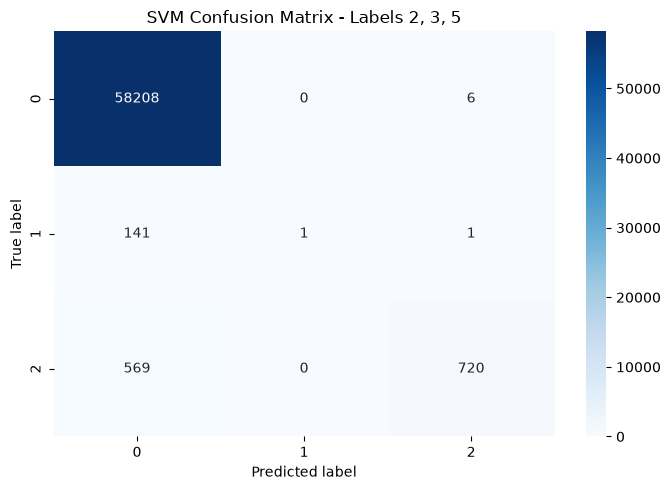

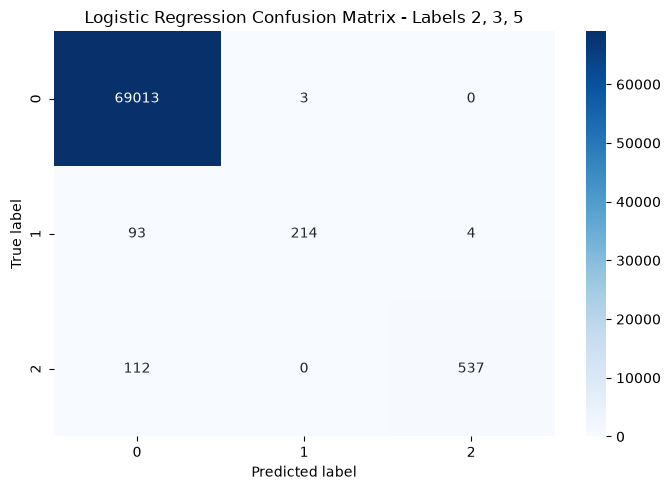

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import confusion_matrix

def print_confusion_mat(name, pred, Y_test):

    mask = np.isin(Y_test, [2, 3, 5]) & np.isin(pred, [2, 3, 5]) 

    cm = confusion_matrix(Y_test[mask], pred[mask], labels = [2, 3, 5])

    plt.figure(figsize = (7, 5))
    sns.heatmap(cm, annot = True, fmt = "d", cmap = "Blues")
    plt.xlabel("Predicted label")
    plt.ylabel("True label")
    plt.title(f"{name} Confusion Matrix - Labels 2, 3, 5")
    plt.tight_layout()
    plt.show()

for name, model in scaled_models.items():
    pred = model.predict(X_test_scaled)
    print_confusion_mat(name, pred, Y_test)


In [20]:
df = pd.read_csv("CICIoMT2024_Working/Merged_datasets/Merged_test.csv")

features = df.drop("Label", axis = 1).columns.tolist()

del df, result, report
gc.collect()

importance_df = pd.DataFrame({
    "Feature" : features,
    "Decision Tree" : dt.feature_importances_,
    "Random Forest" : rf.feature_importances_,
    "XGBoost" : xgb.feature_importances_,
})

model_cols = ["Decision Tree", "Random Forest", "XGBoost"]

for col in model_cols:
    importance_df[col] = importance_df[col] / importance_df[col].sum()

importance_df["Average Importance"] = importance_df[model_cols].mean(axis = 1)

top20_features = (importance_df.sort_values(by = "Average Importance", ascending = False))

display(top20_features)

,Feature,Decision Tree,Random Forest,XGBoost,Average Importance
38,IAT,0.955815,0.675997,0.026610,0.552807
24,TCP,0.000038,0.003564,0.263230,0.088944
28,ICMP,0.000008,0.001179,0.222724,0.074637
27,ARP,0.000035,0.000000,0.141101,0.047045
1,Protocol Type,0.000049,0.003749,0.086688,0.030162
16,rst_count,0.000886,0.026620,0.032692,0.020066
33,Min,0.000182,0.006506,0.050531,0.019073
15,fin_count,0.015882,0.011585,0.024259,0.017242
4,Srate,0.002423,0.036904,0.000000,0.013109
3,Rate,0.000885,0.029020,0.007976,0.012627


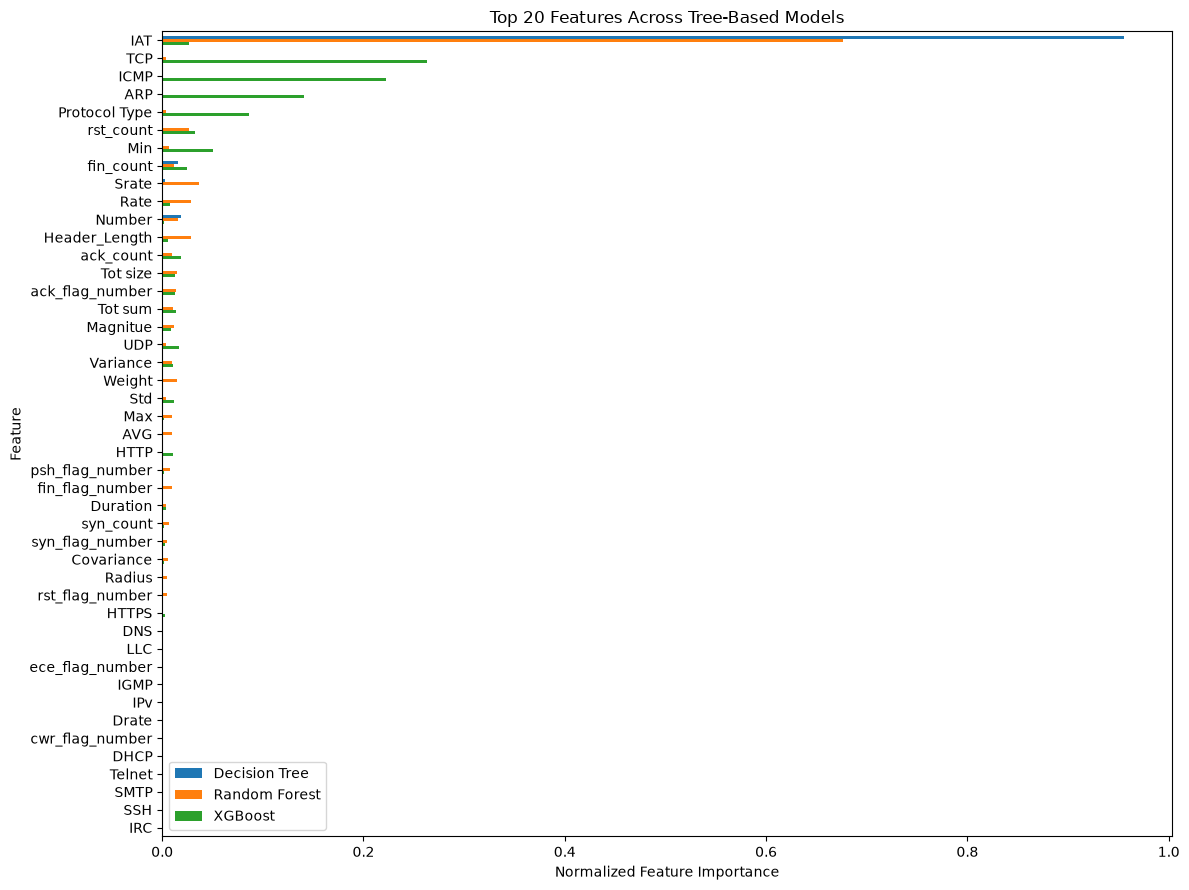

In [21]:
import matplotlib.pyplot as plt

top20_features.set_index("Feature")[model_cols].plot(kind = "barh", figsize = (12, 9))

plt.gca().invert_yaxis()
plt.xlabel("Normalized Feature Importance")
plt.title("Top 20 Features Across Tree-Based Models")
plt.tight_layout()
plt.show()

In [22]:
gc.collect()

13203

In [23]:
from sklearn.base import clone
from sklearn.metrics import f1_score, recall_score

top20_feature_names = top20_features["Feature"].head(20).tolist()

X_train_top = X_train.loc[:, top20_feature_names].copy()
X_test_top = X_test.loc[:, top20_feature_names].copy()

results = []

for name, model in models.items():
    tuned_model = clone(model)
    tuned_model.fit(X_train_top, Y_train)

    pred = tuned_model.predict(X_test_top)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(Y_test, pred),
        "Macro F1": f1_score(Y_test, pred, average = "macro"),
        "Macro Recall": recall_score(Y_test, pred, average =  "macro")
    })
    del tuned_model
    gc.collect()

results = pd.DataFrame(results)

display(results)
gc.collect()

,Model,Accuracy,Macro F1,Macro Recall
0,Decision Tree,0.997763,0.913979,0.920379
1,Random Forest,0.992542,0.895364,0.875458
2,XGBoost,0.995217,0.888035,0.892250


0

In [24]:
parameter_list = [
    {"max_depth": 6, "learning_rate": 0.1, "n_estimators": 100},
    {"max_depth": 8, "learning_rate": 0.1, "n_estimators": 100},
    {"max_depth": 6, "learning_rate": 0.05, "n_estimators": 200}
]

results = []

for i, params in enumerate(parameter_list, start = 1):
    print(f"Training configuration {i}/{len(parameter_list)}: {params}")

    model = XGBClassifier(
        **params,
        objective = "multi:softprob",
        num_class = 6,
        eval_metric = "mlogloss",
        tree_method = "hist",
        n_jobs = 4,
        random_state = 42
    )

    model.fit(X_train_top, Y_train)
    pred = model.predict(X_test_top)

    results.append({
        "Configuration" : i,
        **params,
        "Accuracy" : accuracy_score(Y_test, pred),
        "Macro F1" : f1_score(Y_test, pred, average = "macro"),
        "Macro Recall" : recall_score(Y_test, pred, average = "macro")
    })

    del model, pred
    gc.collect()

results = pd.DataFrame(results)
display(results.sort_values("Macro F1", ascending = False))

del results
gc.collect()

Training configuration 1/3: {'max_depth': 6, 'learning_rate': 0.1, 'n_estimators': 100}
Training configuration 2/3: {'max_depth': 8, 'learning_rate': 0.1, 'n_estimators': 100}
Training configuration 3/3: {'max_depth': 6, 'learning_rate': 0.05, 'n_estimators': 200}


,Configuration,max_depth,learning_rate,n_estimators,Accuracy,Macro F1,Macro Recall
1,2,8,0.10,100,0.997707,0.914931,0.897331
0,1,6,0.10,100,0.997634,0.911185,0.887656
2,3,6,0.05,200,0.997944,0.907982,0.913126


0

Accuracy: 0.997706742128518
              precision    recall  f1-score   support

      Benign     0.9636    0.9627    0.9631     37607
        DDos     0.9996    0.9999    0.9998   1117094
         Dos     0.9998    0.9989    0.9994    428312
        MQTT     0.9804    0.8002    0.8812      1747
       Recon     0.9488    0.9686    0.9586     25613
    Spoofing     0.7252    0.6537    0.6876      1744

    accuracy                         0.9977   1612117
   macro avg     0.9362    0.8973    0.9149   1612117
weighted avg     0.9977    0.9977    0.9977   1612117



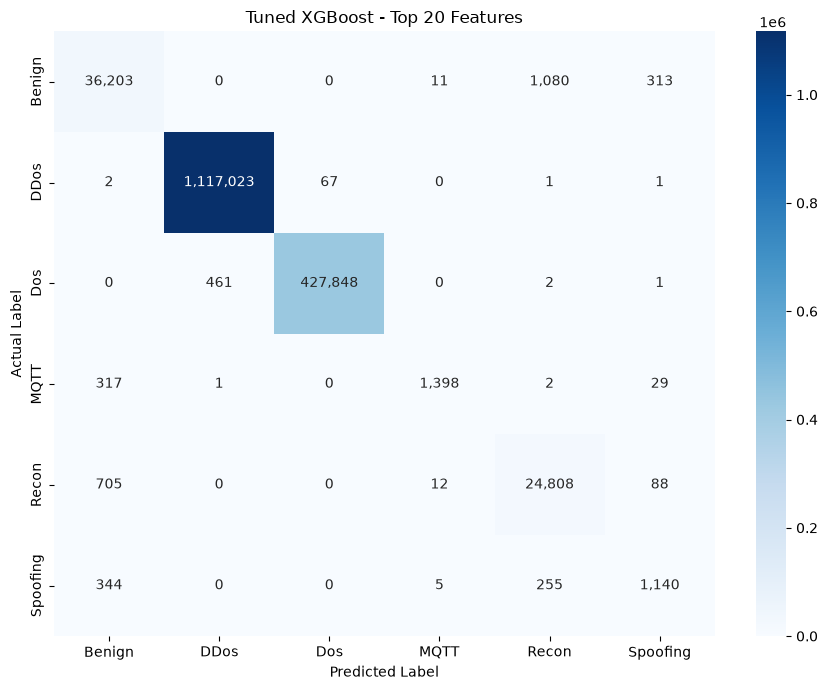

6262

In [25]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

xgb_best = XGBClassifier(
    max_depth = 8,
    learning_rate = 0.1,
    n_estimators = 100,
    objective = "multi:softprob",
    num_class = 6,
    eval_metric = "mlogloss",
    tree_method = "hist",
    n_jobs = 4,
    random_state = 42
)

xgb_best.fit(X_train_top, Y_train)
pred = xgb_best.predict(X_test_top)

labels = ["Benign", "DDos", "Dos", "MQTT", "Recon", "Spoofing"]
print("Accuracy:", accuracy_score(Y_test, pred))
print(classification_report(Y_test, pred, labels = [0, 1, 2, 3, 4, 5], target_names = labels, digits = 4, zero_division = 0))

cm = confusion_matrix(Y_test, pred, labels = [0, 1, 2, 3, 4, 5])

plt.figure(figsize = (9, 7))
sns.heatmap(cm, annot = True, cmap = "Blues", fmt = ",", xticklabels = labels, yticklabels = labels)
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Tuned XGBoost - Top 20 Features")
plt.tight_layout()
plt.show()

gc.collect()

In [26]:
print("Actual test-label counts:")
print(pd.Series(Y_test).value_counts().sort_index().rename(index = dict(enumerate(target_encoder.classes_))))

print("\nPrediction-label counts:")
print(pd.Series(pred).value_counts().sort_index().rename(index = dict(enumerate(target_encoder.classes_))))

print("\nConfusion matrix:")
print(confusion_matrix(Y_test, pred))

Actual test-label counts:
Label
Benign        37607
DDoS        1117094
DoS          428312
MQTT           1747
Recon         25613
Spoofing       1744
Name: count, dtype: int64

Prediction-label counts:
Benign        37571
DDoS        1117485
DoS          427915
MQTT           1426
Recon         26148
Spoofing       1572
Name: count, dtype: int64

Confusion matrix:
[[  36203       0       0      11    1080     313]
 [      2 1117023      67       0       1       1]
 [      0     461  427848       0       2       1]
 [    317       1       0    1398       2      29]
 [    705       0       0      12   24808      88]
 [    344       0       0       5     255    1140]]


In [27]:
import numpy as np
import pandas as pd
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(Y_train)

weights = compute_class_weight(class_weight = "balanced", classes = classes, y = Y_train)

weight_map = dict(zip(classes, weights))

print(weight_map)

{np.int64(0): np.float64(6.187943188814866), np.int64(1): np.float64(0.23948826262231135), np.int64(2): np.float64(0.6402688315783333), np.int64(3): np.float64(232.47849252761534), np.int64(4): np.float64(12.012758656580614), np.int64(5): np.float64(74.4314214982629)}


In [28]:
sample_weights = Y_train.map(weight_map).to_numpy()

xgb_weighted = XGBClassifier(
    max_depth = 8,
    learning_rate = 0.1,
    n_estimators = 100,
    objective = "multi:softprob",
    num_class = 6,
    eval_metric = "mlogloss",
    tree_method = "hist",
    n_jobs = 2,
    random_state = 42
)

xgb_weighted.fit(X_train_top, Y_train, sample_weight = sample_weights)

pred = xgb_weighted.predict(X_test_top)

print("Accuracy:", accuracy_score(Y_test, pred))
print("Macro F1:", f1_score(Y_test, pred, average = "macro"))
print("Macro Recall:", recall_score(Y_test, pred, average = "macro"))

print(classification_report(
    Y_test,
    pred,
    labels = [0, 1, 2, 3, 4, 5],
    target_names = ["Benign", "DDoS", "DoS", "MQTT", "Recon", "Spoofing"],
    digits = 4,
    zero_division = 0
))

gc.collect()

Accuracy: 0.9917319896756873
Macro F1: 0.8762930108577979
Macro Recall: 0.9623093438600797
              precision    recall  f1-score   support

      Benign     0.9927    0.9126    0.9510     37607
        DDoS     0.9990    0.9929    0.9959   1117094
         DoS     0.9819    0.9972    0.9895    428312
        MQTT     0.7745    0.9513    0.8538      1747
       Recon     0.9950    0.9685    0.9816     25613
    Spoofing     0.3263    0.9513    0.4859      1744

    accuracy                         0.9917   1612117
   macro avg     0.8449    0.9623    0.8763   1612117
weighted avg     0.9932    0.9917    0.9922   1612117



53

In [29]:
import shap

X_background = X_train_top.sample(n = 1000, random_state = 42).copy()
X_explain = X_test_top.sample(n = 1000, random_state = 42).copy()

print(X_background.shape)
print(X_explain.shape)

gc.collect()

(1000, 20)
(1000, 20)


20

In [30]:
explainer = shap.TreeExplainer(xgb_best)

shap_values = explainer.shap_values(X_explain)

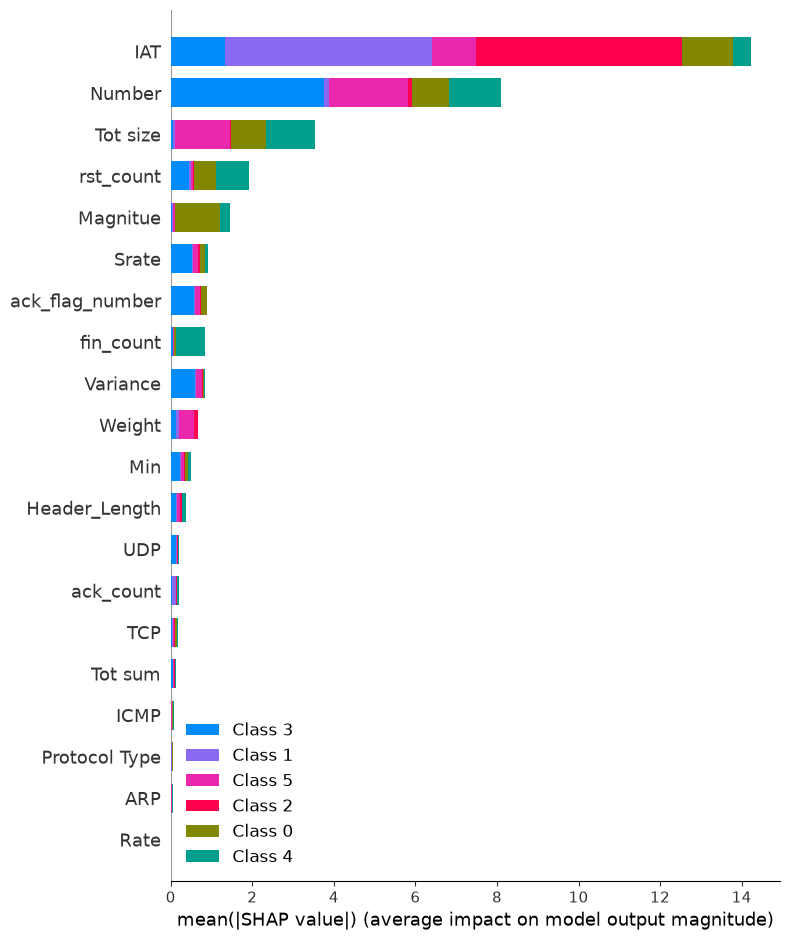

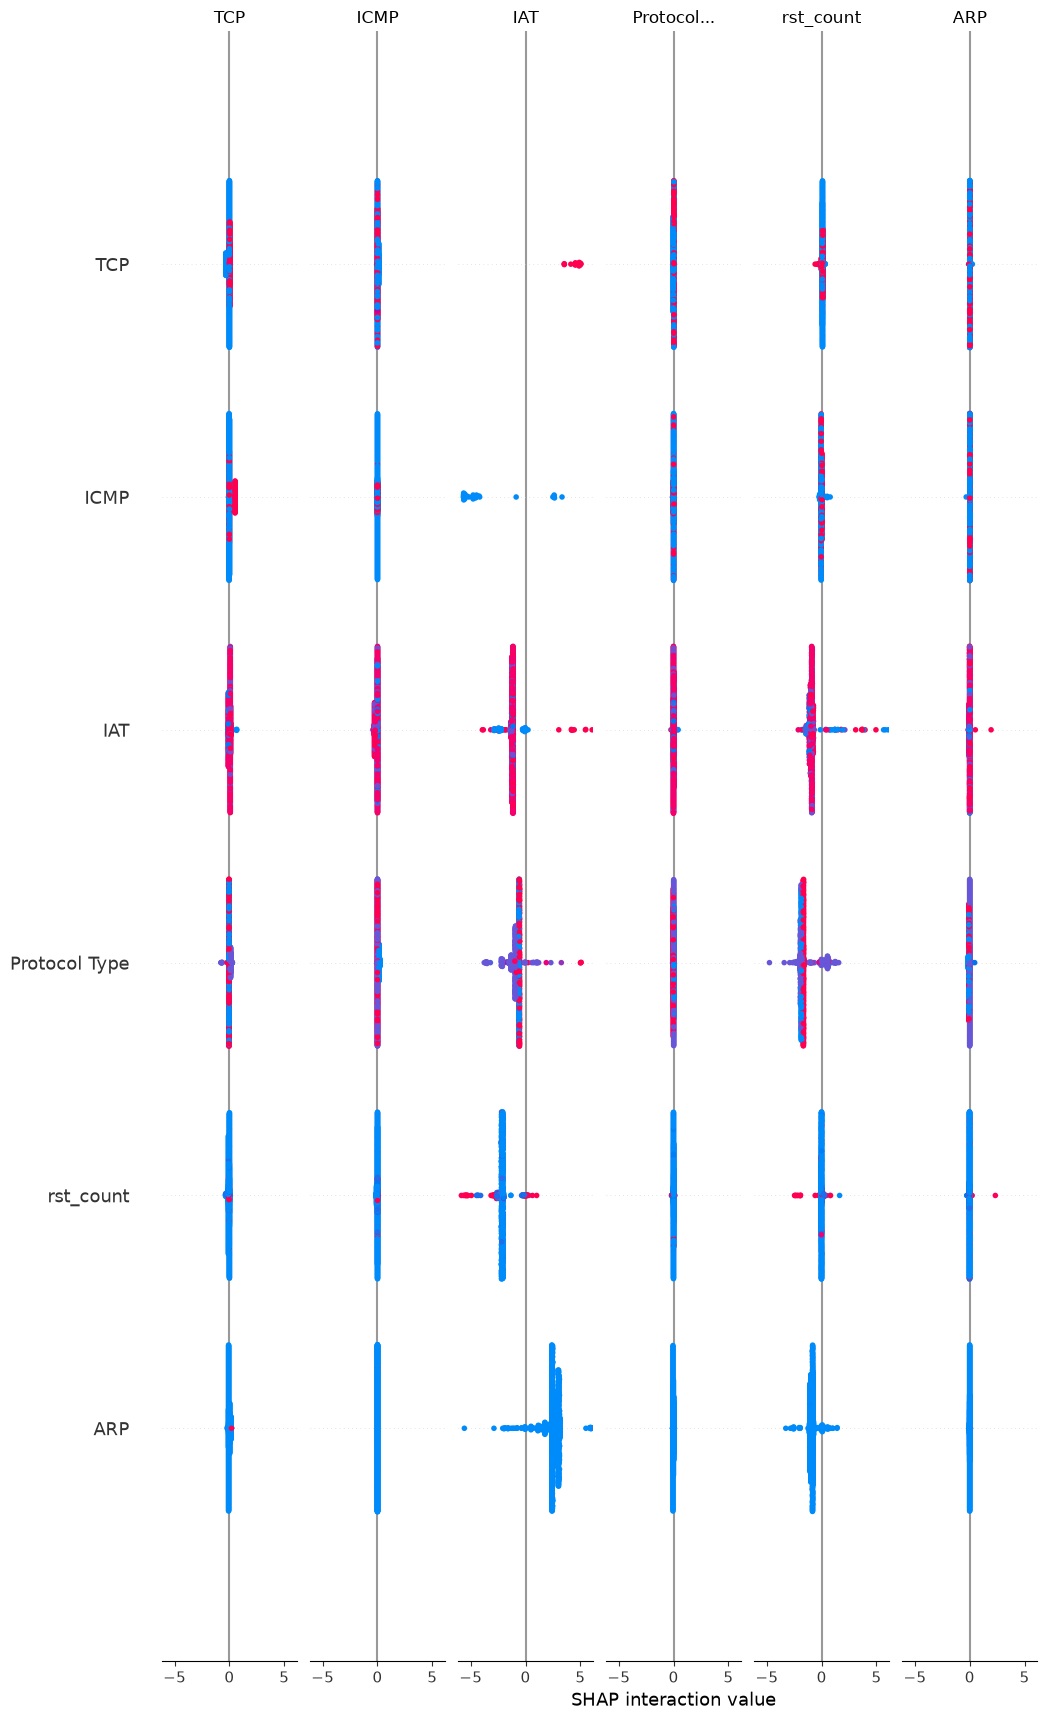

In [31]:
shap.summary_plot(shap_values, X_explain, plot_type = "bar", max_display = 20)
shap.summary_plot(shap_values, X_explain, max_display = 20)

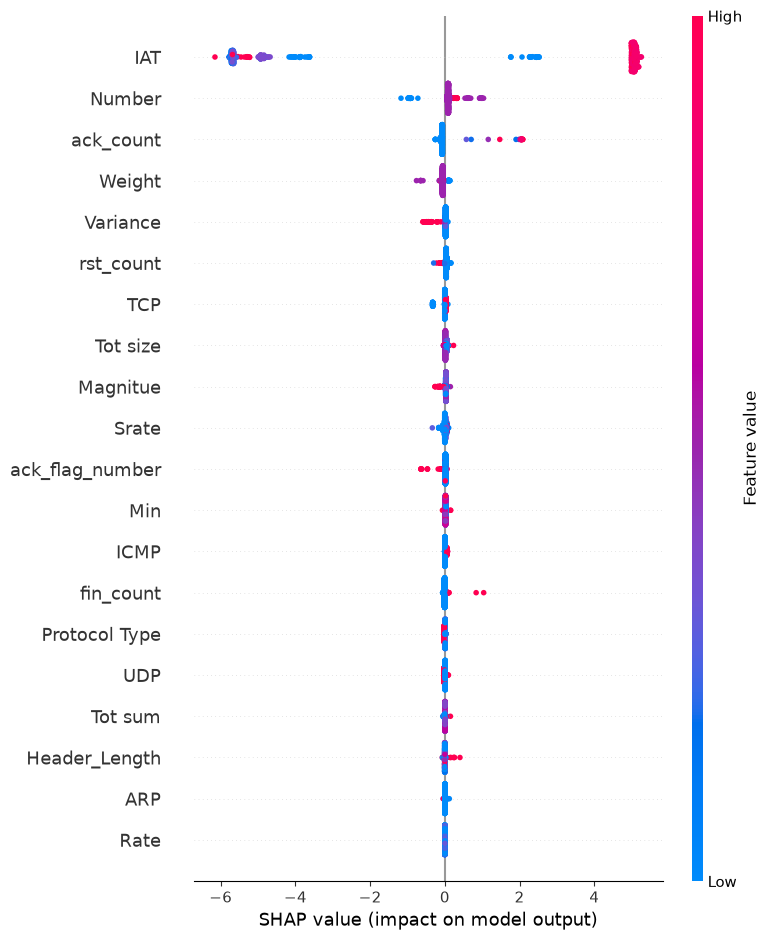

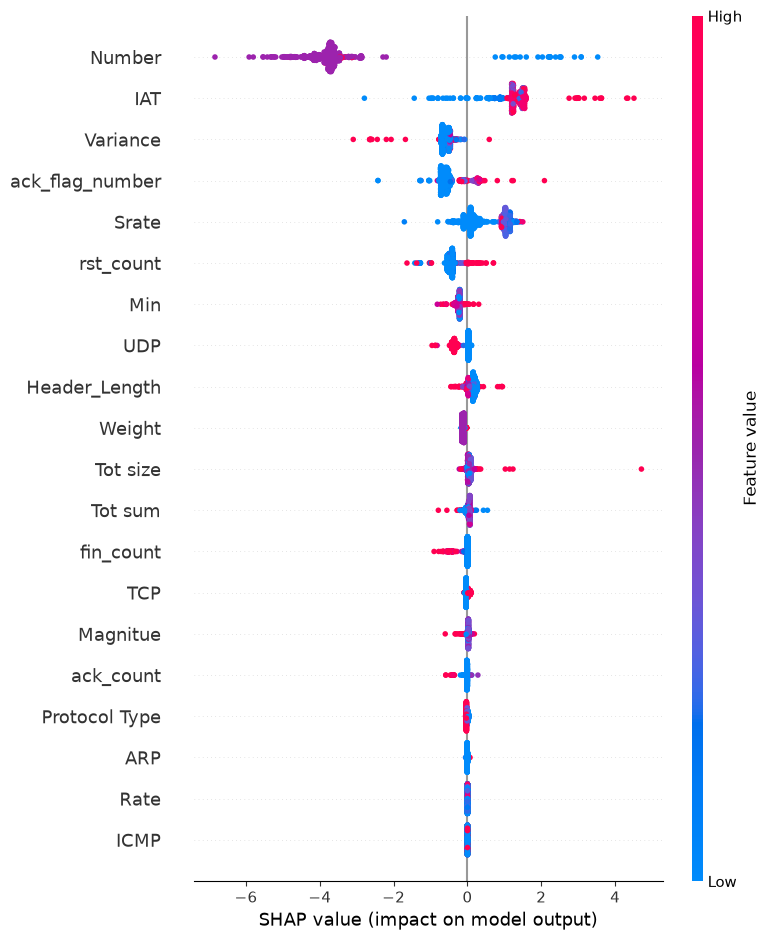

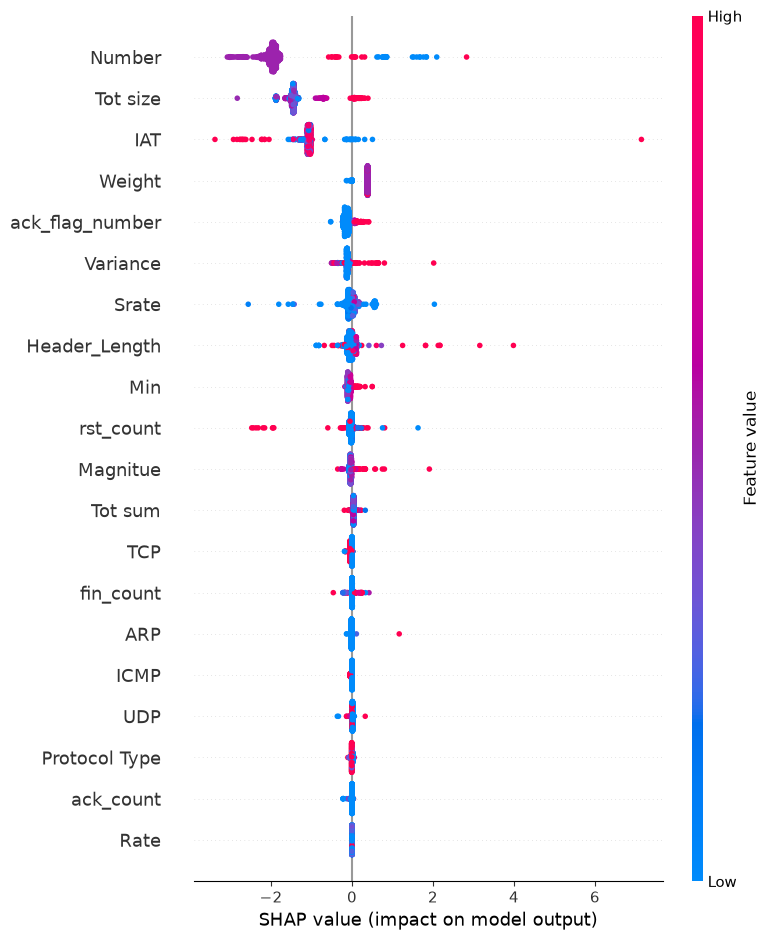

In [32]:
shap.summary_plot(shap_values[:, :, 1], X_explain, max_display = 20)
shap.summary_plot(shap_values[:, :, 3], X_explain, max_display = 20)
shap.summary_plot(shap_values[:, :, 5], X_explain, max_display = 20)

In [33]:
import numpy as np
import shap
import matplotlib.pyplot as plt

sample_idx = 0
class_names = dict(enumerate(target_encoder.classes_))

sample = X_explain.iloc[[sample_idx]]
predicted_class = int(xgb_best.predict(sample)[0])
actual_class = int(Y_test.loc[sample.index[0]]) if sample.index[0] in Y_test.index else None

print("Predicted class:", class_names[predicted_class])
print("Predicted label:", predicted_class)

Predicted class: DDoS
Predicted label: 1


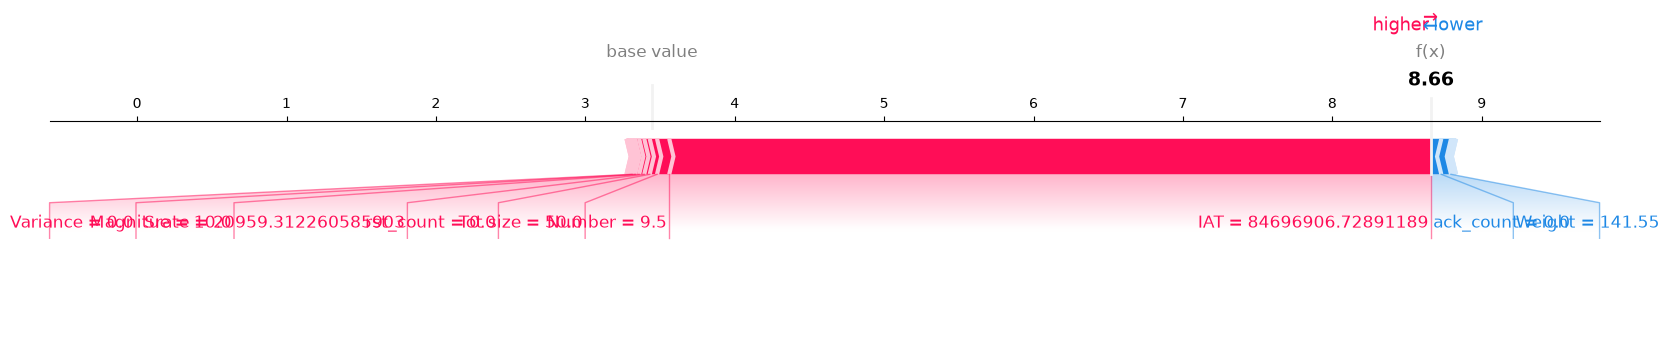

In [34]:
shap.force_plot(
    explainer.expected_value[predicted_class],
    shap_values[sample_idx, :, predicted_class],
    X_explain.iloc[sample_idx],
    matplotlib = True
)

plt.show()

In [35]:
shap.initjs()

shap.force_plot(
    explainer.expected_value[1],
    shap_values[sample_idx, :, 1],
    X_explain.iloc[sample_idx]
)

In [36]:
import numpy as np

spoofing_positions = np.flatnonzero(np.asarray(Y_test) == 5)

spoofing_predictions = np.asarray(pred)[spoofing_positions]

correct_positions = spoofing_positions[spoofing_predictions == 5]

wrong_positions = spoofing_positions[spoofing_predictions != 5]

print("Correctly classified:", len(correct_positions))
print("Misclassified:", len(wrong_positions))

if len(correct_positions) > 0:
    correct_idx = correct_positions[0]
    print("Correct sample position:", correct_idx)

if len(wrong_positions) > 0:
    wrong_idx = wrong_positions[0]
    print("Misclassified sample position:", wrong_idx)
    print("Predicted label:", int(np.asarray(pred)[wrong_idx]))

Correctly classified: 1659
Misclassified: 85
Correct sample position: 0
Misclassified sample position: 8
Predicted label: 4


In [37]:
correct_idx = correct_positions[0]
wrong_idx = wrong_positions[0]

print("Correct sample's test index:", Y_test.index[correct_idx])

print("Misclassified sample's test index:", Y_test.index[wrong_idx])

print("Are both in X_explain?", Y_test.index[correct_idx] in X_explain.index, Y_test.index[wrong_idx] in X_explain.index)

Correct sample's test index: 0
Misclassified sample's test index: 8
Are both in X_explain? False False


In [38]:
X_correct = X_test_top.loc[[Y_test.index[correct_idx]]]
X_wrong = X_test_top.loc[[Y_test.index[wrong_idx]]]

shap_correct = explainer.shap_values(X_correct)
shap_wrong = explainer.shap_values(X_wrong)

print("Correct sample shape:", X_correct.shape)
print("Misclassified sample shape:", X_wrong.shape)
print("SHAP calculation complete.")

Correct sample shape: (1, 20)
Misclassified sample shape: (1, 20)
SHAP calculation complete.


In [39]:
shap.initjs()

shap.force_plot(
    explainer.expected_value[5],
    shap_correct[0, :, 5],
    X_correct.iloc[0]
)

In [40]:
shap.force_plot(
    explainer.expected_value[5],
    shap_wrong[0, :, 5],
    X_wrong.iloc[0]
)

In [41]:
shap.force_plot(
    explainer.expected_value[4],
    shap_wrong[0, :, 4],
    X_wrong.iloc[0]
)

In [42]:
proba = xgb_best.predict_proba(X_wrong)[0]
raw_scores = xgb_best.predict(X_wrong, output_margin = True)[0]

for i, name in enumerate(target_encoder.classes_):
    print(f"{name}: "f"raw score = {raw_scores[i]:.4f}, "f"probability = {proba[i]:.4%}")

Benign: raw score = 2.9866, probability = 38.9569%
DDoS: raw score = -2.0406, probability = 0.2554%
DoS: raw score = -2.6921, probability = 0.1332%
MQTT: raw score = -5.4190, probability = 0.0087%
Recon: raw score = 3.2277, probability = 49.5795%
Spoofing: raw score = 1.7280, probability = 11.0663%


In [43]:
correct_proba = xgb_best.predict_proba(X_correct)[0]
correct_scores = xgb_best.predict(X_correct, output_margin = True)[0]

for i, name in enumerate(target_encoder.classes_):
    print(f"{name}: "f"raw score = {correct_scores[i]:.4f}, "f"probability = {correct_proba[i]:.4%}")

Benign: raw score = 0.2479, probability = 0.0000%
DDoS: raw score = -2.1663, probability = 0.0000%
DoS: raw score = -2.4397, probability = 0.0000%
MQTT: raw score = 0.4603, probability = 0.0000%
Recon: raw score = 0.8235, probability = 0.0000%
Spoofing: raw score = 22.9882, probability = 100.0000%


In [44]:
import numpy as np
import pandas as pd
import gc
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score

baseline_pred = xgb_best.predict(X_test_top)

results = [{
    "Experiment": "Baseline (20 features)",
    "Accuracy": accuracy_score(Y_test, baseline_pred),
    "Macro F1": f1_score(Y_test, baseline_pred, average = "macro"),
    "Macro Recall": recall_score(Y_test, baseline_pred, average = "macro", zero_division = 0)
}]

experiments = {
    "Without IAT": [c for c in X_train_top.columns if c != "IAT"],
    "Without Header_Length": [c for c in X_train_top.columns if c != "Header_Length"],
    "Without both": [c for c in X_train_top.columns if c not in ["IAT", "Header_Length"]]
}

for name, features in experiments.items():
    print(f"\nTraining {name}...")

    model = XGBClassifier(
        n_estimators = 100,
        max_depth = 8,
        learning_rate = 0.1,
        objective = "multi:softprob",
        eval_metric = "mlogloss",
        random_state = 42,
        n_jobs = 2
    )

    model.fit(X_train_top[features], Y_train)

    pred = model.predict(X_test_top[features])

    results.append({
        "Experiment": name,
        "Accuracy": accuracy_score(Y_test, pred),
        "Macro F1": f1_score(Y_test, pred, average = "macro"),
        "Macro Recall": recall_score(Y_test, pred, average = "macro", zero_division = 0)
    })

    del model, pred
    gc.collect()

print("\n--- ABLATION RESULTS ---")
results_df = pd.DataFrame(results)
print(results_df.round(4).to_string(index = False))

del baseline_pred
gc.collect()


Training Without IAT...

Training Without Header_Length...

Training Without both...

--- ABLATION RESULTS ---
            Experiment  Accuracy  Macro F1  Macro Recall
Baseline (20 features)    0.9977    0.9149        0.8973
           Without IAT    0.8069    0.7404        0.7037
 Without Header_Length    0.9980    0.9067        0.9097
          Without both    0.7971    0.7261        0.6837


0

In [45]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report
import gc

features_no_header = [c for c in X_train_top.columns if c != "Header_Length"]

xgb_no_header = XGBClassifier(
    n_estimators = 100,
    max_depth = 8,
    learning_rate = 0.1,
    objective = "multi:softprob",
    eval_metric = "mlogloss",
    random_state = 42,
    n_jobs = 2
)

xgb_no_header.fit(X_train_top[features_no_header], Y_train)

pred = xgb_no_header.predict(X_test_top[features_no_header])

print("WITHOUT Header_Length")
print(classification_report(Y_test, pred, labels= [0, 1, 2, 3, 4, 5], 
    target_names = ["Benign", "DDoS", "DoS", "MQTT", "Recon", "Spoofing"],
    digits = 4,
    zero_division = 0
))

del pred
gc.collect()

WITHOUT Header_Length
              precision    recall  f1-score   support

      Benign     0.9630    0.9723    0.9676     37607
        DDoS     0.9996    0.9999    0.9998   1117094
         DoS     0.9998    0.9989    0.9994    428312
        MQTT     0.9809    0.7922    0.8765      1747
       Recon     0.9946    0.9701    0.9822     25613
    Spoofing     0.5338    0.7248    0.6148      1744

    accuracy                         0.9980   1612117
   macro avg     0.9119    0.9097    0.9067   1612117
weighted avg     0.9982    0.9980    0.9981   1612117



53

In [46]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report
import gc

features_no_iat = [c for c in X_train_top.columns if c != "IAT"]

xgb_no_iat = XGBClassifier(
    n_estimators = 100,
    max_depth = 8,
    learning_rate = 0.1,
    objective = "multi:softprob",
    eval_metric = "mlogloss",
    random_state = 42,
    n_jobs = 2
)

xgb_no_iat.fit(X_train_top[features_no_iat], Y_train)

pred = xgb_no_iat.predict(X_test_top[features_no_iat])

print("WITHOUT IAT")
print(classification_report(Y_test, pred, labels = [0, 1, 2, 3, 4, 5],
    target_names = ["Benign", "DDoS", "DoS", "MQTT", "Recon", "Spoofing"],
    digits = 4,
    zero_division = 0
))

del pred
gc.collect()

WITHOUT IAT
              precision    recall  f1-score   support

      Benign     0.9286    0.9592    0.9437     37607
        DDoS     0.8183    0.9330    0.8719   1117094
         DoS     0.7255    0.4595    0.5626    428312
        MQTT     0.9580    0.5358    0.6872      1747
       Recon     0.9285    0.9410    0.9347     25613
    Spoofing     0.5044    0.3939    0.4424      1744

    accuracy                         0.8069   1612117
   macro avg     0.8106    0.7037    0.7404   1612117
weighted avg     0.7978    0.8069    0.7917   1612117



53

In [47]:
import os
import joblib

os.makedirs('CICIoMT2024_Working/Models', exist_ok = True)

joblib.dump(xgb_best, 'CICIoMT2024_Working/Models/xgboost_final.pkl')

feature_names = X_train_top.columns.tolist()

joblib.dump(feature_names, 'CICIoMT2024_Working/Models/feature_names.pkl')
joblib.dump(target_encoder, 'CICIoMT2024_Working/Models/target_encoder.pkl')

print('CICIoMT2024 model and preprocessing files saved successfully.')

CICIoMT2024 model and preprocessing files saved successfully.
